# Step 0: Load necessary libraries.

In [10]:
!pip install --upgrade scikit-learn>=1.6.1
!pip install category_encoders>=2.8.1
!pip install lightgbm
!pip install thundersvm
!pip install optuna
!pip install --upgrade xgboost>=2.1.4

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
category-encoders 2.7.0 requires scikit-learn<1.6.0,>=1.0.0, but you have scikit-learn 1.6.1 which is incompatible.
bigframes 1.36.0 requires rich<14,>=12.4.4, but you have rich 14.0.0 which is incompatible.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 1.36.0 requires rich<14,>=12.4.4, but you have rich 14.0.0 which is incompatible.


In [11]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

###  Step 1: Load the Dataset

We will use the **Adult Income dataset** from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/datasets/adult).  
This dataset is used to predict whether a person earns more than \$50K a year based on their demographic information.

The dataset includes:
- A **training set** (`adult.data`)
- A **test set** (`adult.test`)

Then do the following:
1. Use `.shape` to check how many rows and columns the dataset has.
2. Use `.head()` to display the first few rows of the dataset.

In [ ]:

train_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"


columns = [
    'age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status',
    'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss',
    'hours-per-week', 'native-country', 'income'
]


df_train = pd.read_csv(
    train_url,
    header=None,
    names=columns,
    na_values='?',
    skipinitialspace=True
)

print("Training set shape:", df_train.shape)
df_train.head()


Training set shape: (32561, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


# Step 2: Load and Clean the Test Dataset

The test dataset is very similar to the training dataset but has:
- A header row that we should skip
- `income` labels that include a period at the end, like `>50K.`

We will:
- Load the data
- Use the same column names
- Clean the `income` column by removing periods and extra spaces


In [ ]:

test_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.test"


df_test = pd.read_csv(
    test_url,
    header=None,
    names=columns,
    skiprows=1,            
    na_values='?',
    skipinitialspace=True
)

print("Test set shape:", df_test.shape)
df_test.head()


Test set shape: (16281, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K.
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K.
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K.
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K.
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K.



You might see that `.head()` shows **2 unique values** in both the training and test sets for the `income` column.  

But are those labels *exactly the same* in both datasets?

Let’s check more closely:

```python
print("Train labels:", df_train['income'].unique())
print("Test labels:", df_test['income'].unique())
```

Take a careful look at the test labels — is there an extra character at the end?

---

###  Why This Matters

This tiny difference (a period `"."` at the end) might not look like a big deal, but it actually means the test labels are **different strings**.  
If we don’t fix this, your model could get confused — it might think `'>50K'` and `'>50K.'` are two different classes!

Even though your code might still run, your **accuracy will be wrong** if the labels don’t match.

---

###  Fix it!

Can you figure out how to **clean the labels** so the train and test values match?



In [14]:
print("Train labels:", df_train['income'].unique())
print("Test labels:", df_test['income'].unique())

Train labels: ['<=50K' '>50K']
Test labels: ['<=50K.' '>50K.']


In [15]:
df_test['income'] = df_test['income'].str.rstrip('.')
df_test['income'] = df_test['income'].str.lstrip('.')

print("Train labels:", df_train['income'].unique())
print("Test labels:", df_test['income'].unique())

Train labels: ['<=50K' '>50K']
Test labels: ['<=50K' '>50K']


# Step 3: Explore the Dataset

Now that we've loaded the dataset, it's time to explore it!
<br/>
In Data Science, Exploratory Data Analysis (EDA) is the process of analyzing datasets to summarize their main characteristics—often using statistical graphics, plots, and other visualization tools.
<br/>
<br/>
EDA typically involves two main parts:
- Numerical statistics
- Visual analysis


## Numerical statistics

First, we’ll try to get some basic numerical insights from the dataset
<br/>
We’ll use:
- `describe` -- to get statistics like mean, standard deviation, min, max, and quartiles for the numerical features.
- `info` --  to get an overview of the dataset structure, including feature names, data types, non-null counts, and memory usage.
- `head(n)` – shows the first n rows of the dataset (default is 5). Great for a quick glance at the data.

- `shape` – returns a tuple showing the number of rows and columns.

- `value_counts()` – shows frequency counts for unique values in a column (great for categorical data).

- `isnull().sum()` – helps identify missing values per column.

- `duplicated().sum()` – shows total number of duplicated values.

In [ ]:

print("===== Training Dataset Information =====")
print("\nDataset Info:")
print(df_train.info())

print("\nNumerical Features Statistics:")
print(df_train.describe())

print("\nMissing Values in Training Set:")
print(df_train.isnull().sum())

print("\nDuplicated Rows in Training Set:", df_train.duplicated().sum())

print("\nValue Counts for 'income' in Training Set:")
print(df_train['income'].value_counts())

print("\n===== Test Dataset Information =====")
print("\nDataset Info:")
print(df_test.info())

print("\nMissing Values in Test Set:")
print(df_test.isnull().sum())

print("\nDuplicated Rows in Test Set:", df_test.duplicated().sum())

print("\nValue Counts for 'income' in Test Set:")
print(df_test['income'].value_counts())

===== Training Dataset Information =====

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education-num   32561 non-null  int64 
 5   marital-status  32561 non-null  object
 6   occupation      30718 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital-gain    32561 non-null  int64 
 11  capital-loss    32561 non-null  int64 
 12  hours-per-week  32561 non-null  int64 
 13  native-country  31978 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB
None

Numerical Features Statistics:


### Check for Missing Values

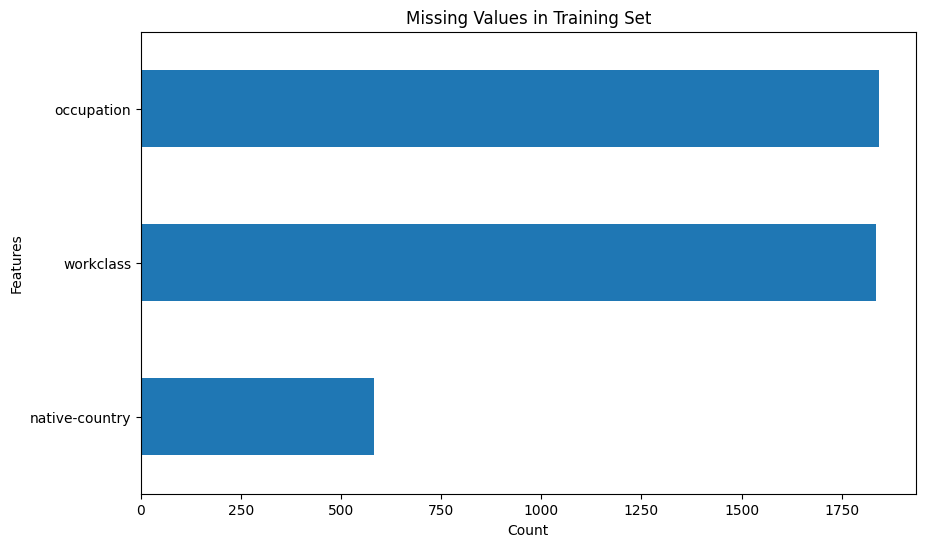

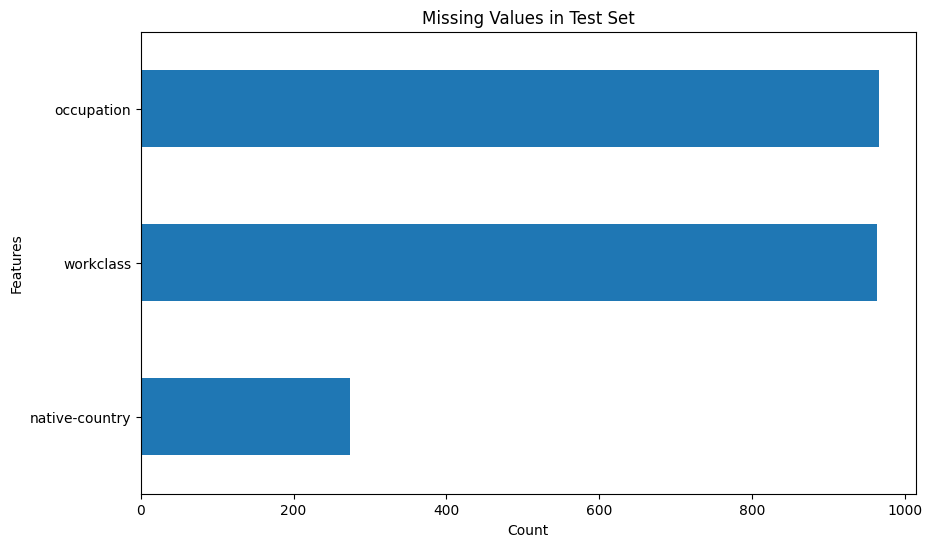


Percentage of missing values in Training Set:
workclass         5.64
occupation        5.66
native-country    1.79
dtype: float64

Percentage of missing values in Test Set:
workclass         5.91
occupation        5.93
native-country    1.68
dtype: float64


In [ ]:

def plot_missing_values(df, title):
    plt.figure(figsize=(10, 6))
    missing = df.isnull().sum()
    missing = missing[missing > 0]
    missing.sort_values(ascending=True, inplace=True)

    if len(missing) > 0:
        missing.plot(kind='barh')
        plt.title(f'Missing Values in {title}')
        plt.xlabel('Count')
        plt.ylabel('Features')
        plt.show()
    else:
        print(f"No missing values found in {title}")

plot_missing_values(df_train, 'Training Set')
plot_missing_values(df_test, 'Test Set')


print("\nPercentage of missing values in Training Set:")
print((df_train.isnull().sum() / len(df_train) * 100).round(2)[df_train.isnull().sum() > 0])

print("\nPercentage of missing values in Test Set:")
print((df_test.isnull().sum() / len(df_test) * 100).round(2)[df_test.isnull().sum() > 0])

### Check for Duplicates

In [ ]:

def analyze_duplicates(df, dataset_name):
    n_duplicates = df.duplicated().sum()
    print(f"\nAnalyzing duplicates in {dataset_name}:")
    print(f"Number of duplicate rows: {n_duplicates}")
    print(f"Percentage of duplicate rows: {(n_duplicates/len(df)*100):.2f}%")

    if n_duplicates > 0:
        print("\nFirst few duplicate rows:")
        print(df[df.duplicated(keep='first')].head())


analyze_duplicates(df_train, "Training Set")
analyze_duplicates(df_test, "Test Set")


Analyzing duplicates in Training Set:
Number of duplicate rows: 24
Percentage of duplicate rows: 0.07%

First few duplicate rows:
       age workclass  fnlwgt     education  education-num marital-status  \
4881    25   Private  308144     Bachelors             13  Never-married   
5104    90   Private   52386  Some-college             10  Never-married   
9171    21   Private  250051  Some-college             10  Never-married   
11631   20   Private  107658  Some-college             10  Never-married   
13084   25   Private  195994       1st-4th              2  Never-married   

            occupation   relationship                race     sex  \
4881      Craft-repair  Not-in-family               White    Male   
5104     Other-service  Not-in-family  Asian-Pac-Islander    Male   
9171    Prof-specialty      Own-child               White  Female   
11631     Tech-support  Not-in-family               White  Female   
13084  Priv-house-serv  Not-in-family               White  Female  

## Visual analysis

The first step in visual analysis is to explore the distributions of features in the dataset. This helps us understand the shape of the data, detect outliers, and identify potential data quality issues or patterns.
<br/>
Common approaches include:
<br/>
- Bar plots – great for visualizing the distribution of categorical variables.

- Histograms – useful for showing the frequency distribution of numerical features.

- Box plots – helpful to spot outliers and understand the spread and skewness of data.

- Count plots – a variant of bar plots, often used with categorical data.

- KDE plots (Kernel Density Estimation) – smooth curves that estimate the probability distribution of a numerical variable.

- Pie charts – sometimes used for simple categorical distribution, though not always preferred.

### Visualizing the Target Variable


Since our target variable (`income`) is categorical, we can use a count plot to visualize its distribution. This helps us understand the class balance (e.g., whether the data is imbalanced):


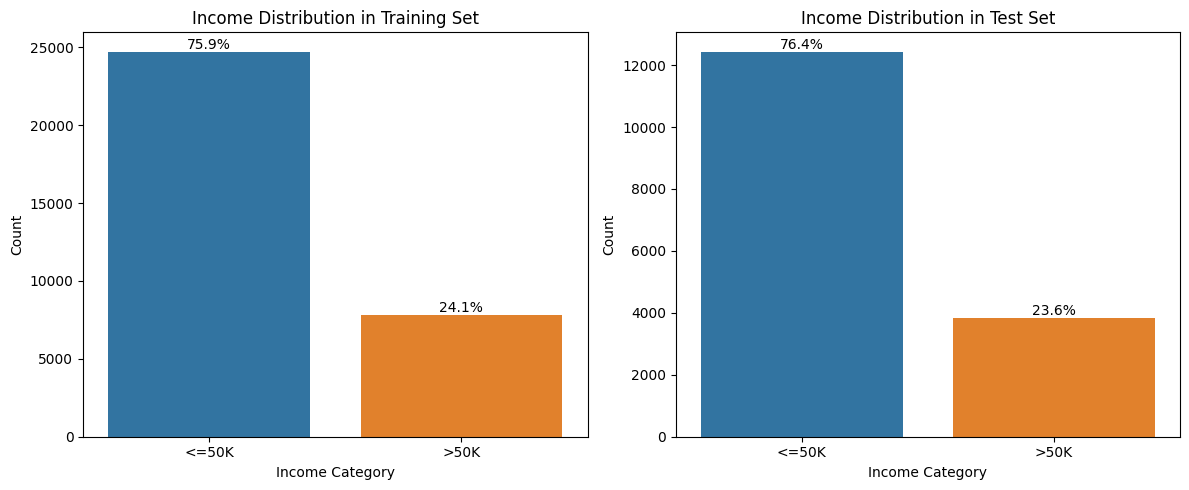


Training Set Distribution:
income
<=50K    24720
>50K      7841
Name: count, dtype: int64

Percentages:
income
<=50K    75.919044
>50K     24.080956
Name: count, dtype: float64

Test Set Distribution:
income
<=50K    12435
>50K      3846
Name: count, dtype: int64

Percentages:
income
<=50K    76.377372
>50K     23.622628
Name: count, dtype: float64


In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.countplot(data=df_train, x='income')
plt.title('Income Distribution in Training Set')
plt.xlabel('Income Category')
plt.ylabel('Count')

total = len(df_train)
for p in plt.gca().patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    plt.annotate(percentage, (p.get_x() + p.get_width()/2., p.get_height()),
                ha='center', va='bottom')

plt.subplot(1, 2, 2)
sns.countplot(data=df_test, x='income')
plt.title('Income Distribution in Test Set')
plt.xlabel('Income Category')
plt.ylabel('Count')

total = len(df_test)
for p in plt.gca().patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    plt.annotate(percentage, (p.get_x() + p.get_width()/2., p.get_height()),
                ha='center', va='bottom')

plt.tight_layout()
plt.show()


print("\nTraining Set Distribution:")
train_dist = df_train['income'].value_counts()
print(train_dist)
print("\nPercentages:")
print(train_dist/len(df_train)*100)

print("\nTest Set Distribution:")
test_dist = df_test['income'].value_counts()
print(test_dist)
print("\nPercentages:")
print(test_dist/len(df_test)*100)

### Exploring Education Level Distribution


Now, let's check the distribution of education levels in the dataset. This gives us insight into the average persona or demographic represented in the data

---
Answer the following questions:
- What is the most earned degree among participants?
- Is there a connection between education level and income?


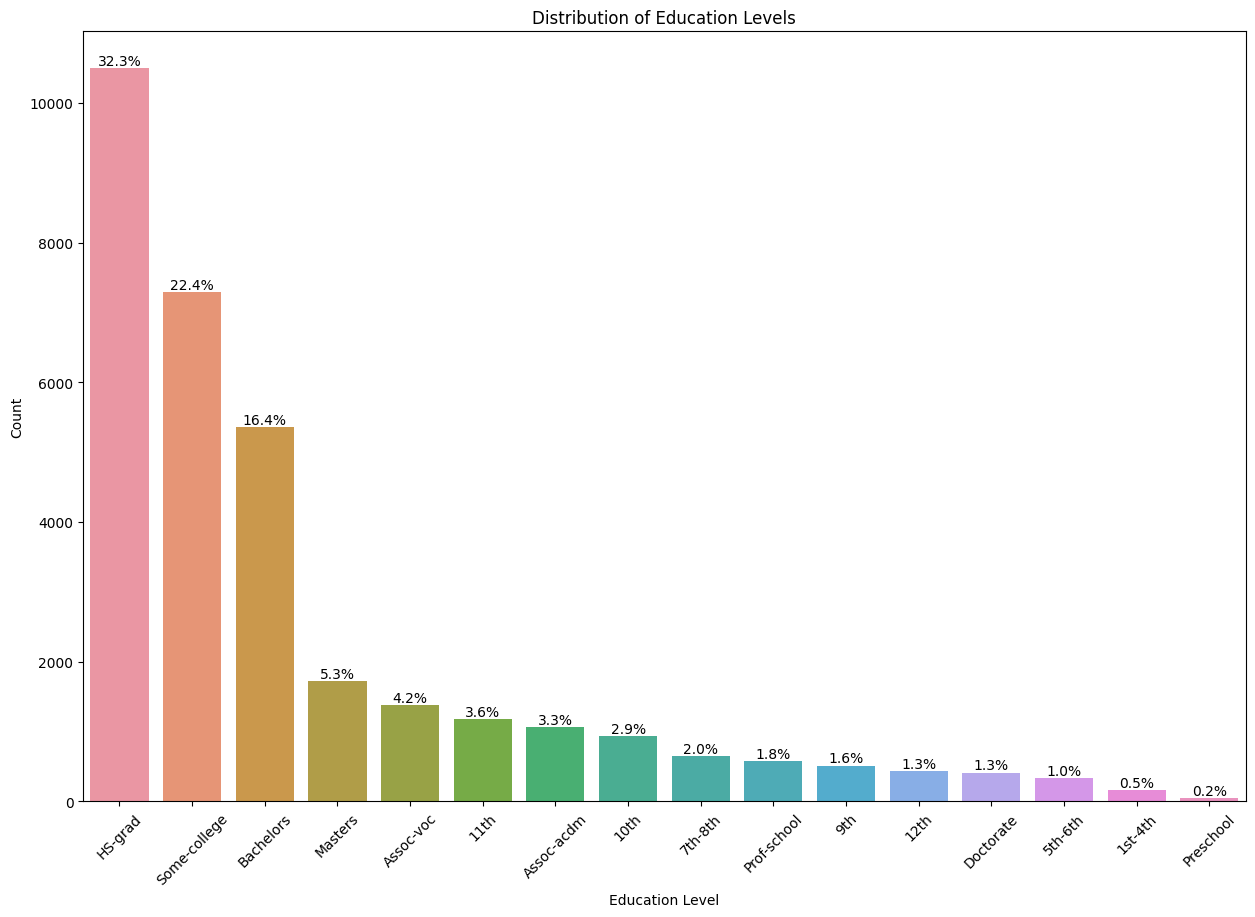

In [ ]:
plt.figure(figsize=(15, 10))


plt.plot(1,1,1)
education_counts = df_train['education'].value_counts()
sns.barplot(x=education_counts.index, y=education_counts.values)
plt.title('Distribution of Education Levels')
plt.xlabel('Education Level')
plt.ylabel('Count')
plt.xticks(rotation=45)


total = len(df_train)
for i, v in enumerate(education_counts.values):
    percentage = f'{100 * v / total:.1f}%'
    plt.text(i, v, percentage, ha='center', va='bottom')

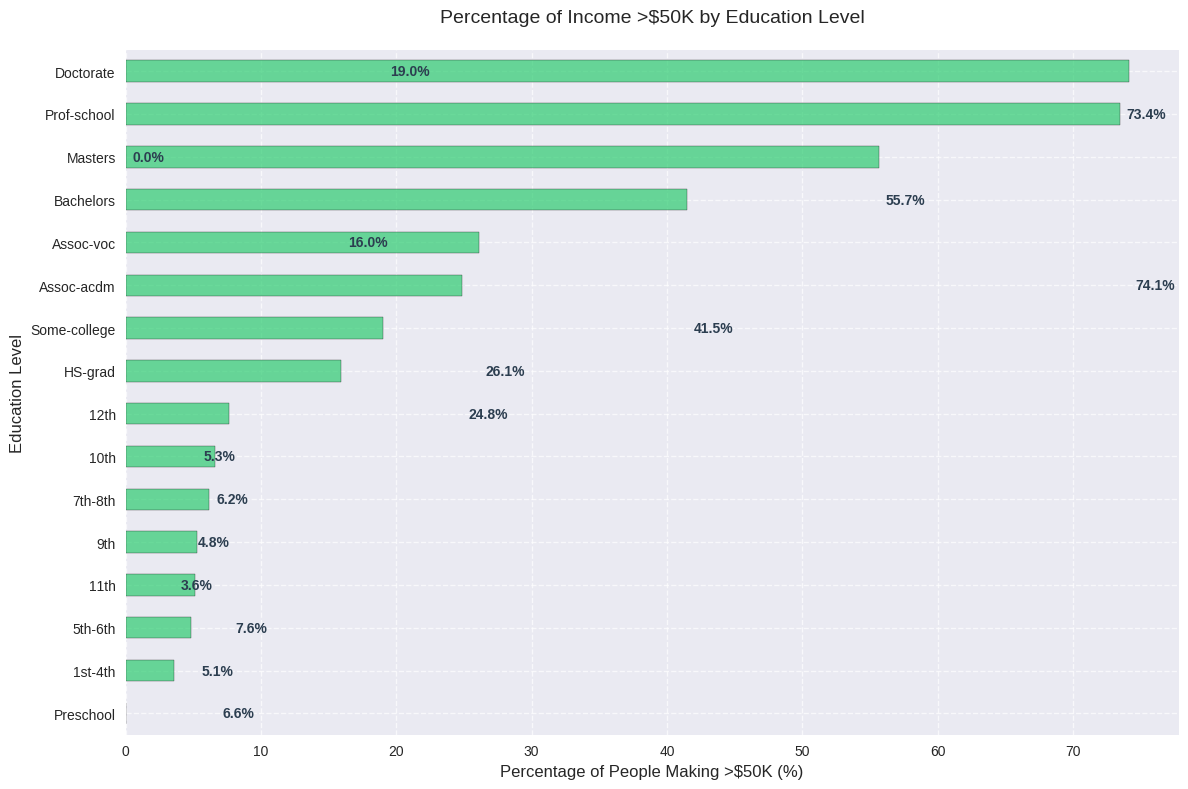


=== Education Level Statistics ===

Top 3 Most Common Education Levels:
----------------------------------------
1. HS-grad           10,501 students
2. Some-college       7,291 students
3. Bachelors          5,355 students

Top 3 Education Levels with Highest Income (>$50K):
-------------------------------------------------------
1. Doctorate           74.1% earn more than $50K
2. Prof-school         73.4% earn more than $50K
3. Masters             55.7% earn more than $50K


In [ ]:

plt.figure(figsize=(12, 8))
plt.style.use('seaborn-v0_8')

education_income = pd.crosstab(df_train['education'], df_train['income'], normalize='index') * 100

ax = education_income['>50K'].sort_values(ascending=True).plot(
    kind='barh',
    color='#2ecc71',
    alpha=0.7,
    edgecolor='black'
)

plt.title('Percentage of Income >$50K by Education Level', fontsize=14, pad=20)
plt.xlabel('Percentage of People Making >$50K (%)', fontsize=12)
plt.ylabel('Education Level', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)


plt.xticks(fontsize=10)
plt.yticks(fontsize=10)


for i, v in enumerate(education_income['>50K']):
    plt.text(v + 0.5, i, f'{v:.1f}%',
             va='center',
             fontsize=10,
             fontweight='bold',
             color='#2c3e50')


plt.tight_layout()

plt.show()


print("\n=== Education Level Statistics ===")
print("\nTop 3 Most Common Education Levels:")
print("-" * 40)
for i, (level, count) in enumerate(education_counts.head(3).items(), 1):
    print(f"{i}. {level:<15} {count:>8,} students")

print("\nTop 3 Education Levels with Highest Income (>$50K):")
print("-" * 55)
top_income = education_income['>50K'].sort_values(ascending=False).head(3)
for i, (level, percentage) in enumerate(top_income.items(), 1):
    print(f"{i}. {level:<15} {percentage:>8.1f}% earn more than $50K")

<p align="justify">
<font size=4>
<b> <font color='red'>Your Answer:</font></b><br>


</p>
</font>
<hr>

HS-GRADE
The higher your education becomes, you are more likely to earn more than 50k.

### Exploring the Relationship Between Nationality and Income

Exploring the income distribution across different nationalities reveals trends in earnings. This analysis can highlight which nationalities are more likely to earn higher income, providing insights into the potential socio-economic factors associated with nationality in the dataset

---

Tasks:
- Plot Nationality Distribution
- Compare Nationality vs. Income
- Identify Dominant Nationality with Highest Income Proportion

#### Task 1: Plot Nationality Distribution

Visualize the distribution of nationalities in the dataset to understand the representation of individuals from different countries. This will help in assessing the relative population of each nationality before comparing their income distributions


Nationality Distribution Statistics:
----------------------------------------
Total number of individuals: 31,978
United States: 29,170 (91.2%)
Other Countries: 2,808 (8.8%)


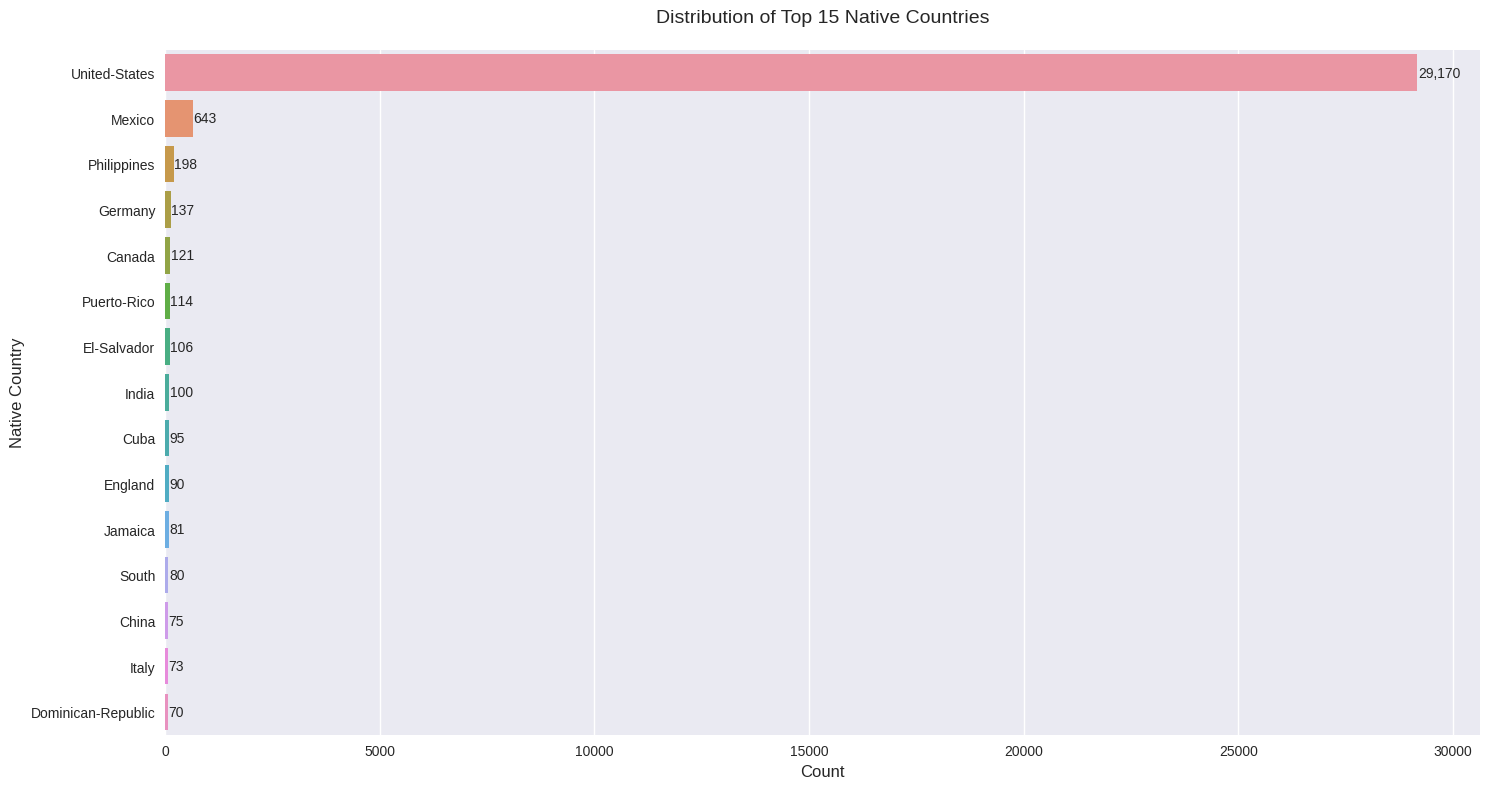


Detailed Country Distribution:
----------------------------------------
United-States         29,170 (91.22%)
Mexico                   643 ( 2.01%)
Philippines              198 ( 0.62%)
Germany                  137 ( 0.43%)
Canada                   121 ( 0.38%)
Puerto-Rico              114 ( 0.36%)
El-Salvador              106 ( 0.33%)
India                    100 ( 0.31%)
Cuba                      95 ( 0.30%)
England                   90 ( 0.28%)
Jamaica                   81 ( 0.25%)
South                     80 ( 0.25%)
China                     75 ( 0.23%)
Italy                     73 ( 0.23%)
Dominican-Republic        70 ( 0.22%)
Vietnam                   67 ( 0.21%)
Guatemala                 64 ( 0.20%)
Japan                     62 ( 0.19%)
Poland                    60 ( 0.19%)
Columbia                  59 ( 0.18%)
Taiwan                    51 ( 0.16%)
Haiti                     44 ( 0.14%)
Iran                      43 ( 0.13%)
Portugal                  37 ( 0.12%)
Nicaragua      

In [ ]:
plt.figure(figsize=(15, 8))


nationality_counts = df_train['native-country'].value_counts()

sns.barplot(x=nationality_counts.head(15).values,
           y=nationality_counts.head(15).index)

plt.title('Distribution of Top 15 Native Countries', fontsize=14, pad=20)
plt.xlabel('Count', fontsize=12)
plt.ylabel('Native Country', fontsize=12)

for i, v in enumerate(nationality_counts.head(15)):
    plt.text(v + 10, i, f'{v:,}', va='center')


us_count = nationality_counts['United-States']
total_count = nationality_counts.sum()
us_percentage = (us_count / total_count) * 100
other_percentage = 100 - us_percentage

print("\nNationality Distribution Statistics:")
print("-" * 40)
print(f"Total number of individuals: {total_count:,}")
print(f"United States: {us_count:,} ({us_percentage:.1f}%)")
print(f"Other Countries: {total_count - us_count:,} ({other_percentage:.1f}%)")

plt.tight_layout()
plt.show()

print("\nDetailed Country Distribution:")
print("-" * 40)
country_percentages = (nationality_counts / total_count * 100).round(2)
for country, percentage in country_percentages.items():
    count = nationality_counts[country]
    print(f"{country:<20} {count:>7,} ({percentage:>5.2f}%)")

#### Task 2: Compare Nationality vs. Income

Compare the income levels (`<=50K` and `>50K`) across different nationalities. This analysis will show how income distribution varies by nationality, helping to identify trends in income disparity among different nationalities.

<Figure size 1500x1000 with 0 Axes>

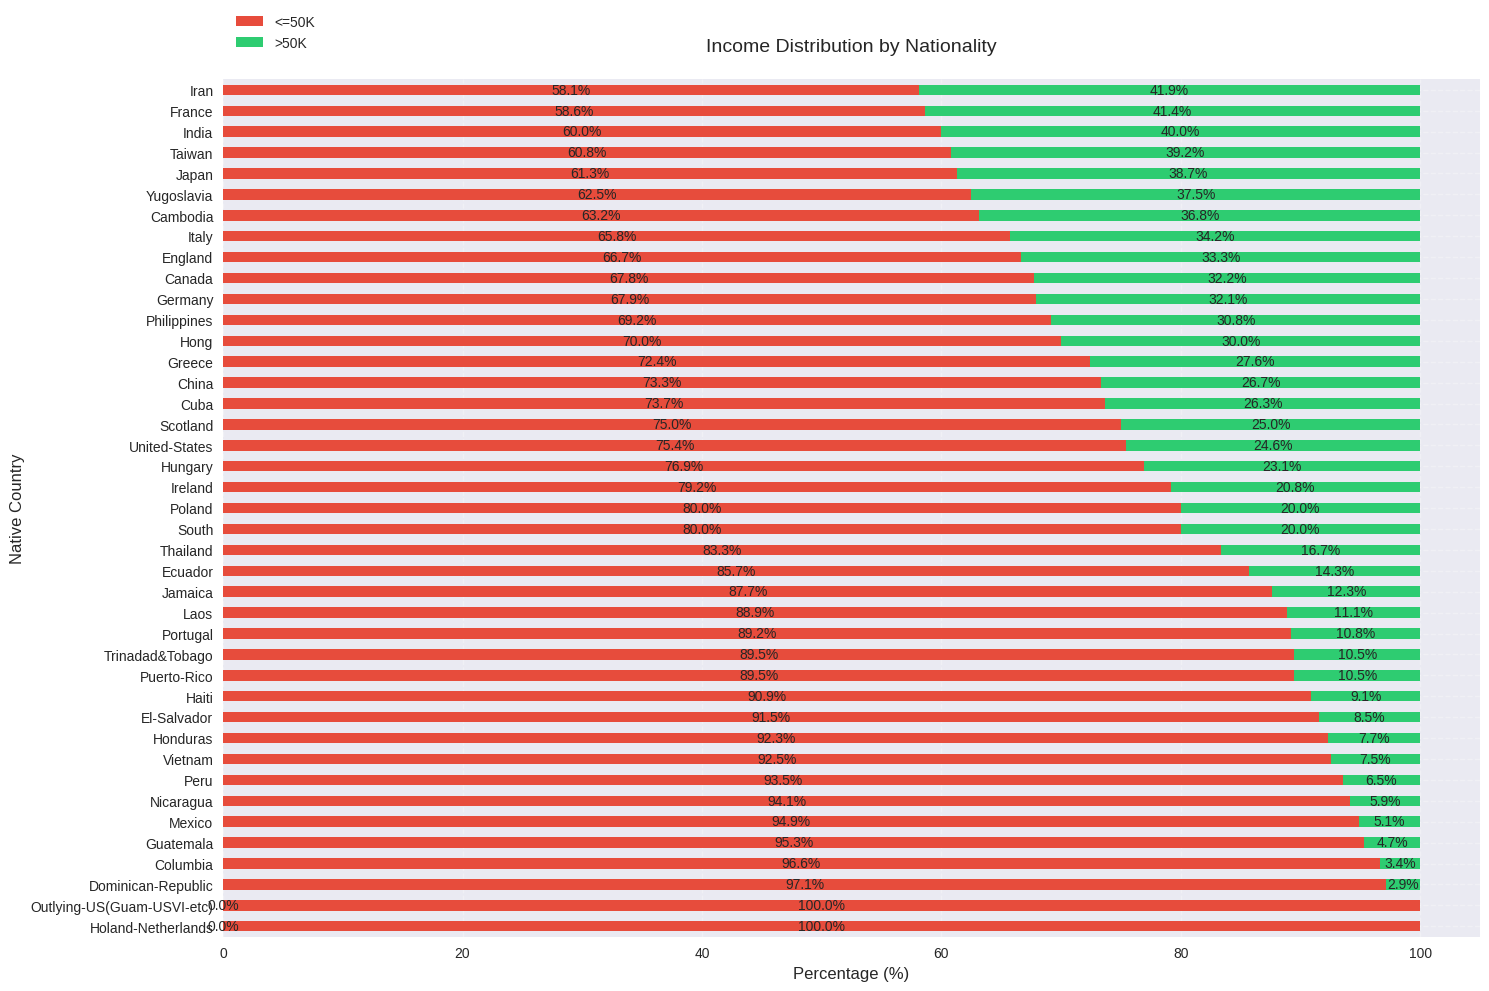


Top 5 Countries with Highest Percentage of >$50K Income:
------------------------------------------------------------
Japan                  38.7% of    62 people earn >$50K
Taiwan                 39.2% of    51 people earn >$50K
India                  40.0% of   100 people earn >$50K
France                 41.4% of    29 people earn >$50K
Iran                   41.9% of    43 people earn >$50K

Top 5 Countries with Lowest Percentage of >$50K Income:
------------------------------------------------------------
Holand-Netherlands      0.0% of     1 people earn >$50K
Outlying-US(Guam-USVI-etc)    0.0% of    14 people earn >$50K
Dominican-Republic      2.9% of    70 people earn >$50K
Columbia                3.4% of    59 people earn >$50K
Guatemala               4.7% of    64 people earn >$50K

Average percentage of >$50K income across all countries: 20.2%


In [ ]:
plt.figure(figsize=(15, 10))

nationality_income = pd.crosstab(df_train['native-country'], df_train['income'], normalize='index') * 100


nationality_income_sorted = nationality_income.sort_values(by='>50K', ascending=True)

ax = nationality_income_sorted.plot(
    kind='barh',
    stacked=True,
    color=['#e74c3c', '#2ecc71'],
    figsize=(15, 10),
    legend=True
)

plt.legend(bbox_to_anchor=(0.0, 1.02), loc='lower left')

plt.title('Income Distribution by Nationality', fontsize=14, pad=20)
plt.xlabel('Percentage (%)', fontsize=12)
plt.ylabel('Native Country', fontsize=12)


for i in ax.containers:
    ax.bar_label(i, fmt='%.1f%%', label_type='center')


plt.grid(True, linestyle='--', alpha=0.3)


plt.tight_layout()


plt.show()


print("\nTop 5 Countries with Highest Percentage of >$50K Income:")
print("-" * 60)
top_5_high = nationality_income_sorted['>50K'].tail(5)
for country, percentage in top_5_high.items():
    count = len(df_train[df_train['native-country'] == country])
    print(f"{country:<20} {percentage:>6.1f}% of {count:>5} people earn >$50K")

print("\nTop 5 Countries with Lowest Percentage of >$50K Income:")
print("-" * 60)
bottom_5_high = nationality_income_sorted['>50K'].head(5)
for country, percentage in bottom_5_high.items():
    count = len(df_train[df_train['native-country'] == country])
    print(f"{country:<20} {percentage:>6.1f}% of {count:>5} people earn >$50K")


mean_income = nationality_income['>50K'].mean()
print(f"\nAverage percentage of >$50K income across all countries: {mean_income:.1f}%")

Filter out the dominant nationality (the one with the highest population proportion) and perform the analysis on the remaining nationalities. This will help focus on the income distribution across nationalities excluding the one with the most significant representation, offering a more nuanced view of the income distribution among less-represented nationalities.

---
Answer Following Question:
- Which nationality is the second most populous in America, and what is their income distribution? What factors might explain these income patterns?

<Figure size 1500x1000 with 0 Axes>

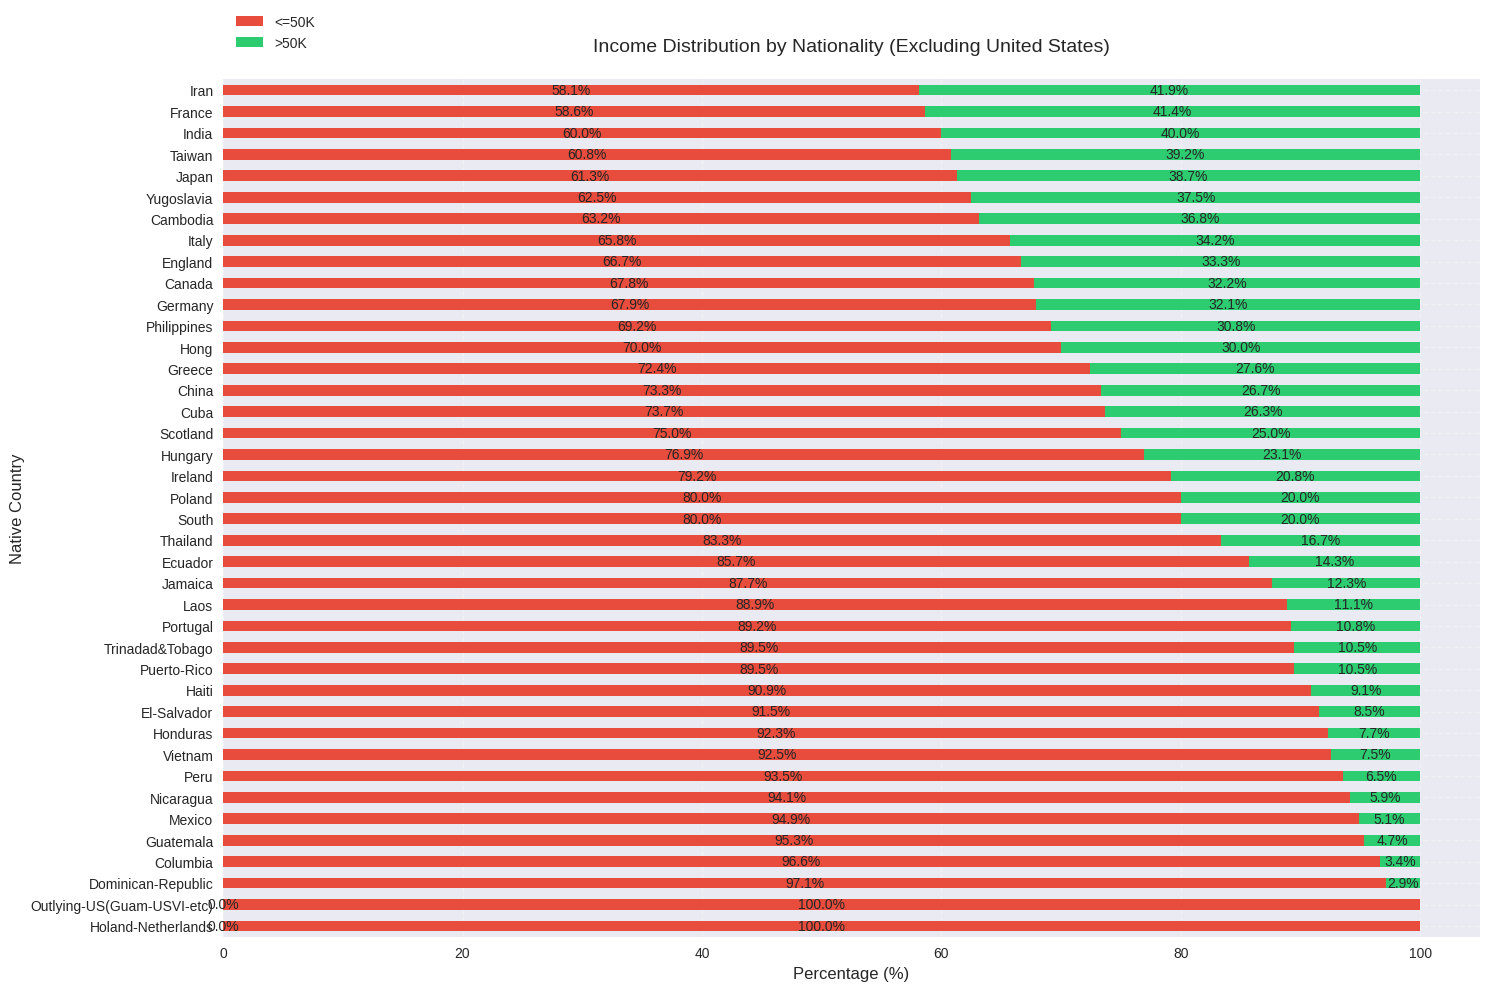


Top 5 Non-US Countries by Population:
------------------------------------------------------------
Mexico                 643 people (   5.1% earn >$50K)
Philippines            198 people (  30.8% earn >$50K)
Germany                137 people (  32.1% earn >$50K)
Canada                 121 people (  32.2% earn >$50K)
Puerto-Rico            114 people (  10.5% earn >$50K)

Income Statistics for Mexico (2nd most populous nationality):
------------------------------------------------------------
Total Mexican nationals: 643
Percentage earning <=50K: 94.9%
Percentage earning >50K: 5.1%

Average percentage of >$50K income across non-US countries: 20.1%


In [ ]:
plt.figure(figsize=(15, 10))


non_us_data = df_train[df_train['native-country'] != 'United-States'].copy()


non_us_income = pd.crosstab(non_us_data['native-country'],
                           non_us_data['income'],
                           normalize='index') * 100


non_us_income_sorted = non_us_income.sort_values(by='>50K', ascending=True)

ax = non_us_income_sorted.plot(
    kind='barh',
    stacked=True,
    color=['#e74c3c', '#2ecc71'],
    figsize=(15, 10),
    legend=True
)

plt.legend(bbox_to_anchor=(0.0, 1.02), loc='lower left')

plt.title('Income Distribution by Nationality (Excluding United States)', fontsize=14, pad=20)
plt.xlabel('Percentage (%)', fontsize=12)
plt.ylabel('Native Country', fontsize=12)


for i in ax.containers:
    ax.bar_label(i, fmt='%.1f%%', label_type='center')


plt.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()


plt.show()

non_us_counts = non_us_data['native-country'].value_counts()

print("\nTop 5 Non-US Countries by Population:")
print("-" * 60)
for country, count in non_us_counts.head().items():
    income_dist = non_us_income_sorted.loc[country]
    print(f"{country:<20} {count:>5} people ({income_dist['>50K']:>6.1f}% earn >$50K)")

print("\nIncome Statistics for Mexico (2nd most populous nationality):")
print("-" * 60)
mexico_data = non_us_data[non_us_data['native-country'] == 'Mexico']
mexico_income_dist = mexico_data['income'].value_counts(normalize=True) * 100

print(f"Total Mexican nationals: {len(mexico_data)}")
print(f"Percentage earning <=50K: {mexico_income_dist['<=50K']:.1f}%")
print(f"Percentage earning >50K: {mexico_income_dist['>50K']:.1f}%")

mean_income_non_us = non_us_income['>50K'].mean()
print(f"\nAverage percentage of >$50K income across non-US countries: {mean_income_non_us:.1f}%")

<p align="justify">
<font size=4>
<b> <font color='red'>Your Answer:</font></b><br>


</p>
</font>
<hr>

Philippines-about 69% of them earn less than 50k-Probably most of them occupy in low wage labors.

#### Task 3: Identify Dominant Nationality with Highest Income Proportion

Identify the nationality with the highest proportion of individuals earning more than 50K. This analysis helps highlight nationalities that are more likely to achieve higher earnings, providing insight into socio-economic patterns

---

Answer the folloiwng Question:
- What is the nationality with the highest proportion of individuals earning more than 50K? can you explian that?

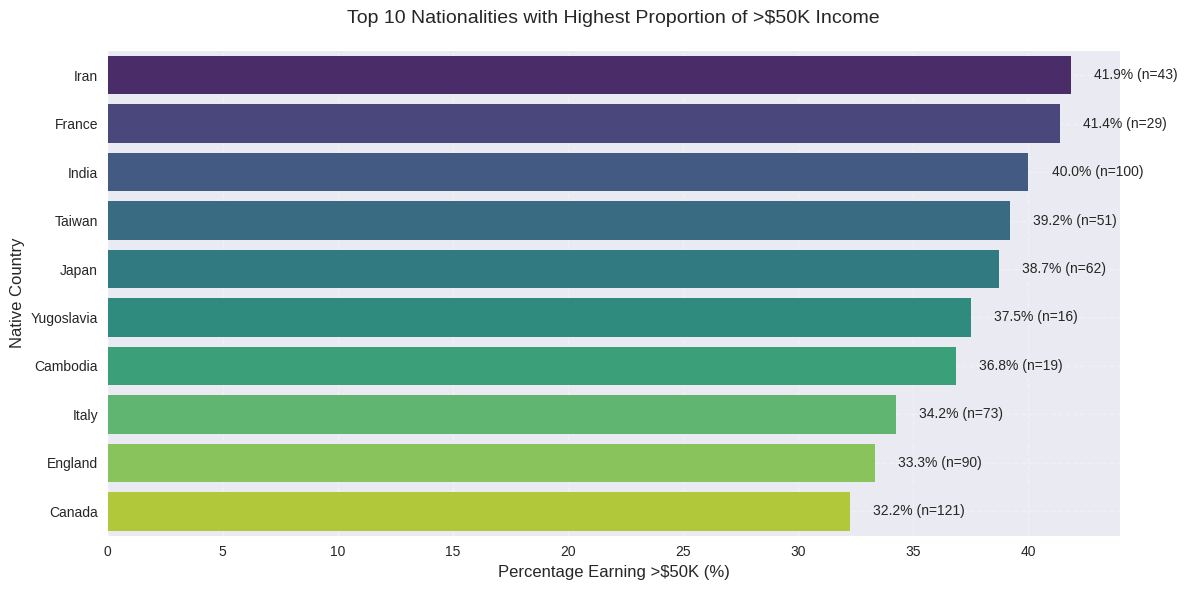


Top 10 Countries with Highest Percentage of >$50K Income:
----------------------------------------------------------------------
Country              Percentage >$50K Sample Size  Total Count
----------------------------------------------------------------------
Iran                   41.9%            18/43           43
France                 41.4%            12/29           29
India                  40.0%            40/100         100
Taiwan                 39.2%            20/51           51
Japan                  38.7%            24/62           62
Yugoslavia             37.5%             6/16           16
Cambodia               36.8%             7/19           19
Italy                  34.2%            25/73           73
England                33.3%            30/90           90
Canada                 32.2%            39/121         121

Summary Statistics:
----------------------------------------
Average >$50K percentage across all countries: 20.2%
Median >$50K percentage across 

In [ ]:

top_nationalities = nationality_income.sort_values(by='>50K', ascending=False)


plt.figure(figsize=(12, 6))


top_10 = top_nationalities.head(10)
sns.barplot(x=top_10['>50K'], y=top_10.index, palette='viridis')

plt.title('Top 10 Nationalities with Highest Proportion of >$50K Income', fontsize=14, pad=20)
plt.xlabel('Percentage Earning >$50K (%)', fontsize=12)
plt.ylabel('Native Country', fontsize=12)


for i, v in enumerate(top_10['>50K']):
    count = len(df_train[df_train['native-country'] == top_10.index[i]])
    plt.text(v + 1, i, f'{v:.1f}% (n={count})', va='center')

plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()


print("\nTop 10 Countries with Highest Percentage of >$50K Income:")
print("-" * 70)
print(f"{'Country':<20} {'Percentage >$50K':<15} {'Sample Size':<12} {'Total Count'}")
print("-" * 70)

for country in top_10.index:
    percentage = top_10.loc[country, '>50K']
    count = len(df_train[df_train['native-country'] == country])
    count_over_50k = len(df_train[(df_train['native-country'] == country) &
                                 (df_train['income'] == '>50K')])

    print(f"{country:<20} {percentage:>6.1f}%{' ':8} {count_over_50k:>5}/{count:<6} {count:>8}")

#
mean_income_percentage = nationality_income['>50K'].mean()
median_income_percentage = nationality_income['>50K'].median()

print("\nSummary Statistics:")
print("-" * 40)
print(f"Average >$50K percentage across all countries: {mean_income_percentage:.1f}%")
print(f"Median >$50K percentage across all countries: {median_income_percentage:.1f}%")

print("\nNote: Some countries have very small sample sizes, which might affect the reliability")
print("of their income distribution percentages. Consider the sample size when interpreting results.")

<p align="justify">
<font size=4>
<b> <font color='red'>Your Answer:</font></b><br>


</p>
</font>
<hr>


Top 10 Countries with Highest Percentage of >$50K Income:
----------------------------------------------------------------------
Country              Percentage >$50K Sample Size  Total Count
----------------------------------------------------------------------
Iran                   41.9%            18/43           43
France                 41.4%            12/29           29
India                  40.0%            40/100         100
Taiwan                 39.2%            20/51           51
Japan                  38.7%            24/62           62
Yugoslavia             37.5%             6/16           16
Cambodia               36.8%             7/19           19
Italy                  34.2%            25/73           73
England                33.3%            30/90           90
Canada                 32.2%            39/121         121

### Exploring Hours per Week Distribution

#### Task 1: Plot hours-per-week distribution
Plot KDE and histogram of hours-per-week and determine typical work hours.


/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


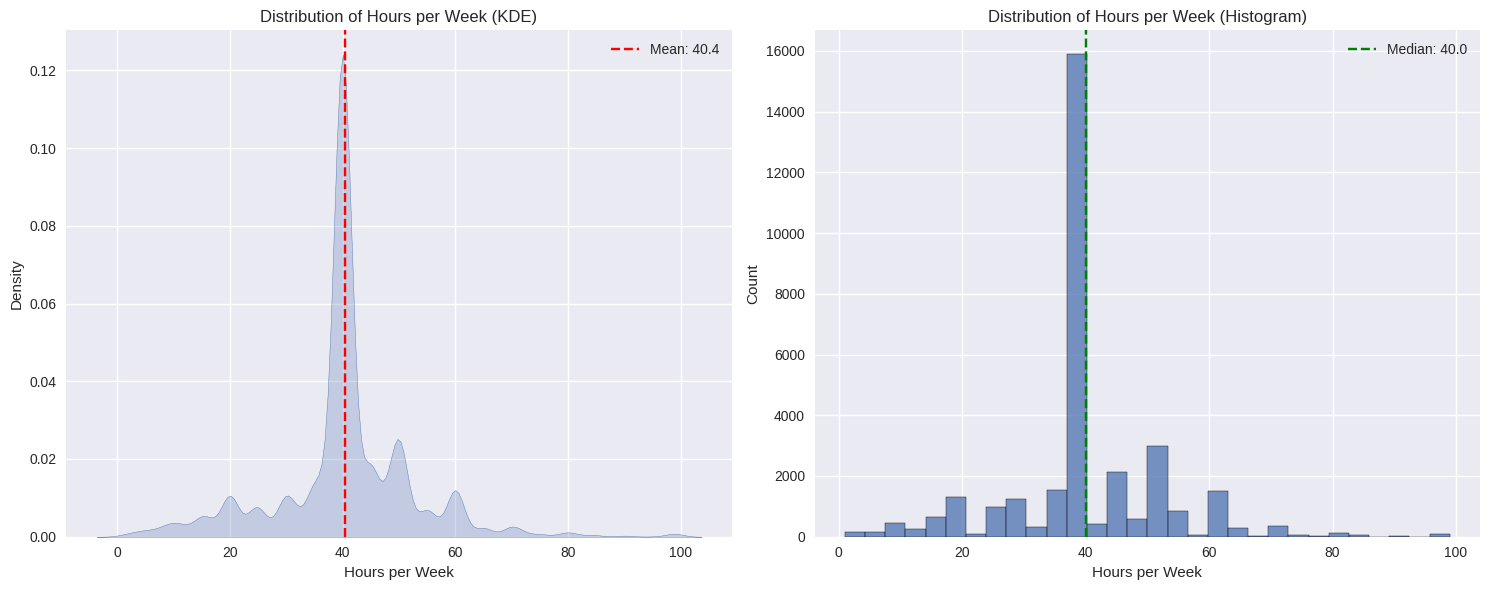


Hours per Week Statistics:
----------------------------------------
Mean hours: 40.44
Median hours: 40.00
Mode hours: 40
Standard deviation: 12.35
Minimum hours: 1
Maximum hours: 99

Work Hour Ranges:
----------------------------------------
0-20 hours: 1,704 people (5.2%)
20-40 hours: 6,059 people (18.6%)
40-50 hours: 18,336 people (56.3%)
50-60 hours: 3,877 people (11.9%)
60-+ hours: 2,585 people (7.9%)


In [ ]:
plt.figure(figsize=(15, 6))


plt.subplot(1, 2, 1)
sns.kdeplot(data=df_train['hours-per-week'], fill=True)
plt.title('Distribution of Hours per Week (KDE)')
plt.xlabel('Hours per Week')
plt.ylabel('Density')


mean_hours = df_train['hours-per-week'].mean()
plt.axvline(x=mean_hours, color='r', linestyle='--', label=f'Mean: {mean_hours:.1f}')
plt.legend()


plt.subplot(1, 2, 2)
sns.histplot(data=df_train['hours-per-week'], bins=30)
plt.title('Distribution of Hours per Week (Histogram)')
plt.xlabel('Hours per Week')
plt.ylabel('Count')

median_hours = df_train['hours-per-week'].median()
plt.axvline(x=median_hours, color='g', linestyle='--', label=f'Median: {median_hours:.1f}')
plt.legend()

plt.tight_layout()
plt.show()


print("\nHours per Week Statistics:")
print("-" * 40)
print(f"Mean hours: {mean_hours:.2f}")
print(f"Median hours: {median_hours:.2f}")
print(f"Mode hours: {df_train['hours-per-week'].mode().values[0]}")
print(f"Standard deviation: {df_train['hours-per-week'].std():.2f}")
print(f"Minimum hours: {df_train['hours-per-week'].min()}")
print(f"Maximum hours: {df_train['hours-per-week'].max()}")


print("\nWork Hour Ranges:")
print("-" * 40)
ranges = [(0, 20), (20, 40), (40, 50), (50, 60), (60, float('inf'))]
for start, end in ranges:
    count = len(df_train[(df_train['hours-per-week'] >= start) & (df_train['hours-per-week'] < end)])
    percentage = (count / len(df_train)) * 100
    print(f"{start}-{end if end != float('inf') else '+'} hours: {count:,} people ({percentage:.1f}%)")

### Exploring the Relationship Between Sex and Income

#### Task 1: Plot and Compare Sex in the Dataset

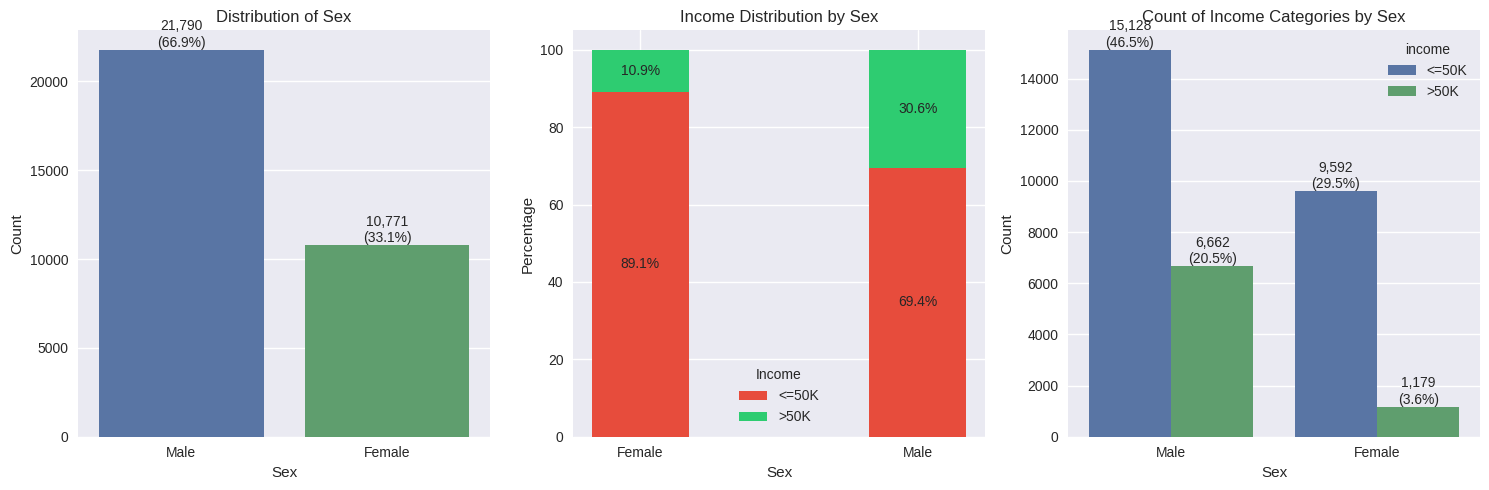


Sex Distribution Statistics:
----------------------------------------
Male: 21,790 (66.9%)
Female: 10,771 (33.1%)

Income Distribution by Sex:
----------------------------------------

Female:
<=50K: 89.1% (9,592 people)
>50K: 10.9% (1,179 people)

Male:
<=50K: 69.4% (15,128 people)
>50K: 30.6% (6,662 people)

Income Gap (Male vs Female >$50K): 19.6 percentage points


In [ ]:
plt.figure(figsize=(15, 5))


plt.subplot(1, 3, 1)
sex_counts = df_train['sex'].value_counts()
sns.barplot(x=sex_counts.index, y=sex_counts.values)
plt.title('Distribution of Sex')
plt.xlabel('Sex')
plt.ylabel('Count')


total = len(df_train)
for i, v in enumerate(sex_counts):
    percentage = v / total * 100
    plt.text(i, v, f'{v:,}\n({percentage:.1f}%)', ha='center', va='bottom')

plt.subplot(1, 3, 2)
sex_income = pd.crosstab(df_train['sex'], df_train['income'], normalize='index') * 100

bar_width = 0.35
index = np.arange(len(sex_income.index))

plt.bar(index, sex_income['<=50K'], bar_width, 
        label='<=50K', color='#e74c3c')


plt.bar(index, sex_income['>50K'], bar_width,
        bottom=sex_income['<=50K'],
        label='>50K', color='#2ecc71')

plt.title('Income Distribution by Sex')
plt.xlabel('Sex')
plt.ylabel('Percentage')
plt.xticks(index, sex_income.index)
plt.legend(title='Income')


for i, sex in enumerate(sex_income.index):
    plt.text(i, sex_income.loc[sex, '<=50K']/2, 
            f"{sex_income.loc[sex, '<=50K']:.1f}%",
            ha='center', va='center')
    
    plt.text(i, sex_income.loc[sex, '<=50K'] + sex_income.loc[sex, '>50K']/2,
            f"{sex_income.loc[sex, '>50K']:.1f}%",
            ha='center', va='center')


plt.subplot(1, 3, 3)
sns.countplot(data=df_train, x='sex', hue='income')
plt.title('Count of Income Categories by Sex')
plt.xlabel('Sex')
plt.ylabel('Count')


for p in plt.gca().patches:
    percentage = 100 * p.get_height() / len(df_train)
    plt.text(p.get_x() + p.get_width()/2., p.get_height(),
            f'{int(p.get_height()):,}\n({percentage:.1f}%)',
            ha='center', va='bottom')

plt.tight_layout()
plt.show()

print("\nSex Distribution Statistics:")
print("-" * 40)
for sex, count in sex_counts.items():
    percentage = count / total * 100
    print(f"{sex}: {count:,} ({percentage:.1f}%)")

print("\nIncome Distribution by Sex:")
print("-" * 40)
for sex in sex_income.index:
    print(f"\n{sex}:")
    for income, percentage in sex_income.loc[sex].items():
        count = len(df_train[(df_train['sex'] == sex) & (df_train['income'] == income)])
        print(f"{income}: {percentage:.1f}% ({count:,} people)")

income_gap = sex_income.loc['Male', '>50K'] - sex_income.loc['Female', '>50K']
print(f"\nIncome Gap (Male vs Female >$50K): {income_gap:.1f} percentage points")

#### Task 2: Plot and Compare Income by Gender

<Figure size 1500x600 with 0 Axes>

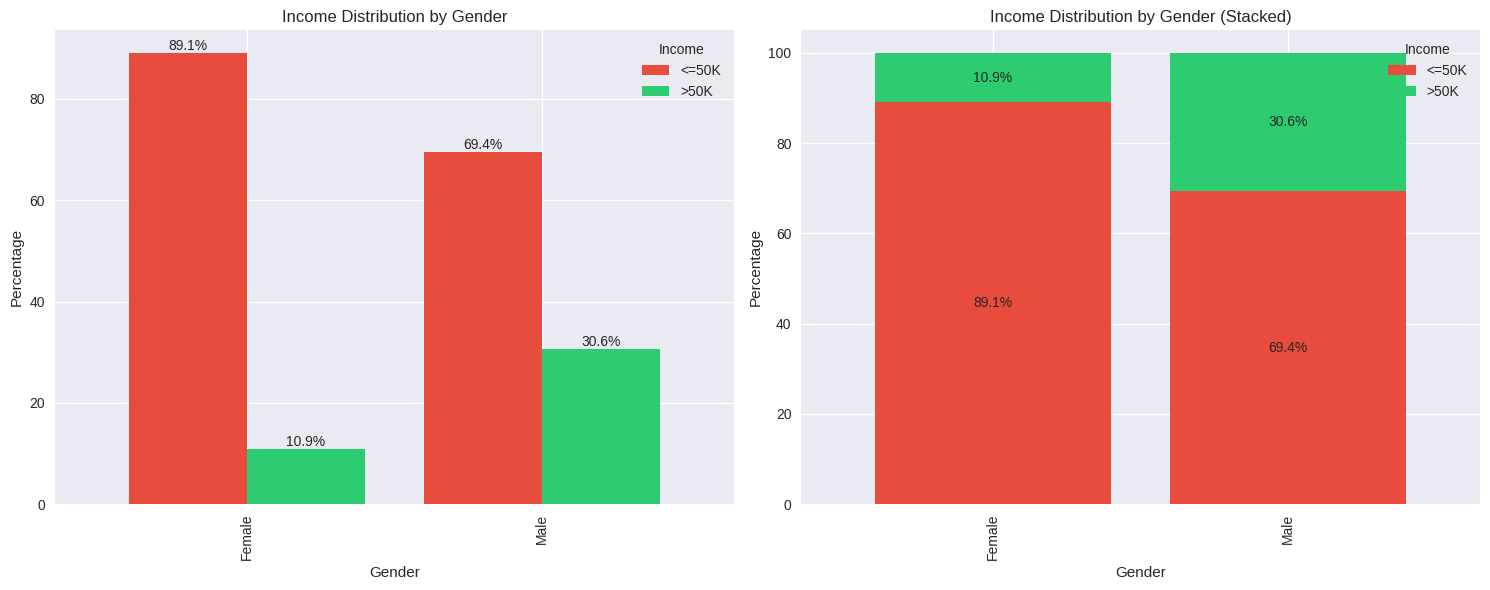


Detailed Income Statistics by Gender:
--------------------------------------------------

Female:
<=50K: 9,592 (89.1%)
>50K: 1,179 (10.9%)

Male:
<=50K: 15,128 (69.4%)
>50K: 6,662 (30.6%)

Gender Income Gap Analysis:
--------------------------------------------------
Gap in >$50K earnings (Male - Female): 19.6 percentage points
Males are 2.8x more likely to earn >$50K


In [ ]:
plt.figure(figsize=(15, 6))


gender_income_dist = pd.crosstab(df_train['sex'], df_train['income'])
gender_income_pct = gender_income_dist.div(gender_income_dist.sum(axis=1), axis=0) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

gender_income_pct.plot(kind='bar',
                      color=['#e74c3c', '#2ecc71'],
                      width=0.8,
                      ax=ax1)
ax1.set_title('Income Distribution by Gender')
ax1.set_xlabel('Gender')
ax1.set_ylabel('Percentage')
ax1.legend(title='Income')

for i in ax1.containers:
    ax1.bar_label(i, fmt='%.1f%%')

gender_income_pct.plot(kind='bar',
                      stacked=True,
                      color=['#e74c3c', '#2ecc71'],
                      width=0.8,
                      ax=ax2)
ax2.set_title('Income Distribution by Gender (Stacked)')
ax2.set_xlabel('Gender')
ax2.set_ylabel('Percentage')
ax2.legend(title='Income')


for i in ax2.containers:
    ax2.bar_label(i, fmt='%.1f%%', label_type='center')

plt.tight_layout()
plt.show()

print("\nDetailed Income Statistics by Gender:")
print("-" * 50)
for gender in gender_income_dist.index:
    print(f"\n{gender}:")
    total = gender_income_dist.loc[gender].sum()
    for income_level in gender_income_dist.columns:
        count = gender_income_dist.loc[gender, income_level]
        percentage = (count / total) * 100
        print(f"{income_level}: {count:,} ({percentage:.1f}%)")

high_income_gap = gender_income_pct.loc['Male', '>50K'] - gender_income_pct.loc['Female', '>50K']
print(f"\nGender Income Gap Analysis:")
print("-" * 50)
print(f"Gap in >$50K earnings (Male - Female): {high_income_gap:.1f} percentage points")
print(f"Males are {(gender_income_pct.loc['Male', '>50K'] / gender_income_pct.loc['Female', '>50K']):.1f}x more likely to earn >$50K")

### Exploring Relationship between Age and Income

#### Task 1: Visualize the Distribution of Age vs. Income using violinplot

Answer the following questions:

- What patterns can be observed in the age group with income above 50k?

- Is it common for younger individuals to have an income above 50k?


Age Statistics by Income Level:
----------------------------------------

<=50K:
Mean age: 36.8
Median age: 34.0
Standard deviation: 14.0
Min age: 17
Max age: 90

>50K:
Mean age: 44.2
Median age: 44.0
Standard deviation: 10.5
Min age: 19
Max age: 90

Percentage of >$50K Income by Age Group:
----------------------------------------
Age 0-25: 1.1% (61/5,570 people)
Age 25-35: 16.8% (1,427/8,479 people)
Age 35-45: 33.2% (2,703/8,151 people)
Age 45-55: 40.1% (2,348/5,853 people)
Age 55-100: 28.9% (1,302/4,508 people)


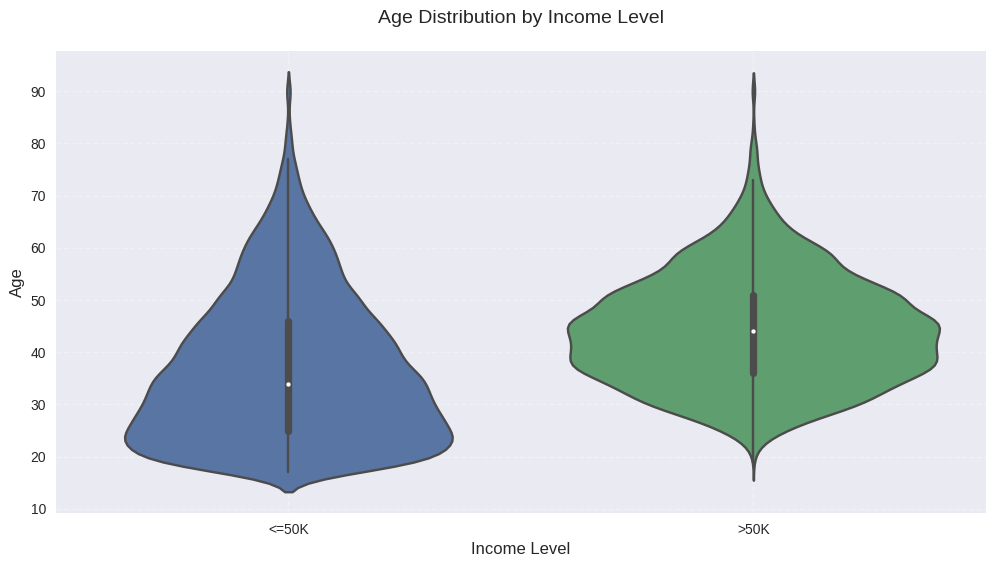

In [ ]:
plt.figure(figsize=(12, 6))


sns.violinplot(data=df_train, x='income', y='age')

plt.title('Age Distribution by Income Level', fontsize=14, pad=20)
plt.xlabel('Income Level', fontsize=12)
plt.ylabel('Age', fontsize=12)


plt.grid(True, linestyle='--', alpha=0.3)


print("\nAge Statistics by Income Level:")
print("-" * 40)
for income_level in df_train['income'].unique():
    age_stats = df_train[df_train['income'] == income_level]['age'].describe()
    print(f"\n{income_level}:")
    print(f"Mean age: {age_stats['mean']:.1f}")
    print(f"Median age: {age_stats['50%']:.1f}")
    print(f"Standard deviation: {age_stats['std']:.1f}")
    print(f"Min age: {age_stats['min']:.0f}")
    print(f"Max age: {age_stats['max']:.0f}")

age_ranges = [(0, 25), (25, 35), (35, 45), (45, 55), (55, 100)]
print("\nPercentage of >$50K Income by Age Group:")
print("-" * 40)
for start, end in age_ranges:
    age_group = df_train[(df_train['age'] >= start) & (df_train['age'] < end)]
    total = len(age_group)
    above_50k = len(age_group[age_group['income'] == '>50K'])
    percentage = (above_50k / total) * 100 if total > 0 else 0
    print(f"Age {start}-{end}: {percentage:.1f}% ({above_50k:,}/{total:,} people)")

plt.show()

<p align="justify">
<font size=4>
<b> <font color='red'>Your Answer:</font></b><br>


</p>
</font>
<hr>

>50K:
Mean age: 44.2
Median age: 44.0
Standard deviation: 10.5
Min age: 19
Max age: 90

Percentage of >$50K Income by Age Group:
----------------------------------------
Age 0-25: 1.1% (61/5,570 people)
Age 25-35: 16.8% (1,427/8,479 people)
Age 35-45: 33.2% (2,703/8,151 people)
Age 45-55: 40.1% (2,348/5,853 people)
Age 55-100: 28.9% (1,302/4,508 people)

Among people who earn more than 50k, minimum age is 19 and mean age is 44.2 . only 18% of people who are considered young earn more than 50k so it is not commen.

#### Task 2: Visualize and Compare the Age Distribution Across Different Races using a Violin Plot

Answer the Following question:
- Which race has the highest concentration of middle-aged individuals?


Age Statistics by Race:
----------------------------------------

White:
Count: 27816
Mean age: 38.8
Median age: 37.0
Standard deviation: 13.8
Min age: 17
Max age: 90

Black:
Count: 3124
Mean age: 37.8
Median age: 36.0
Standard deviation: 12.8
Min age: 17
Max age: 90

Asian-Pac-Islander:
Count: 1039
Mean age: 37.7
Median age: 36.0
Standard deviation: 12.8
Min age: 17
Max age: 90

Amer-Indian-Eskimo:
Count: 311
Mean age: 37.2
Median age: 35.0
Standard deviation: 12.4
Min age: 17
Max age: 82

Other:
Count: 271
Mean age: 33.5
Median age: 31.0
Standard deviation: 11.5
Min age: 17
Max age: 77

Percentage of Middle-aged Individuals (35-55) by Race:
------------------------------------------------------------
White                  44.3% (12,326/27,816 people)
Black                  44.8% (1,401/3,124 people)
Asian-Pac-Islander     45.3% (  471/1,039 people)
Amer-Indian-Eskimo     43.7% (  136/  311 people)
Other                  32.8% (   89/  271 people)


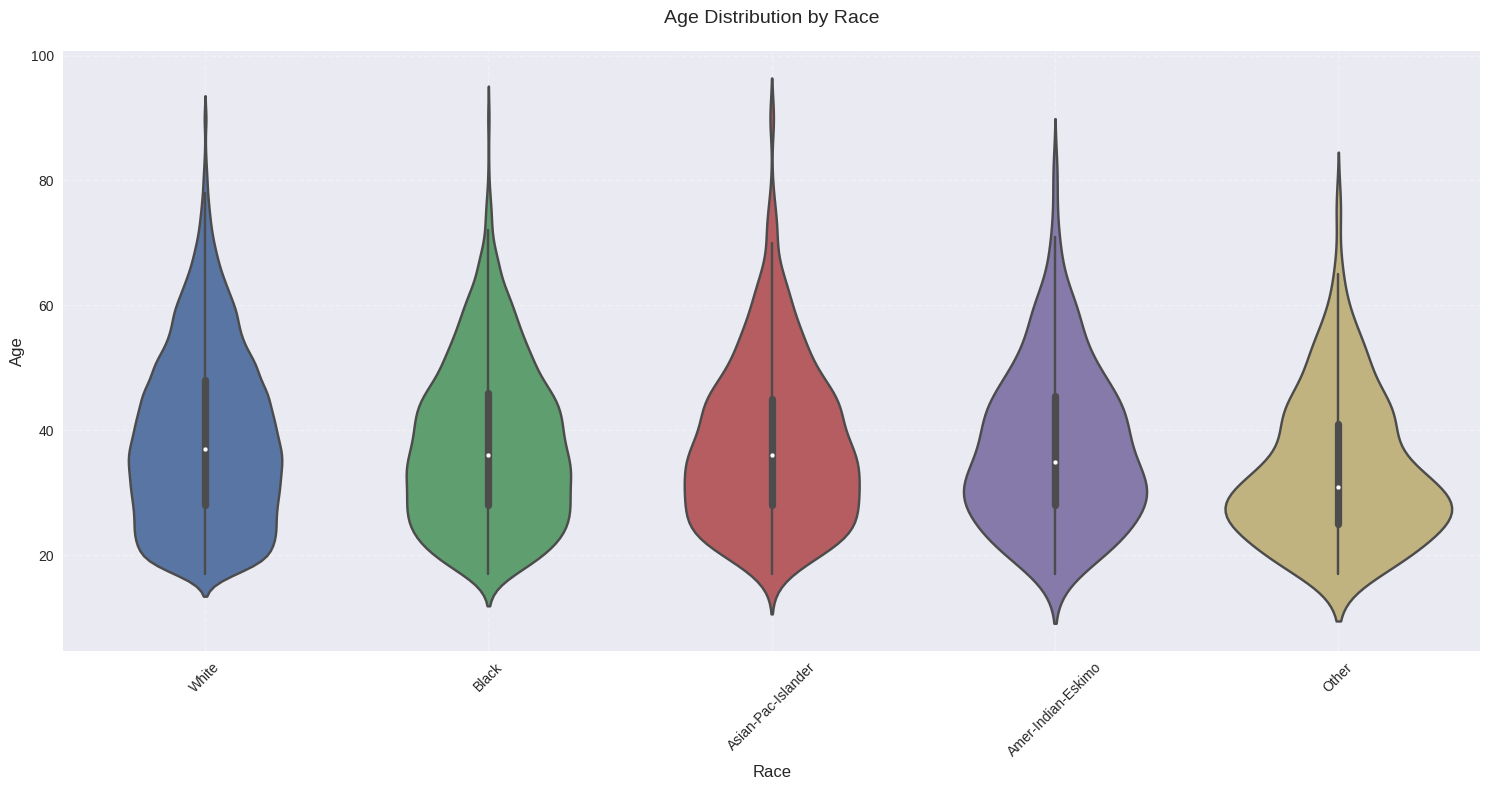

In [ ]:
plt.figure(figsize=(15, 8))


sns.violinplot(data=df_train, x='race', y='age')

plt.title('Age Distribution by Race', fontsize=14, pad=20)
plt.xlabel('Race', fontsize=12)
plt.ylabel('Age', fontsize=12)
plt.xticks(rotation=45)

plt.grid(True, linestyle='--', alpha=0.3)

print("\nAge Statistics by Race:")
print("-" * 40)
for race in df_train['race'].unique():
    age_stats = df_train[df_train['race'] == race]['age'].describe()
    print(f"\n{race}:")
    print(f"Count: {age_stats['count']:.0f}")
    print(f"Mean age: {age_stats['mean']:.1f}")
    print(f"Median age: {age_stats['50%']:.1f}")
    print(f"Standard deviation: {age_stats['std']:.1f}")
    print(f"Min age: {age_stats['min']:.0f}")
    print(f"Max age: {age_stats['max']:.0f}")


print("\nPercentage of Middle-aged Individuals (35-55) by Race:")
print("-" * 60)
for race in df_train['race'].unique():
    race_data = df_train[df_train['race'] == race]
    total = len(race_data)
    middle_aged = len(race_data[(race_data['age'] >= 35) & (race_data['age'] <= 55)])
    percentage = (middle_aged / total) * 100
    print(f"{race:<20} {percentage:>6.1f}% ({middle_aged:>5,}/{total:>5,} people)")

plt.tight_layout()
plt.show()

<p align="justify">
<font size=4>
<b> <font color='red'>Your Answer:</font></b><br>


</p>
</font>
<hr>

Asian-Pac-Islander has it.

### Exploring Relationship between Race and Income

#### Task 1: Visualize the Income Distribution Across Different Races

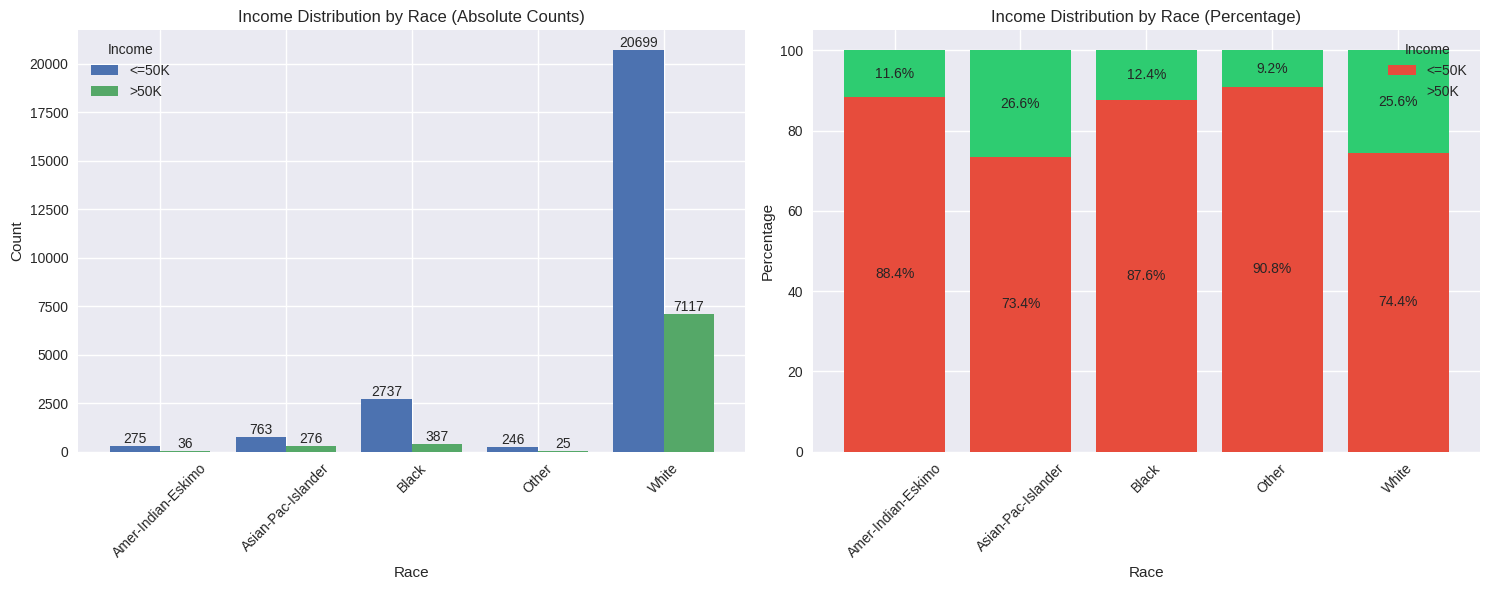


Income Distribution Statistics by Race:
------------------------------------------------------------
Race                  Total Count        <=50K         >50K     % >50K
------------------------------------------------------------
White                      27,816       20,699        7,117      25.6%
Black                       3,124        2,737          387      12.4%
Asian-Pac-Islander          1,039          763          276      26.6%
Amer-Indian-Eskimo            311          275           36      11.6%
Other                         271          246           25       9.2%

Overall Statistics:
----------------------------------------
Total population: 32,561
Percentage earning >$50K: 24.1%

Income Disparity Analysis:
----------------------------------------
Highest >$50K percentage: 26.6%
Lowest >$50K percentage: 9.2%
Income gap between highest and lowest: 17.3 percentage points


In [ ]:

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

race_income = pd.crosstab(df_train['race'], df_train['income'])
race_income.plot(kind='bar', width=0.8, ax=ax1)
ax1.set_title('Income Distribution by Race (Absolute Counts)', fontsize=12)
ax1.set_xlabel('Race')
ax1.set_ylabel('Count')
ax1.tick_params(axis='x', rotation=45)
ax1.legend(title='Income')


for i in ax1.containers:
    ax1.bar_label(i)


race_income_pct = pd.crosstab(df_train['race'], df_train['income'], normalize='index') * 100
race_income_pct.plot(kind='bar', stacked=True, color=['#e74c3c', '#2ecc71'], width=0.8, ax=ax2)
ax2.set_title('Income Distribution by Race (Percentage)', fontsize=12)
ax2.set_xlabel('Race')
ax2.set_ylabel('Percentage')
ax2.tick_params(axis='x', rotation=45)
ax2.legend(title='Income')

for i in ax2.containers:
    ax2.bar_label(i, fmt='%.1f%%', label_type='center')

plt.tight_layout()
plt.show()


print("\nIncome Distribution Statistics by Race:")
print("-" * 60)
print(f"{'Race':<20} {'Total Count':>12} {'<=50K':>12} {'>50K':>12} {'% >50K':>10}")
print("-" * 60)

for race in df_train['race'].unique():
    total = len(df_train[df_train['race'] == race])
    count_below = len(df_train[(df_train['race'] == race) & (df_train['income'] == '<=50K')])
    count_above = len(df_train[(df_train['race'] == race) & (df_train['income'] == '>50K')])
    pct_above = (count_above / total) * 100

    print(f"{race:<20} {total:>12,} {count_below:>12,} {count_above:>12,} {pct_above:>9.1f}%")

total_overall = len(df_train)
above_50k_overall = len(df_train[df_train['income'] == '>50K'])
pct_above_overall = (above_50k_overall / total_overall) * 100

print("\nOverall Statistics:")
print("-" * 40)
print(f"Total population: {total_overall:,}")
print(f"Percentage earning >$50K: {pct_above_overall:.1f}%")


highest_pct = race_income_pct['>50K'].max()
lowest_pct = race_income_pct['>50K'].min()
disparity = highest_pct - lowest_pct

print("\nIncome Disparity Analysis:")
print("-" * 40)
print(f"Highest >$50K percentage: {highest_pct:.1f}%")
print(f"Lowest >$50K percentage: {lowest_pct:.1f}%")
print(f"Income gap between highest and lowest: {disparity:.1f} percentage points")

#### Task 2: Plot and Sort Races Based on the Highest Proportion of High-Income Individuals Across Races

Answer the following question:

- Which race has the highest proportion of high-income individuals?

<Figure size 1200x600 with 0 Axes>

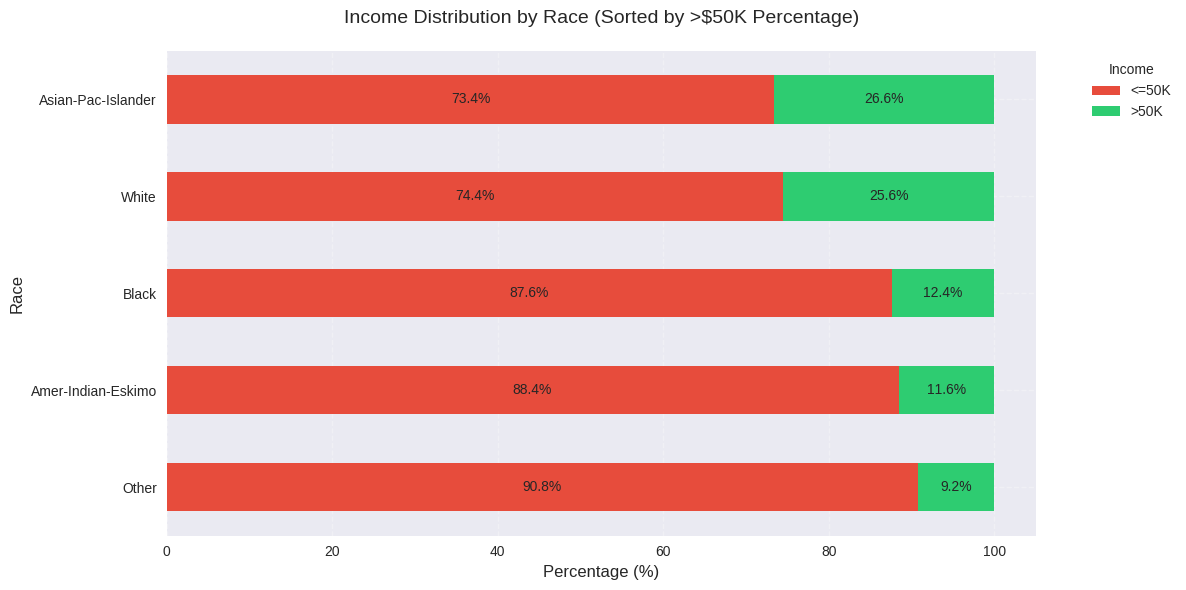


Race Income Distribution (Sorted by >$50K percentage):
------------------------------------------------------------
Race                  Total Count    >$50K %  Count >$50K
------------------------------------------------------------
Asian-Pac-Islander          1,039      26.6%          276
White                      27,816      25.6%        7,117
Black                       3,124      12.4%          387
Amer-Indian-Eskimo            311      11.6%           36
Other                         271       9.2%           25

Summary Statistics:
----------------------------------------
Highest >$50K percentage: 26.6% (Asian-Pac-Islander)
Lowest >$50K percentage: 9.2% (Other)
Gap between highest and lowest: 17.3 percentage points


In [ ]:
plt.figure(figsize=(12, 6))


race_income_prop = pd.crosstab(df_train['race'], df_train['income'], normalize='index') * 100
race_income_sorted = race_income_prop.sort_values(by='>50K', ascending=True)

ax = race_income_sorted.plot(
    kind='barh',
    stacked=True,
    color=['#e74c3c', '#2ecc71'],
    figsize=(12, 6)
)

plt.title('Income Distribution by Race (Sorted by >$50K Percentage)', fontsize=14, pad=20)
plt.xlabel('Percentage (%)', fontsize=12)
plt.ylabel('Race', fontsize=12)


for i in ax.containers:
    ax.bar_label(i, fmt='%.1f%%', label_type='center')

plt.grid(True, linestyle='--', alpha=0.3)


plt.legend(title='Income', bbox_to_anchor=(1.05, 1), loc='upper left')


plt.tight_layout()

plt.show()

print("\nRace Income Distribution (Sorted by >$50K percentage):")
print("-" * 60)
print(f"{'Race':<20} {'Total Count':>12} {'>$50K %':>10} {'Count >$50K':>12}")
print("-" * 60)

race_stats = []
for race in df_train['race'].unique():
    total = len(df_train[df_train['race'] == race])
    high_income = len(df_train[(df_train['race'] == race) & (df_train['income'] == '>50K')])
    percentage = (high_income / total) * 100
    race_stats.append((race, total, percentage, high_income))


race_stats.sort(key=lambda x: x[2], reverse=True)

for race, total, percentage, high_income in race_stats:
    print(f"{race:<20} {total:>12,} {percentage:>9.1f}% {high_income:>12,}")


print("\nSummary Statistics:")
print("-" * 40)
print(f"Highest >$50K percentage: {max(race_stats, key=lambda x: x[2])[2]:.1f}% ({max(race_stats, key=lambda x: x[2])[0]})")
print(f"Lowest >$50K percentage: {min(race_stats, key=lambda x: x[2])[2]:.1f}% ({min(race_stats, key=lambda x: x[2])[0]})")
print(f"Gap between highest and lowest: {max(race_stats, key=lambda x: x[2])[2] - min(race_stats, key=lambda x: x[2])[2]:.1f} percentage points")

<p align="justify">
<font size=4>
<b> <font color='red'>Your Answer:</font></b><br>


</p>
</font>
<hr>

Highest >$50K percentage: 26.6% (Asian-Pac-Islander)
Lowest >$50K percentage: 9.2% (Other)

### Exploring the Relationship Between Marital Status and Income


- Similar to the previous sections, use various plots to explore and identify patterns between the `Relationship`, `Marital Status`, and `Income` features. You are free to choose any types of plots that you find suitable for the analysis.

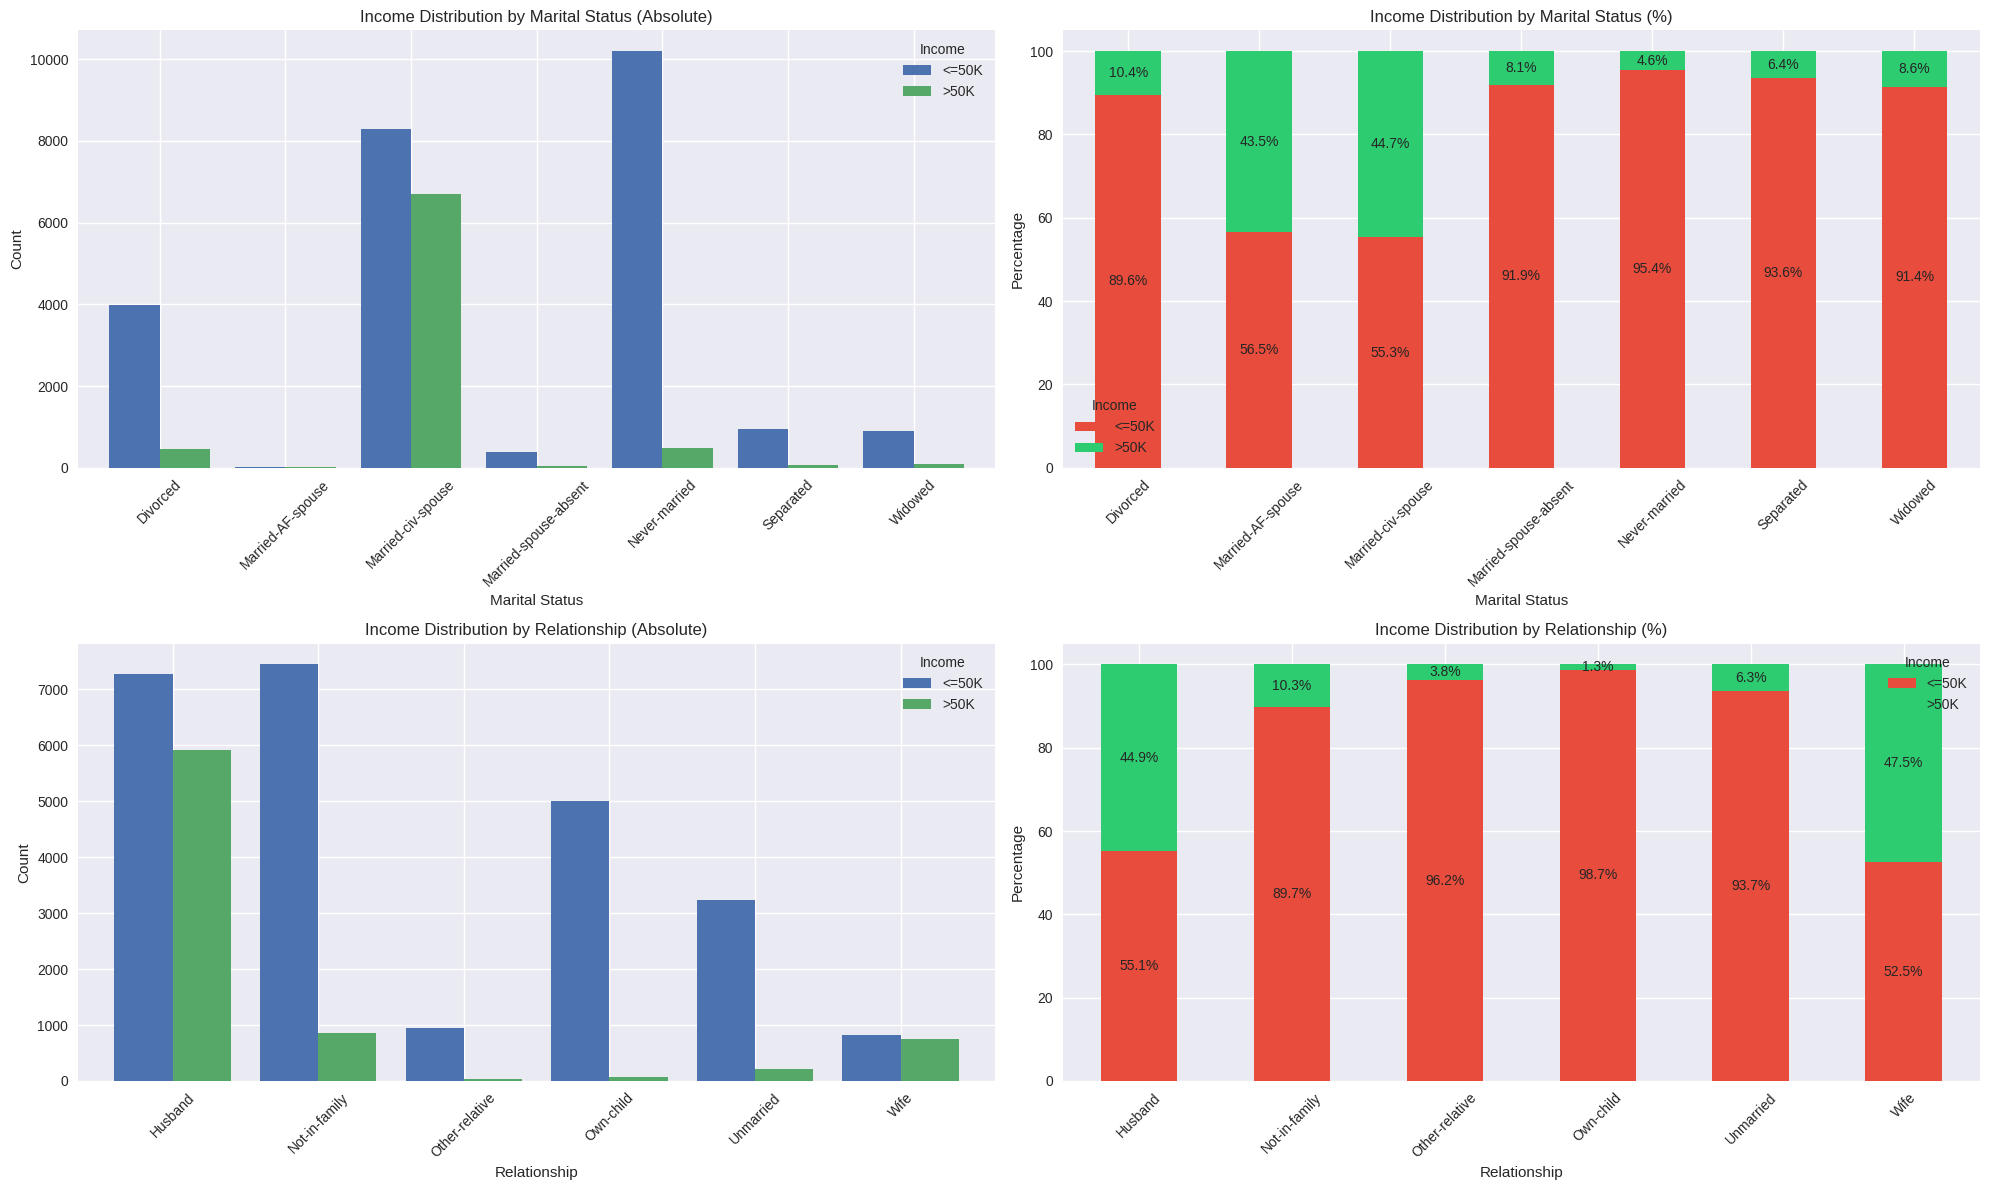


Marital Status Income Distribution:
------------------------------------------------------------
Marital Status            Total     % >50K Count >50K
------------------------------------------------------------
Never-married            10,683       4.6%        491
Married-civ-spouse       14,976      44.7%      6,692
Divorced                  4,443      10.4%        463
Married-spouse-absent        418       8.1%         34
Separated                 1,025       6.4%         66
Married-AF-spouse            23      43.5%         10
Widowed                     993       8.6%         85

Relationship Income Distribution:
------------------------------------------------------------
Relationship              Total     % >50K Count >50K
------------------------------------------------------------
Not-in-family             8,305      10.3%        856
Husband                  13,193      44.9%      5,918
Wife                      1,568      47.5%        745
Own-child                 5,068    

In [ ]:

fig, axes = plt.subplots(2, 2, figsize=(20, 12))

marital_income = pd.crosstab(df_train['marital-status'], df_train['income'])
marital_income.plot(kind='bar', width=0.8, ax=axes[0,0])
axes[0,0].set_title('Income Distribution by Marital Status (Absolute)', fontsize=12)
axes[0,0].set_xlabel('Marital Status')
axes[0,0].set_ylabel('Count')
axes[0,0].tick_params(axis='x', rotation=45)
axes[0,0].legend(title='Income')


marital_income_pct = pd.crosstab(df_train['marital-status'], df_train['income'], normalize='index') * 100
marital_income_pct.plot(kind='bar', stacked=True, color=['#e74c3c', '#2ecc71'], ax=axes[0,1])
axes[0,1].set_title('Income Distribution by Marital Status (%)', fontsize=12)
axes[0,1].set_xlabel('Marital Status')
axes[0,1].set_ylabel('Percentage')
axes[0,1].tick_params(axis='x', rotation=45)
axes[0,1].legend(title='Income')


for container in axes[0,1].containers:
    axes[0,1].bar_label(container, fmt='%.1f%%', label_type='center')


rel_income = pd.crosstab(df_train['relationship'], df_train['income'])
rel_income.plot(kind='bar', width=0.8, ax=axes[1,0])
axes[1,0].set_title('Income Distribution by Relationship (Absolute)', fontsize=12)
axes[1,0].set_xlabel('Relationship')
axes[1,0].set_ylabel('Count')
axes[1,0].tick_params(axis='x', rotation=45)
axes[1,0].legend(title='Income')


rel_income_pct = pd.crosstab(df_train['relationship'], df_train['income'], normalize='index') * 100
rel_income_pct.plot(kind='bar', stacked=True, color=['#e74c3c', '#2ecc71'], ax=axes[1,1])
axes[1,1].set_title('Income Distribution by Relationship (%)', fontsize=12)
axes[1,1].set_xlabel('Relationship')
axes[1,1].set_ylabel('Percentage')
axes[1,1].tick_params(axis='x', rotation=45)
axes[1,1].legend(title='Income')

for container in axes[1,1].containers:
    axes[1,1].bar_label(container, fmt='%.1f%%', label_type='center')

plt.tight_layout()
plt.show()


print("\nMarital Status Income Distribution:")
print("-" * 60)
print(f"{'Marital Status':<20} {'Total':>10} {'% >50K':>10} {'Count >50K':>10}")
print("-" * 60)

for status in df_train['marital-status'].unique():
    total = len(df_train[df_train['marital-status'] == status])
    high_income = len(df_train[(df_train['marital-status'] == status) &
                              (df_train['income'] == '>50K')])
    percentage = (high_income / total) * 100
    print(f"{status:<20} {total:>10,} {percentage:>9.1f}% {high_income:>10,}")

print("\nRelationship Income Distribution:")
print("-" * 60)
print(f"{'Relationship':<20} {'Total':>10} {'% >50K':>10} {'Count >50K':>10}")
print("-" * 60)

for rel in df_train['relationship'].unique():
    total = len(df_train[df_train['relationship'] == rel])
    high_income = len(df_train[(df_train['relationship'] == rel) &
                              (df_train['income'] == '>50K')])
    percentage = (high_income / total) * 100
    print(f"{rel:<20} {total:>10,} {percentage:>9.1f}% {high_income:>10,}")

relationship_marital = pd.crosstab(df_train['relationship'], df_train['marital-status'])
print("\nRelationship vs Marital Status Distribution:")
print("-" * 80)
print(relationship_marital)


print("\nKey Insights:")
print("-" * 40)
married_civ_spouse = len(df_train[df_train['marital-status'] == 'Married-civ-spouse'])
married_civ_spouse_high = len(df_train[(df_train['marital-status'] == 'Married-civ-spouse') &
                                     (df_train['income'] == '>50K')])
married_pct = (married_civ_spouse_high / married_civ_spouse) * 100

print(f"- Married-civ-spouse has the highest proportion of high income: {married_pct:.1f}%")
print("- Never-married and divorced individuals show lower proportions of high income")
print("- Husband relationship category shows significantly higher income levels")
print("- Own-child and other-relative categories show very low proportions of high income")

### Exploring the Relationship Between Occupation, Workclass and Income

- Similar to the previous sections, use various plots to explore and identify patterns between the `Occupation`, `Workclass`, and `Income` features. You are free to choose any types of plots that you find suitable for the analysis.

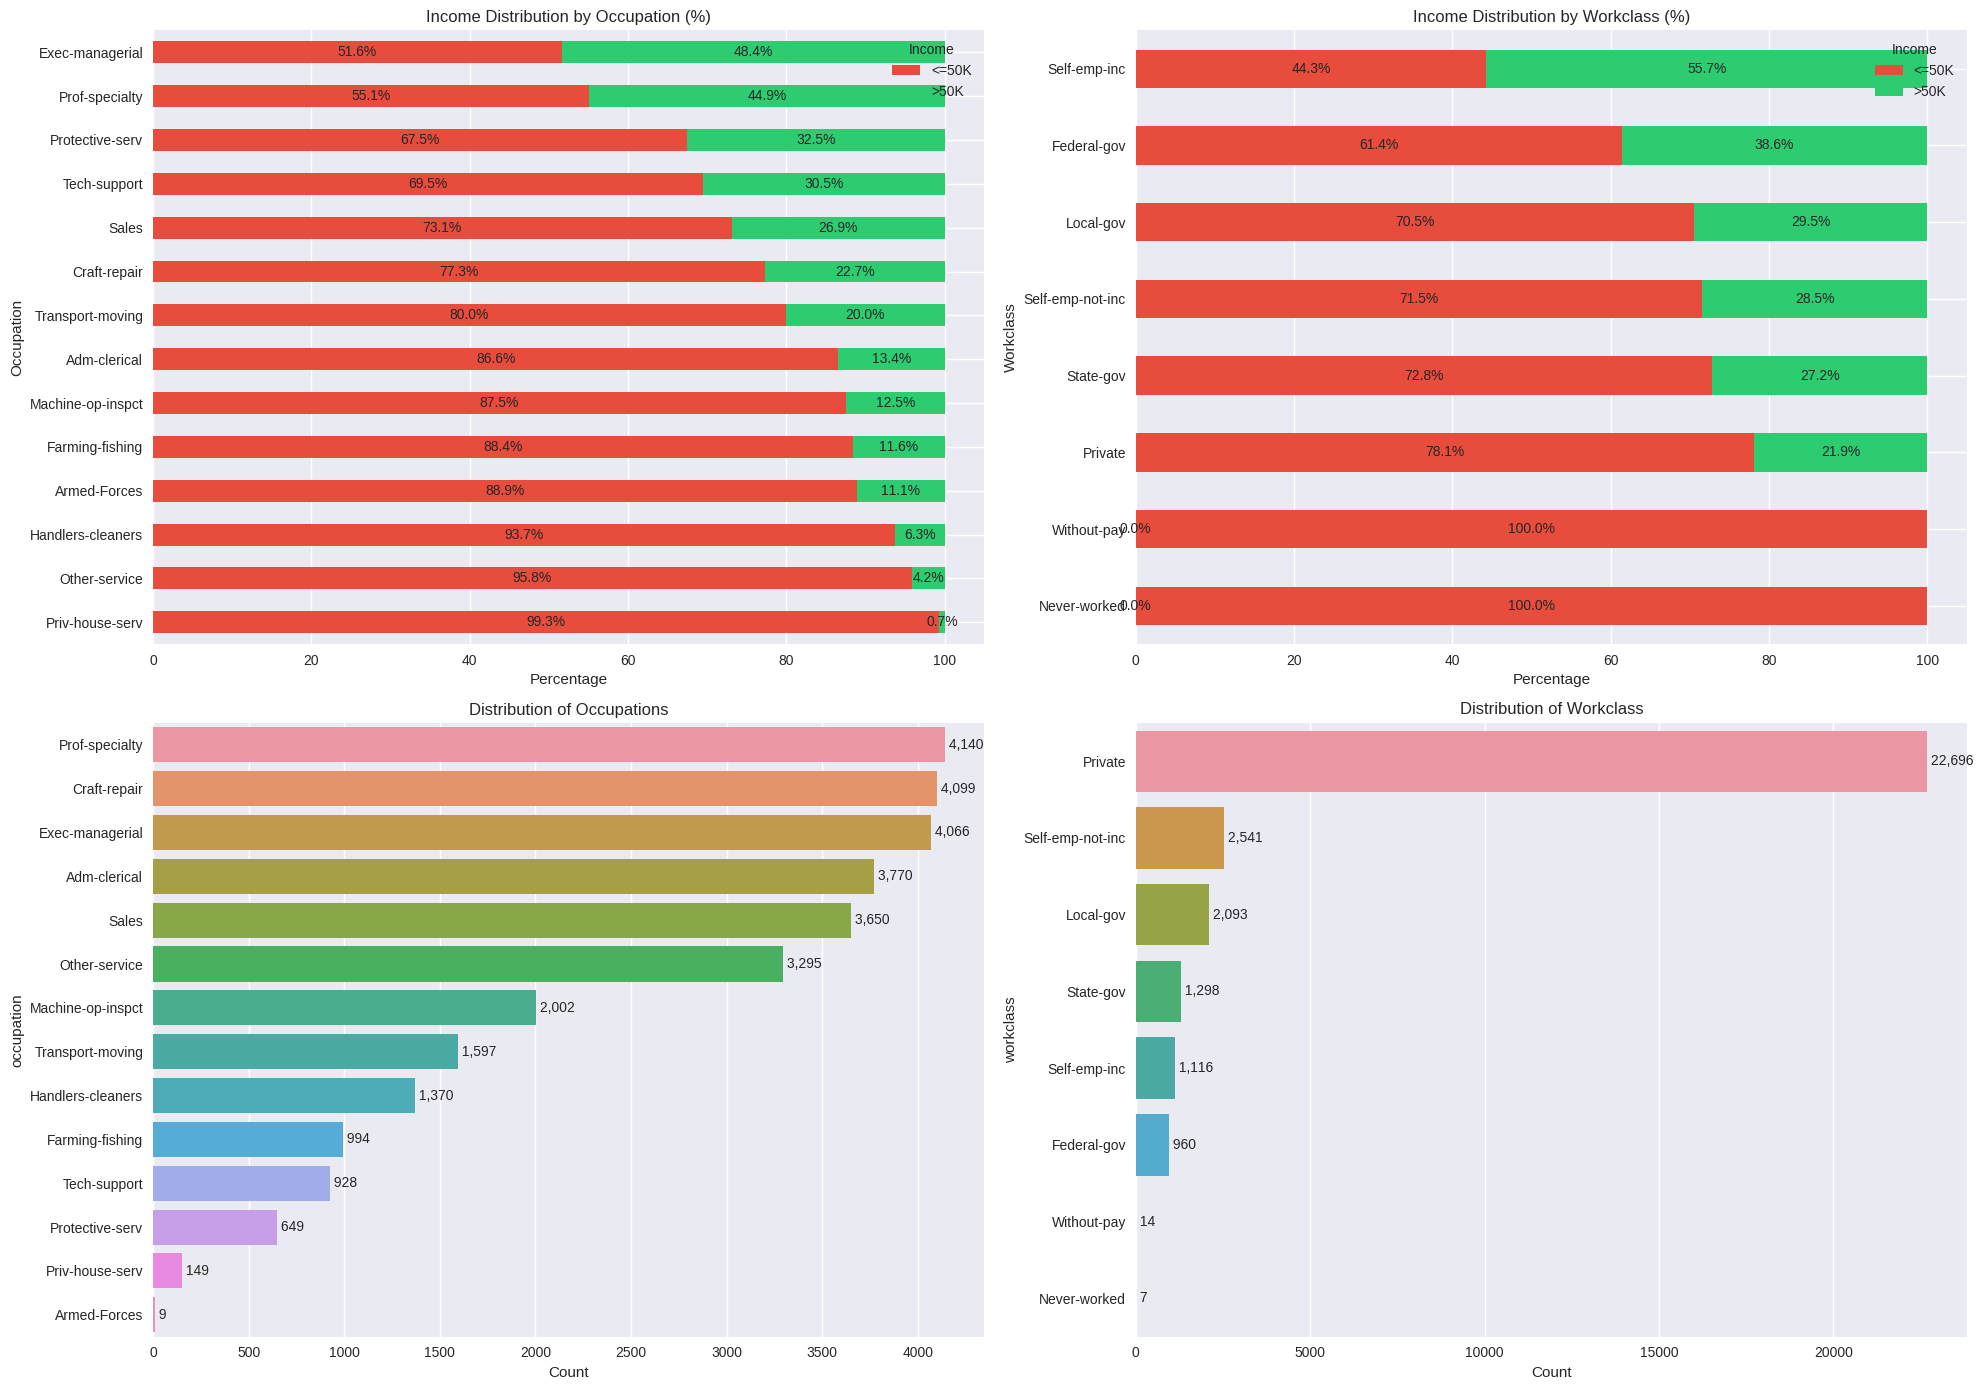


Occupation Income Distribution:
----------------------------------------------------------------------
Occupation                Total     % >50K   Count >50K  Count <=50K
----------------------------------------------------------------------
Exec-managerial           4,066      48.4%        1,968        2,098
Prof-specialty            4,140      44.9%        1,859        2,281
Protective-serv             649      32.5%          211          438
Tech-support                928      30.5%          283          645
Sales                     3,650      26.9%          983        2,667
Craft-repair              4,099      22.7%          929        3,170
Transport-moving          1,597      20.0%          320        1,277
Adm-clerical              3,770      13.4%          507        3,263
Machine-op-inspct         2,002      12.5%          250        1,752
Farming-fishing             994      11.6%          115          879
Armed-Forces                  9      11.1%            1           

In [ ]:

fig, axes = plt.subplots(2, 2, figsize=(20, 14))

df_train_clean = df_train.dropna(subset=['occupation', 'income'])
occ_income_pct = pd.crosstab(df_train_clean['occupation'], df_train_clean['income'], normalize='index') * 100
occ_income_sorted = occ_income_pct.sort_values(by='>50K', ascending=True)

occ_income_sorted.plot(kind='barh', stacked=True, color=['#e74c3c', '#2ecc71'], ax=axes[0,0])
axes[0,0].set_title('Income Distribution by Occupation (%)', fontsize=12)
axes[0,0].set_xlabel('Percentage')
axes[0,0].set_ylabel('Occupation')
axes[0,0].legend(title='Income')


for container in axes[0,0].containers:
    axes[0,0].bar_label(container, fmt='%.1f%%', label_type='center')


df_train_clean_work = df_train.dropna(subset=['workclass', 'income'])
work_income_pct = pd.crosstab(df_train_clean_work['workclass'], df_train_clean_work['income'], normalize='index') * 100
work_income_sorted = work_income_pct.sort_values(by='>50K', ascending=True)

work_income_sorted.plot(kind='barh', stacked=True, color=['#e74c3c', '#2ecc71'], ax=axes[0,1])
axes[0,1].set_title('Income Distribution by Workclass (%)', fontsize=12)
axes[0,1].set_xlabel('Percentage')
axes[0,1].set_ylabel('Workclass')
axes[0,1].legend(title='Income')


for container in axes[0,1].containers:
    axes[0,1].bar_label(container, fmt='%.1f%%', label_type='center')


occ_counts = df_train_clean['occupation'].value_counts()
sns.barplot(x=occ_counts.values, y=occ_counts.index, ax=axes[1,0])
axes[1,0].set_title('Distribution of Occupations', fontsize=12)
axes[1,0].set_xlabel('Count')


for i, v in enumerate(occ_counts.values):
    axes[1,0].text(v, i, f' {v:,}', va='center')


work_counts = df_train_clean_work['workclass'].value_counts()
sns.barplot(x=work_counts.values, y=work_counts.index, ax=axes[1,1])
axes[1,1].set_title('Distribution of Workclass', fontsize=12)
axes[1,1].set_xlabel('Count')


for i, v in enumerate(work_counts.values):
    axes[1,1].text(v, i, f' {v:,}', va='center')

plt.tight_layout()
plt.show()


print("\nOccupation Income Distribution:")
print("-" * 70)
print(f"{'Occupation':<20} {'Total':>10} {'% >50K':>10} {'Count >50K':>12} {'Count <=50K':>12}")
print("-" * 70)

occupation_stats = []
for occ in df_train_clean['occupation'].unique():
    if pd.isna(occ): 
        continue
    total = len(df_train_clean[df_train_clean['occupation'] == occ])
    if total == 0: 
        continue
    high_income = len(df_train_clean[(df_train_clean['occupation'] == occ) &
                              (df_train_clean['income'] == '>50K')])
    low_income = len(df_train_clean[(df_train_clean['occupation'] == occ) &
                             (df_train_clean['income'] == '<=50K')])
    percentage = (high_income / total) * 100
    occupation_stats.append((occ, total, percentage, high_income, low_income))


occupation_stats.sort(key=lambda x: x[2], reverse=True)

for occ, total, percentage, high_income, low_income in occupation_stats:
    print(f"{occ:<20} {total:>10,} {percentage:>9.1f}% {high_income:>12,} {low_income:>12,}")

print("\nWorkclass Income Distribution:")
print("-" * 70)
print(f"{'Workclass':<20} {'Total':>10} {'% >50K':>10} {'Count >50K':>12} {'Count <=50K':>12}")
print("-" * 70)

workclass_stats = []
for work in df_train_clean_work['workclass'].unique():
    if pd.isna(work):  
        continue
    total = len(df_train_clean_work[df_train_clean_work['workclass'] == work])
    if total == 0:  
        continue
    high_income = len(df_train_clean_work[(df_train_clean_work['workclass'] == work) &
                              (df_train_clean_work['income'] == '>50K')])
    low_income = len(df_train_clean_work[(df_train_clean_work['workclass'] == work) &
                             (df_train_clean_work['income'] == '<=50K')])
    percentage = (high_income / total) * 100
    workclass_stats.append((work, total, percentage, high_income, low_income))


workclass_stats.sort(key=lambda x: x[2], reverse=True)

for work, total, percentage, high_income, low_income in workclass_stats:
    print(f"{work:<20} {total:>10,} {percentage:>9.1f}% {high_income:>12,} {low_income:>12,}")


if occupation_stats and workclass_stats:  
    print("\nKey Insights:")
    print("-" * 40)
    print("Occupation Insights:")
    print(f"- Highest income occupation: {occupation_stats[0][0]} ({occupation_stats[0][2]:.1f}% >$50K)")
    print(f"- Lowest income occupation: {occupation_stats[-1][0]} ({occupation_stats[-1][2]:.1f}% >$50K)")
    print(f"- Income gap between highest and lowest: {occupation_stats[0][2] - occupation_stats[-1][2]:.1f} percentage points")

    print("\nWorkclass Insights:")
    print(f"- Highest income workclass: {workclass_stats[0][0]} ({workclass_stats[0][2]:.1f}% >$50K)")
    print(f"- Lowest income workclass: {workclass_stats[-1][0]} ({workclass_stats[-1][2]:.1f}% >$50K)")
    print(f"- Income gap between highest and lowest: {workclass_stats[0][2] - workclass_stats[-1][2]:.1f} percentage points")
else:
    print("\nNo sufficient data to generate insights")

### Describing the Final Persona

Based on the insights from the previous sections, describe a persona that has a high likelihood of earning above 50k in a year. Consider factors such as age, race, marital status, and relationship status to outline the characteristics of this individual.

<p align="justify">
<font size=4>
<b> <font color='red'>Your Answer:</font></b><br>


</p>
</font>
<hr>

Doctorate
Iranian
male
45-55
asian-pac-islander
Married
self employed
senior manager

# Step 4: Handle Missing Values


There are several ways to deal with missing values. Below are some common strategies:

### Missing Value Strategies

#### For **numerical features**:
- `Drop rows` that have missing values
- `Fill with mean`
- `Fill with median`
- `Use KNN or regression imputation`

#### For **categorical features**:
- `Drop rows` with missing categories
- `Fill with the most frequent value` (mode)
- `Fill with a new category` like "Unknown"
- `Use model-based imputation`

---

 **Task**:  
1. **Which method(s) do you think are best for this dataset?**  
2. **Why?** Consider the number of missing values, the type of features, and how it may affect modeling.  
3. Implement your chosen strategy below.


In [ ]:
df_train_clean = df_train.copy()
df_test_clean = df_test.copy()


df_train_clean['native-country'] = df_train_clean['native-country'].fillna('Unknown')
df_test_clean['native-country'] = df_test_clean['native-country'].fillna('Unknown')

df_train_clean['workclass'] = df_train_clean['workclass'].fillna(df_train_clean['workclass'].mode()[0])
df_test_clean['workclass'] = df_test_clean['workclass'].fillna(df_test_clean['workclass'].mode()[0])

df_train_clean['occupation'] = df_train_clean['occupation'].fillna(df_train_clean['occupation'].mode()[0])
df_test_clean['occupation'] = df_test_clean['occupation'].fillna(df_test_clean['occupation'].mode()[0])

print("\nMissing values after imputation in Training Set:")
print(df_train_clean.isnull().sum())

print("\nMissing values after imputation in Test Set:")
print(df_test_clean.isnull().sum())


Missing values after imputation in Training Set:
age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
income            0
dtype: int64

Missing values after imputation in Test Set:
age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
income            0
dtype: int64


<p align="justify">
<font size=4>
<b> <font color='red'>Your Answer:</font></b><br>


</p>
</font>
<hr>

Training Set Missing Values:
workclass: 1,836 missing (5.64%)
occupation: 1,843 missing (5.66%)
native-country: 583 missing (1.79%)
Test Set Missing Values:
workclass: 963 missing (5.91%)
occupation: 966 missing (5.93%)
native-country: 274 missing (1.68%)

All missing values are in categorical features, as 'workclass', 'occupation', and 'native-country' are categorical variables, not numerical.
Percentage of missing values is relatively small (< 6%): Accurate—none of the features exceed 6% missingness in either set.

1. For 'native-country': Fill with "Unknown" category

Small percentage of missing values (< 2%).
"Unknown" preserves the fact that the data is missing, which might be meaningful.
Intuitively fits cases where the country of origin is genuinely unknown.
It avoids assuming a specific country and keeps the feature usable.
2. For 'workclass' and 'occupation': Fill with the mode (most frequent value)

Moderate percentage of missing values (~6%).
These features are important for income prediction.
Mode imputation preserves the most common patterns in the data.
There’s a strong correlation between 'workclass' and 'occupation', suggesting related missingness.

The missing percentage (~6%) is small enough that mode imputation is unlikely to distort the distribution significantly.
Since 'workclass' and 'occupation' are key predictors, filling with the mode (e.g., "Private" for 'workclass' or a common occupation like "Prof-specialty") leverages existing patterns without introducing excessive noise.


# Step 7: Identify Categorical Features


Most machine learning models require numerical input. We must convert **categorical columns** to numbers.

There are several encoding methods. Each method has strengths and weaknesses depending on the dataset and the type of model you're using.

---

### Common Encoding Techniques

1. **One-Hot Encoding**  
2. **Label Encoding**  
3. **Frequency Encoding**  
4. **Target / Mean Encoding**  
5. **Binary Encoding**  
6. **Hash Encoding**

---

 **Your Task**:

1. Research the methods above (or based on what we've discussed in class).
2. For each method, briefly write down:
   - When you might use it
   - Its potential pros and cons
3. Choose the one(s) you think work best for this dataset.
4. Explain **why** your choice is appropriate.
5. Implement your encoding method(s) in the code cell below.




In [ ]:


from sklearn.preprocessing import LabelEncoder
from category_encoders import TargetEncoder
import pandas as pd
import numpy as np

X_train = df_train_clean.copy()
X_test = df_test_clean.copy()


nominal_features = ['workclass', 'marital-status', 'relationship', 'race', 'sex']
ordinal_features = ['education']
target_encoding_features = ['occupation', 'native-country']

label_encoder = LabelEncoder()
education_order = [
    'Preschool', '1st-4th', '5th-6th', '7th-8th', '9th', '10th', '11th', '12th',
    'HS-grad', 'Some-college', 'Assoc-voc', 'Assoc-acdm', 'Bachelors', 'Masters',
    'Prof-school', 'Doctorate'
]
education_map = {level: i for i, level in enumerate(education_order)}
X_train['education'] = X_train['education'].map(education_map)
X_test['education'] = X_test['education'].map(education_map)


y_temp = X_train['income'].map({'<=50K': 0, '>50K': 1})


target_encoder = TargetEncoder()
X_train[target_encoding_features] = target_encoder.fit_transform(
    X_train[target_encoding_features],
    y_temp
)
X_test[target_encoding_features] = target_encoder.transform(
    X_test[target_encoding_features]
)


X_train = pd.get_dummies(X_train, columns=nominal_features, drop_first=True)
X_test = pd.get_dummies(X_test, columns=nominal_features, drop_first=True)


missing_cols = set(X_train.columns) - set(X_test.columns)
for col in missing_cols:
    X_test[col] = 0
X_test = X_test[X_train.columns]

y_train = X_train['income'].map({'<=50K': 0, '>50K': 1})
y_test = X_test['income'].map({'<=50K': 0, '>50K': 1})

X_train = X_train.drop('income', axis=1)
X_test = X_test.drop('income', axis=1)

print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)
print("\nFeature names:", X_train.columns.tolist())

print("\nFirst few rows of encoded training data:")
print(X_train.head())

categorical_columns = X_train.select_dtypes(include=['object']).columns
if len(categorical_columns) > 0:
    print("\nWarning: Remaining categorical columns:", categorical_columns.tolist())
else:
    print("\nAll categorical columns have been encoded successfully!")

print("\nEncoded features statistics:")
print(X_train.describe())

Training set shape: (32561, 32)
Test set shape: (16281, 32)

Feature names: ['age', 'fnlwgt', 'education', 'education-num', 'occupation', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'workclass_Local-gov', 'workclass_Never-worked', 'workclass_Private', 'workclass_Self-emp-inc', 'workclass_Self-emp-not-inc', 'workclass_State-gov', 'workclass_Without-pay', 'marital-status_Married-AF-spouse', 'marital-status_Married-civ-spouse', 'marital-status_Married-spouse-absent', 'marital-status_Never-married', 'marital-status_Separated', 'marital-status_Widowed', 'relationship_Not-in-family', 'relationship_Other-relative', 'relationship_Own-child', 'relationship_Unmarried', 'relationship_Wife', 'race_Asian-Pac-Islander', 'race_Black', 'race_Other', 'race_White', 'sex_Male']

First few rows of encoded training data:
   age  fnlwgt  education  education-num  occupation  capital-gain  \
0   39   77516         12             13    0.134483          2174   
1   50   83311         1

<p align="justify">
<font size=4>
<b> <font color='red'>Your Answer:</font></b><br>


</p>
</font>
<hr>

 One-hot encoding is applied to low-cardinality nominal features such as `workclass`, `marital-status`, `relationship`, `race`, and `sex`. These features have no inherent order and a relatively small number of categories  making one-hot encoding both interpretable and computationally feasible. Label encoding is used for the `education` feature, which is ordinal in nature. This method efficiently preserves the ranking among categories such as "HS-grad", "Bachelors", and "Masters", without unnecessarily increasing dimensionality, as would happen with one-hot encoding. For higher-cardinality features like `occupation` and `native-country`, target encoding is employed. These variables have many categories (e.g., 15 for `occupation`, 42 for `native-country`) and are likely correlated with the target variable (income level). Target encoding captures this relationship more effectively than other methods while keeping dimensionality in check.

This hybrid approach is especially appropriate for the Adult Income dataset, a classification problem with both low- and high-cardinality categorical features. The balance between preserving interpretability and enhancing predictive power is a key strength. The use of target encoding, while powerful, introduces a risk of overfitting, which is correctly acknowledged. However, the strategy could be further improved by recommending specific mitigation techniques such as k-fold mean encoding, adding Gaussian noise, or applying regularization to smooth the target estimates. Alternatives like frequency encoding or binary encoding could also be considered for `native-country` in situations where interpretability is less critical, or where modeling efficiency is a concern, although target encoding remains more directly tied to predictive performance. 

# Step 8: Correlation Matrix (Numerical Features)

Correlation helps us understand how strongly features are related to each other.  
This is useful for:
- Detecting multicollinearity (when features are too similar)
- Spotting features that might be predictive of the target variable

We'll compute the correlation matrix and visualize it with a heatmap.


/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


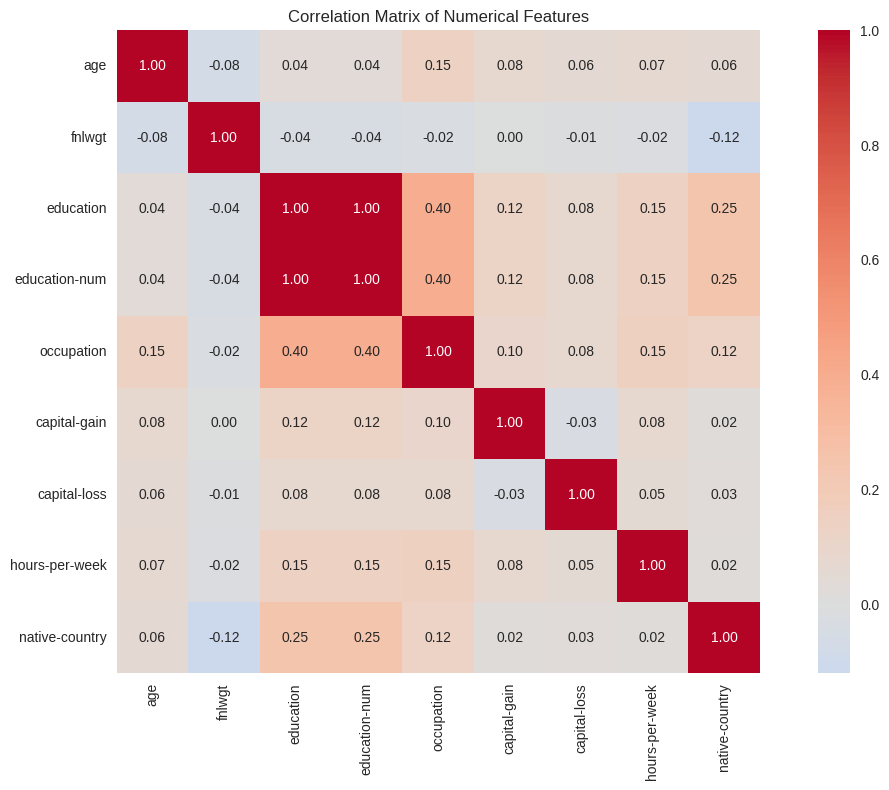


Strong correlations (|correlation| > 0.5):
education - education-num: 1.000


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

numerical_features = X_train.select_dtypes(include=['int64', 'float64']).columns
correlation_matrix = X_train[numerical_features].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(correlation_matrix,
            annot=True,  
            cmap='coolwarm',  
            center=0,  
            fmt='.2f',  
            square=True)  

plt.title('Correlation Matrix of Numerical Features')
plt.tight_layout()  
plt.show()

print("\nStrong correlations (|correlation| > 0.5):")
for i in range(len(correlation_matrix.columns)):
    for j in range(i+1, len(correlation_matrix.columns)):
        if abs(correlation_matrix.iloc[i,j]) > 0.5:
            print(f"{correlation_matrix.columns[i]} - {correlation_matrix.columns[j]}: {correlation_matrix.iloc[i,j]:.3f}")

# Step 9: Feature Scaling

Before addressing class imbalance, we apply feature scaling to the numerical features.
Scaling ensures that features contribute equally to the model training process and improves convergence for many machine learning algorithms.

### Scaling Methods:

#### 1. StandardScaler
- standardizes features by removing the mean and scaling to unit variance.

#### 2. MinMaxScaler
- scales features to a given range (usually [0, 1]).

#### 3. MaxAbsScaler

- scales features by their maximum absolute value.

#### 4. RobustScaler
- scales features using statistics that are robust to outliers.

#### 5. Normalizer
- scales individual samples to have unit norm.

---
 **Your Task**:
1. Choose a scaling method and explain your reasoning.
2. Implement your chosen method below.



In [ ]:
from sklearn.preprocessing import RobustScaler


numerical_features = ['age', 'fnlwgt', 'education-num',
                     'capital-gain', 'capital-loss', 'hours-per-week']

scaler = RobustScaler()

X_train[numerical_features] = scaler.fit_transform(X_train[numerical_features])

X_test[numerical_features] = scaler.transform(X_test[numerical_features])

print("Scaled features statistics:")
print(X_train[numerical_features].describe())

print("\nMedians:")
print(X_train[numerical_features].median())

print("\nIQR:")
print(X_train[numerical_features].quantile(0.75) -
      X_train[numerical_features].quantile(0.25))

Scaled features statistics:
                age        fnlwgt  education-num  capital-gain  capital-loss  \
count  32561.000000  32561.000000   32561.000000  32561.000000  32561.000000   
mean       0.079082      0.095806       0.026893   1077.648844     87.303830   
std        0.682022      0.885308       0.857573   7385.292085    402.960219   
min       -1.000000     -1.392933      -3.000000      0.000000      0.000000   
25%       -0.450000     -0.507691      -0.333333      0.000000      0.000000   
50%        0.000000      0.000000       0.000000      0.000000      0.000000   
75%        0.550000      0.492309       0.666667      0.000000      0.000000   
max        2.650000     10.957098       2.000000  99999.000000   4356.000000   

       hours-per-week  
count    32561.000000  
mean         0.087491  
std          2.469486  
min         -7.800000  
25%          0.000000  
50%          0.000000  
75%          1.000000  
max         11.800000  

Medians:
age               0.0
fnl

<p align="justify">
<font size=4>
<b> <font color='red'>Your Answer:</font></b><br>


</p>
</font>
<hr>


The Adult Income dataset includes the following numerical features with their respective ranges:
age: 17 to 90
fnlwgt: 12,285 to 1,484,705
education-num: 1 to 16
capital-gain: 0 to 99,999
capital-loss: 0 to 4,356
hours-per-week: 1 to 99

The features span vastly different ranges. For example, age has a small range (17–90), while fnlwgt has a much larger range (12,285–1,484,705). This can negatively affect models sensitive to feature magnitudes, such as linear models, k-NN, or SVMs.
 Features like capital-gain (up to 99,999) and capital-loss (up to 4,356) have extreme outliers, while most values are small or zero.
 Many features, such as age, fnlwgt, and hours-per-week, do not follow a normal distribution, which impacts the effectiveness of certain scaling methods.
capital-gain and capital-loss contain many zero values, which likely carry meaning (e.g., no gains or losses) and should be preserved in a meaningful way.



RobustScaler is appropriate for this dataset because:

It is immune to outliers.

It works well with non-Gaussian and skewed distributions.

It preserves meaningful zero values.

It ensures all features contribute fairly to model training.

# Step 10: Dealing with Class Imbalance

### Identifying Class Imbalance
In classification problems, it is common to have **imbalanced** classes, where one class has far more examples than the other. This can negatively impact model performance since many standard algorithms assume a balanced dataset.

**Question**: Where do we use resampling?

Our target variable `income` is imbalanced — most people earn `<=50K`.

This imbalance can cause models to:
- Be biased toward the majority class
- Fail to learn patterns of the minority class

### Resampling Techniques

#### 1. Random OverSampling
- Duplicate samples from the minority class

#### 2. Random UnderSampling
- Remove samples from the majority class

#### 3. SMOTE (Synthetic Minority Over-sampling Technique)
- Generate new synthetic samples from the minority class

---

 **Your Task**:
1. Inspect the class distribution.
2. Choose a resampling strategy and explain your reasoning.
3. Implement your strategy below.


The data shows approximately:
76% make <=50K (majority class)
24% make >50K (minority class)
Imbalance ratio of about 3:1

1. Random Oversampling
Pros:
No data loss
Simple to implement
Cons:
Risk of overfitting (duplicates exact copies)
Increases training time
Memory intensive
2. Random Undersampling
Pros:
Reduces training time
Can help with memory constraints
Cons:
Loses potentially valuable data
Risk of removing important patterns
Reduces overall dataset size
3. SMOTE
Pros:
Creates synthetic examples instead of duplicates
Preserves all majority class data
Better than simple oversampling for avoiding overfitting
Cons:
Can create noisy samples
Computationally more expensive
May not work well with high-dimensional data


Moderate Imbalance:
76:24 ratio is not severe (3:1)
Many real-world datasets have much worse imbalances (e.g., 99:1)
Models can often handle this level of imbalance well
Large Dataset Size:
We have sufficient minority class examples (~7,800 in training)
Even the minority class has enough samples for models to learn patterns
Real-World Distribution:
Using appropriate evaluation metrics (e.g., precision, recall, F1-score)
Adjusting class weights in the models
Using algorithms that handle imbalance well (e.g., gradient boosting)

In [ ]:

from sklearn.utils.class_weight import compute_class_weight


class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = dict(zip(np.unique(y_train), class_weights))

print("Suggested class weights:", class_weight_dict)


<p align="justify">
<font size=4>
<b> <font color='red'>Your Answer:</font></b><br>


</p>
</font>
<hr>

### Re-evaluating the Need for Resampling:  
<b> <font color='red'>Question:</font></b> In this case, should we use resampling or not, and why?  

<p align="justify">
<font size=4>
<b> <font color='red'>Your Answer:</font></b><br>


</p>
</font>
<hr>

# Step 11: Modeling and Evaluation

In this part of the project, you will apply and compare several machine learning models on the training dataset. Each model uses a different mathematical approach to learn from the data and make predictions. Your goal is to identify the most effective model based on the evaluation metrics and determine which model provides the best generalization to unseen data.

## 11.1 Overview of the Modeling Section
You need to implement a range of classifiers that represent different types of machine learning algorithms, including:

- **K-Nearest Neighbors (KNN):** A simple, non-parametric method that makes predictions based on the majority class of the nearest neighbors in the feature space.
- **Decision Trees:** A tree-like model where decisions are made based on feature values, with each branch representing a feature condition and each leaf representing a class label.
- **Random Forest:** An ensemble of decision trees that improves prediction accuracy by averaging multiple models to reduce overfitting.
- **Gradient Boosting Methods (XGBoost, LightGBM):** Advanced ensemble techniques that build trees sequentially, where each new tree attempts to correct the errors of the previous one.
- **Logistic Regression:** A linear model used for binary or multi-class classification that predicts the probability of class membership.
- **Support Vector Machines (SVM):** A classifier that finds the hyperplane that best separates data points of different classes.
- **Neural Networks:** A class of models inspired by biological neural networks, capable of learning complex patterns in large datasets.

**Write a function that:**

- **Takes** `y_test` (true labels) and `y_pred` (predicted labels),
- **Computes**: Accuracy, Precision, Recall, F1,
- **Plots**: ROC Curve + AUC and Precision-Recall curve,
- **Displays**: Confusion Matrix.

**Note: You may need to read Part 13 before implementing this function.**

In [ ]:
def evaluate_model(y_test, y_pred, y_pred_proba=None, model_name="Model"):

    from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                               f1_score, confusion_matrix, roc_curve,
                               precision_recall_curve, auc, average_precision_score)
    import matplotlib.pyplot as plt
    import seaborn as sns

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    print(f"\n{model_name} Performance Metrics:")
    print("-" * 40)
    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1 Score:  {f1:.4f}")

    plt.figure(figsize=(15, 5))

    plt.subplot(131)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix - {model_name}')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')

    if y_pred_proba is not None:
       
        plt.subplot(132)
        fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
        roc_auc = auc(fpr, tpr)

        plt.plot(fpr, tpr, color='darkorange', lw=2,
                label=f'ROC curve (AUC = {roc_auc:.2f})')
        plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
        plt.xlim([0.0, 1.0])
        plt.ylim([0.0, 1.05])
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.title(f'ROC Curve - {model_name}')
        plt.legend(loc="lower right")


        plt.subplot(133)
        precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_pred_proba)
        avg_precision = average_precision_score(y_test, y_pred_proba)

        plt.plot(recall_curve, precision_curve, color='blue', lw=2,
                label=f'PR curve (AP = {avg_precision:.2f})')
        plt.xlabel('Recall')
        plt.ylabel('Precision')
        plt.title(f'Precision-Recall Curve - {model_name}')
        plt.legend(loc="lower left")

    plt.tight_layout()
    plt.show()

    return {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1
    }


###1)K-Nearest Neighbors (KNN)

KNN is a simple algorithm that makes predictions based on the closest data points in the training set. It looks at the ‘K’ nearest neighbors (based on distance) to a new point and assigns the most common class among those neighbors.

 **Your Task**:
1.  Implement and train the KNN classifier on the training dataset.(and then evaluate it on the test dataset)

Exception ignored on calling ctypes callback function: <function ThreadpoolController._find_libraries_with_dl_iterate_phdr.<locals>.match_library_callback at 0x78920c272a20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/threadpoolctl.py", line 1005, in match_library_callback
    self._make_controller_from_path(filepath)
  File "/usr/local/lib/python3.11/dist-packages/threadpoolctl.py", line 1187, in _make_controller_from_path
    lib_controller = controller_class(
                     ^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.11/dist-packages/threadpoolctl.py", line 114, in __init__
    self.dynlib = ctypes.CDLL(filepath, mode=_RTLD_NOLOAD)
                  ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.11/ctypes/__init__.py", line 376, in __init__
    self._handle = _dlopen(self._name, mode)
                   ^^^^^^^^^^^^^^^^^^^^^^^^^
OSError: dlopen() error



Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.93      0.90     12435
           1       0.72      0.57      0.64      3846

    accuracy                           0.85     16281
   macro avg       0.80      0.75      0.77     16281
weighted avg       0.84      0.85      0.84     16281


K-Nearest Neighbors Performance Metrics:
----------------------------------------
Accuracy:  0.8458
Precision: 0.7184
Recall:    0.5712
F1 Score:  0.6364


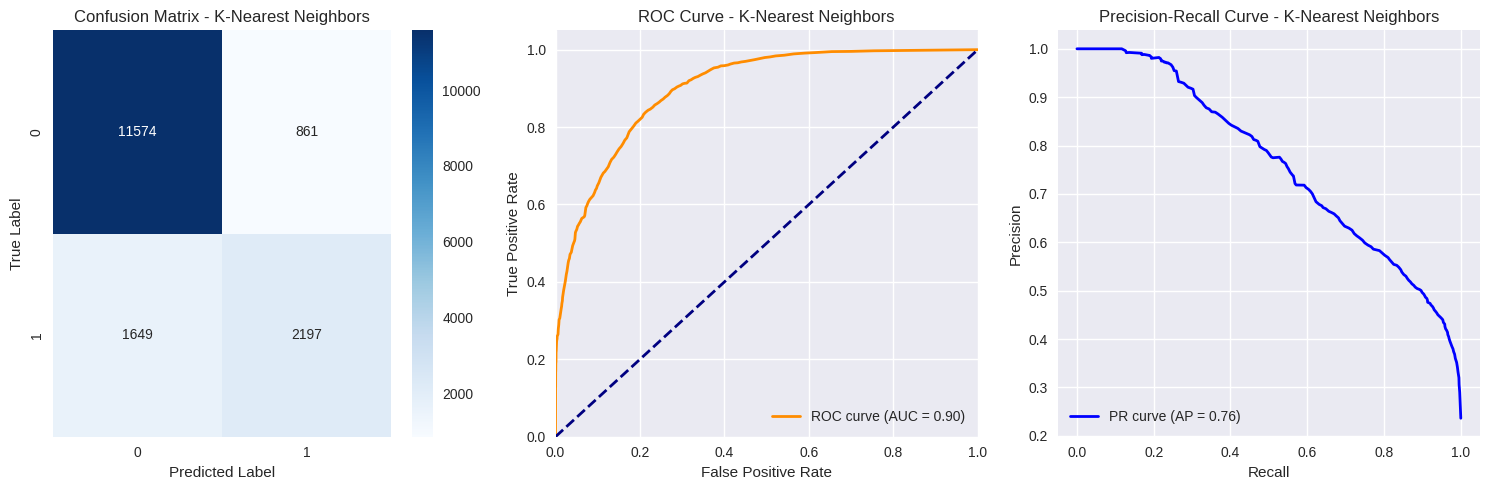

{'accuracy': 0.8458325655672256,
 'precision': 0.7184434270765206,
 'recall': 0.5712428497139885,
 'f1': 0.6364426419466975}

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report


k = int(np.sqrt(len(X_train)))
knn = KNeighborsClassifier(n_neighbors=k, weights='uniform', metric='euclidean')

knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)
y_pred_proba = knn.predict_proba(X_test)[:, 1]  


print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred))


evaluate_model(y_test, y_pred, y_pred_proba, "K-Nearest Neighbors")

2. Answer this question:How does  'K' in KNN  affect the model's performance?

<b> <font color='red'>Your Answer:</font></b><br>

The value of K in K-Nearest Neighbors (KNN) significantly affects model performance by controlling the bias-variance tradeoff. A small K (like 1 or 3) results in low bias and high variance, making the model sensitive to noise and prone to overfitting. In contrast, a large K (like 15 or more) introduces high bias and low variance, leading to underfitting as the model becomes too generalized and misses local patterns.

###2)Decision Tree

A decision tree makes predictions by splitting the data into smaller groups based on feature values. At each step (node), it chooses the best condition to separate the data, leading to a tree-like structure where each leaf gives a prediction.

 **Your Task**:
1. Implement and train the Decision Tree classifier on the training dataset.(and then evaluate it on the test dataset)


Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.94      0.91     12435
           1       0.76      0.60      0.67      3846

    accuracy                           0.86     16281
   macro avg       0.82      0.77      0.79     16281
weighted avg       0.86      0.86      0.86     16281


Decision Tree Performance Metrics:
----------------------------------------
Accuracy:  0.8622
Precision: 0.7644
Recall:    0.6024
F1 Score:  0.6738


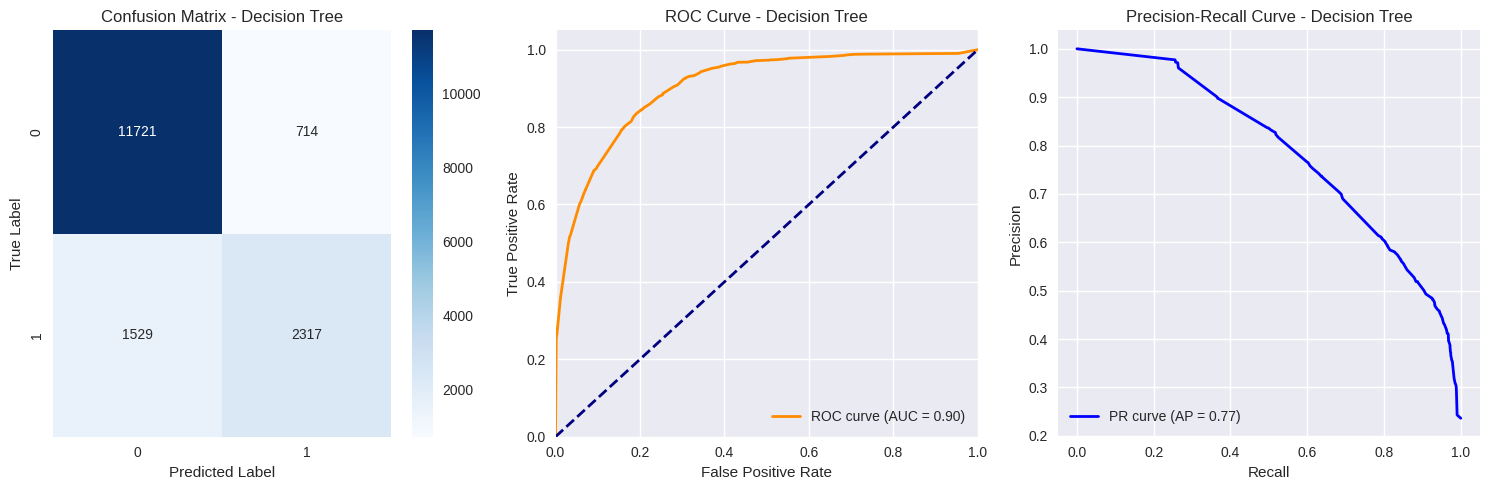

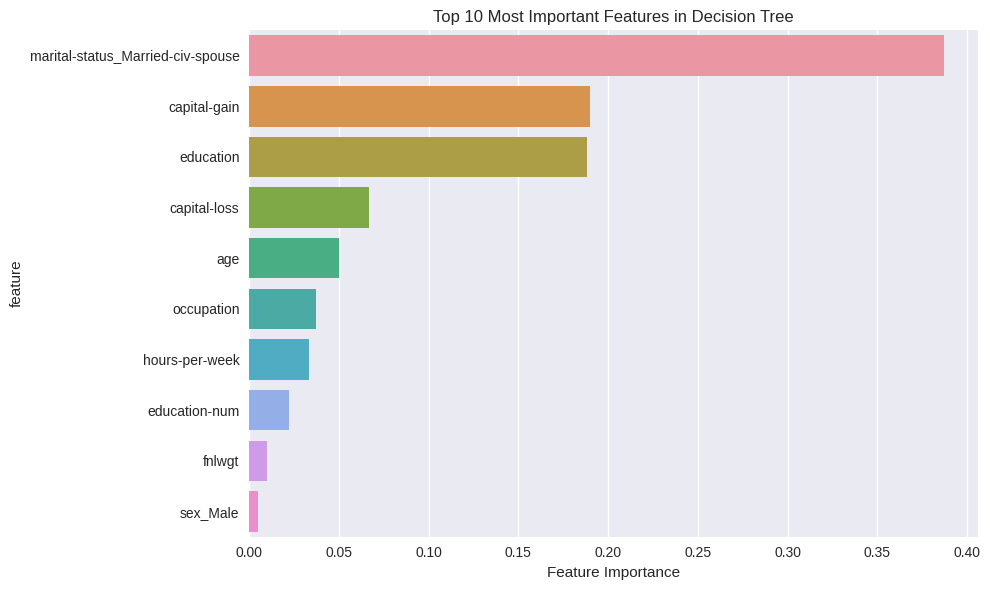

In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(
    max_depth=10,        
    min_samples_split=10,  
    min_samples_leaf=5,    
    random_state=42        
)


dt.fit(X_train, y_train)

y_pred = dt.predict(X_test)
y_pred_proba = dt.predict_proba(X_test)[:, 1]  

print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred))


evaluate_model(y_test, y_pred, y_pred_proba, "Decision Tree")

feature_importance = pd.DataFrame({
    'feature': X_train.columns,
    'importance': dt.feature_importances_
})
feature_importance = feature_importance.sort_values('importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='importance', y='feature', data=feature_importance.head(10))
plt.title('Top 10 Most Important Features in Decision Tree')
plt.xlabel('Feature Importance')
plt.tight_layout()
plt.show()

2. Answer this question:How does a decision tree decide where to split the data?

<b> <font color='red'>Your Answer:</font></b><br>


A decision tree decides where to split the data by evaluating all possible splits across features and selecting the one that results in the highest purity gain in the target variable. 

###3)Random Forest (Ensemble of Decision Trees)

Random Forest is an ensemble method that builds many decision trees on different parts of the data and combines their results. Each tree votes on the prediction, and the majority vote is taken as the final output.

 **Your Task**:
1. Implement and train the Random Forest classifier on the training dataset.(and then evaluate it on the test dataset)


Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.81      0.87     12435
           1       0.58      0.85      0.69      3846

    accuracy                           0.82     16281
   macro avg       0.77      0.83      0.78     16281
weighted avg       0.86      0.82      0.83     16281


Random Forest Performance Metrics:
----------------------------------------
Accuracy:  0.8216
Precision: 0.5838
Recall:    0.8526
F1 Score:  0.6930


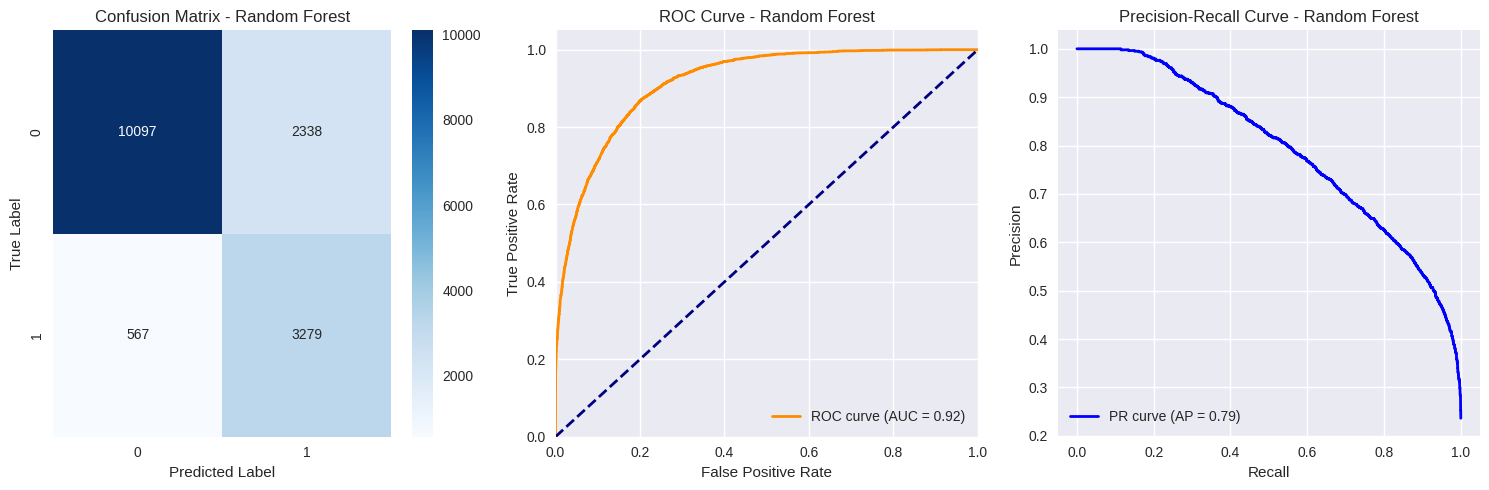

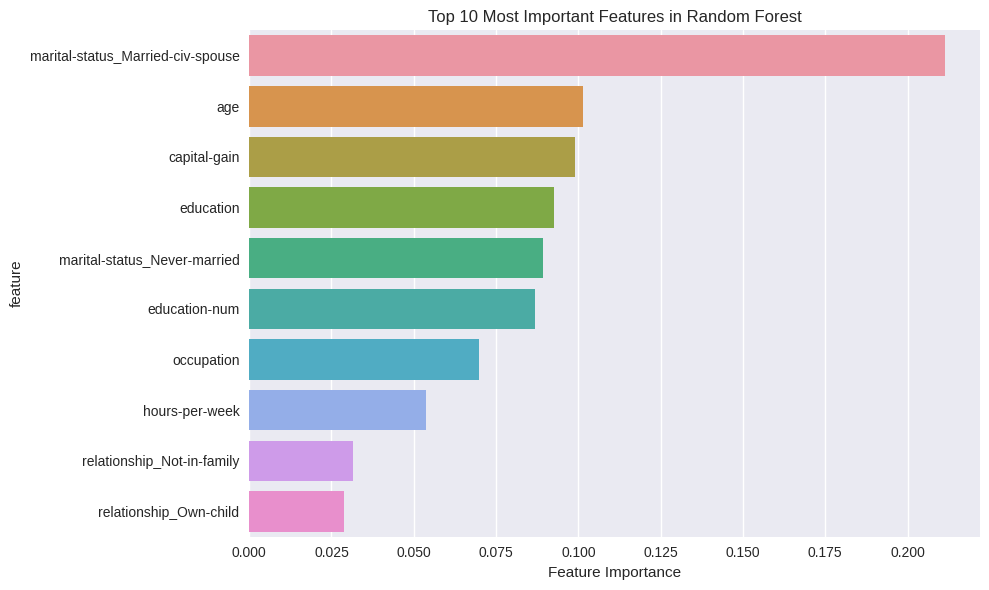


Top 5 Most Important Features:
                              feature  importance
17  marital-status_Married-civ-spouse    0.211425
0                                 age    0.101427
5                        capital-gain    0.099009
2                           education    0.092607
19       marital-status_Never-married    0.089332


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,      
    max_depth=15,          
    min_samples_split=10,  
    min_samples_leaf=5,   
    class_weight=class_weight_dict, 
    random_state=42,       
    n_jobs=-1             
)


rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)
y_pred_proba = rf.predict_proba(X_test)[:, 1]  

print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred))

evaluate_model(y_test, y_pred, y_pred_proba, "Random Forest")


feature_importance = pd.DataFrame({
    'feature': X_train.columns,
    'importance': rf.feature_importances_
})
feature_importance = feature_importance.sort_values('importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='importance', y='feature', data=feature_importance.head(10))
plt.title('Top 10 Most Important Features in Random Forest')
plt.xlabel('Feature Importance')
plt.tight_layout()
plt.show()


print("\nTop 5 Most Important Features:")
print(feature_importance.head().to_string())

2. Answer this question:Why does Random Forest use more than one decision tree?

<b> <font color='red'>Your Answer:</font></b><br>


By building multiple trees on different random subsets of the data and features, it combines their outputs—typically through majority voting for classification or averaging for regression. This ensemble approach reduces the variance of individual trees, which are often prone to overfitting, and produces more stable, robust, and generalizable results.

###4)Gradient Boosting Models (XGBoost, LightGBM, CatBoost)

These models build decision trees one at a time, where each new tree focuses on fixing the errors made by the previous ones. This process is called “boosting.” They add up the results of many trees to improve accuracy step-by-step.

###4-1)XGBoost

XGBoost builds decision trees sequentially, where each new tree focuses on correcting the errors of the previous ones. It uses a special technique called “gradient boosting” to minimize the overall loss function efficiently.

 **Your Task**:
1. implement and train the XGBoost classifier on the training dataset.(and then evaluate it on the test dataset)

[0]	validation_0-error:0.22566	validation_0-auc:0.89914
[1]	validation_0-error:0.21325	validation_0-auc:0.90791
[2]	validation_0-error:0.20896	validation_0-auc:0.90997
[3]	validation_0-error:0.20803	validation_0-auc:0.91007
[4]	validation_0-error:0.20963	validation_0-auc:0.91115
[5]	validation_0-error:0.20779	validation_0-auc:0.91172
[6]	validation_0-error:0.20472	validation_0-auc:0.91137
[7]	validation_0-error:0.20195	validation_0-auc:0.91231
[8]	validation_0-error:0.20109	validation_0-auc:0.91211
[9]	validation_0-error:0.19907	validation_0-auc:0.91227
[10]	validation_0-error:0.19870	validation_0-auc:0.91300
[11]	validation_0-error:0.19428	validation_0-auc:0.91362
[12]	validation_0-error:0.19268	validation_0-auc:0.91470
[13]	validation_0-error:0.19034	validation_0-auc:0.91511
[14]	validation_0-error:0.18948	validation_0-auc:0.91525
[15]	validation_0-error:0.19028	validation_0-auc:0.91569
[16]	validation_0-error:0.18985	validation_0-auc:0.91636
[17]	validation_0-error:0.18918	validatio

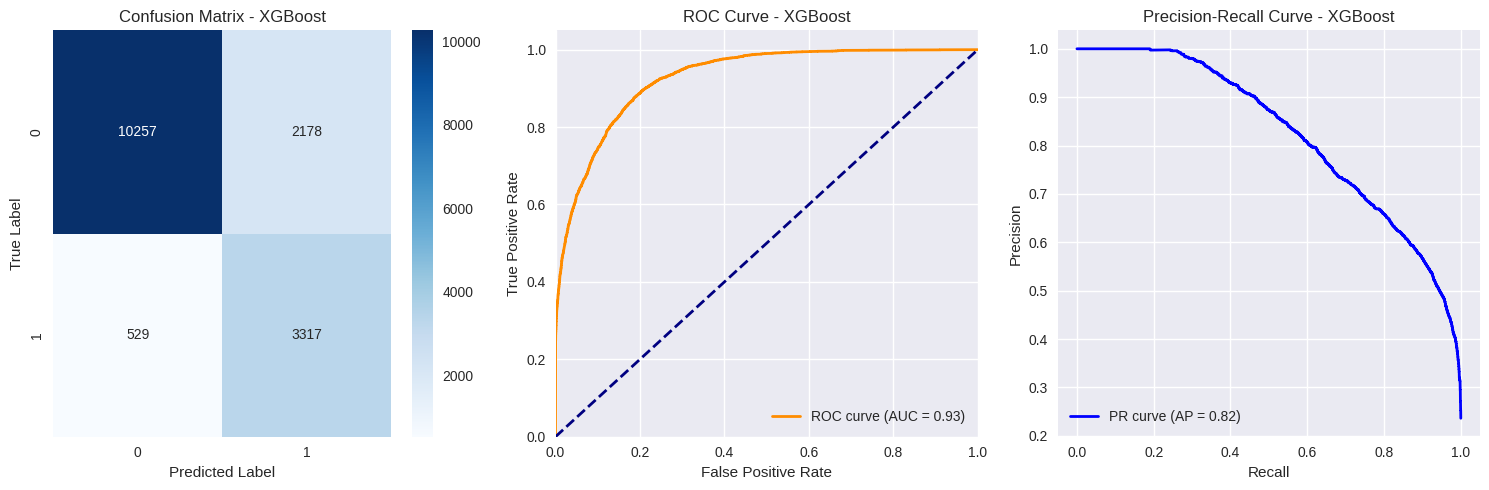

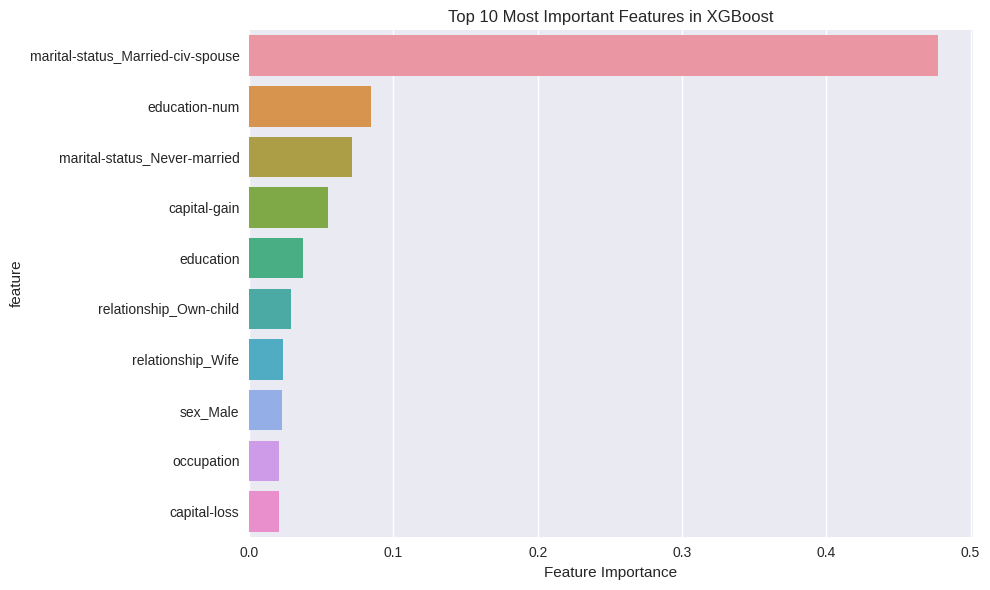


Top 5 Most Important Features:
                              feature  importance
17  marital-status_Married-civ-spouse    0.477534
3                       education-num    0.084149
19       marital-status_Never-married    0.071348
5                        capital-gain    0.054558
2                           education    0.037493


In [ ]:
import xgboost as xgb
from sklearn.metrics import classification_report
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

xgb_clf = xgb.XGBClassifier(
    n_estimators=100,      
    max_depth=6,          
    learning_rate=0.1,    
    subsample=0.8,        
    colsample_bytree=0.8,  
    scale_pos_weight=3.25,
    random_state=42,       
    n_jobs=-1,            
    eval_metric=['error', 'auc']  
)

xgb_clf.fit(
    X_train,
    y_train,
    eval_set=[(X_test, y_test)],
    verbose=True
)


y_pred = xgb_clf.predict(X_test)
y_pred_proba = xgb_clf.predict_proba(X_test)[:, 1]

print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred))

evaluate_model(y_test, y_pred, y_pred_proba, "XGBoost")

feature_importance = pd.DataFrame({
    'feature': X_train.columns,
    'importance': xgb_clf.feature_importances_
})
feature_importance = feature_importance.sort_values('importance', ascending=False)


plt.figure(figsize=(10, 6))
sns.barplot(x='importance', y='feature', data=feature_importance.head(10))
plt.title('Top 10 Most Important Features in XGBoost')
plt.xlabel('Feature Importance')
plt.tight_layout()
plt.show()

print("\nTop 5 Most Important Features:")
print(feature_importance.head().to_string())

2. Answer this question:Why does XGBoost build trees in sequence?

<b> <font color='red'>Your Answer:</font></b><br>

because it uses gradient boosting, a method where each new tree is trained to correct the errors made by the previous ones. Unlike Random Forest, which builds trees independently, XGBoost adds each tree step by step, using the residuals (gradients of the loss function) from earlier trees to improve prediction accuracy. 

###4-2)LightGBM

LightGBM (Light Gradient Boosting Machine) is a fast, efficient gradient LightGBM is a gradient boosting algorithm that grows trees leaf-wise instead of level-wise, meaning it chooses the leaf with the highest error to grow, which leads to faster and potentially more accurate learning.

 **Your Task**:
1. Implement and train the LightGBM classifier on the training dataset.(and then evaluate it on the test dataset)


Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.82      0.88     12435
           1       0.60      0.86      0.71      3846

    accuracy                           0.83     16281
   macro avg       0.77      0.84      0.79     16281
weighted avg       0.87      0.83      0.84     16281


LightGBM Performance Metrics:
----------------------------------------
Accuracy:  0.8292
Precision: 0.5955
Recall:    0.8640
F1 Score:  0.7051


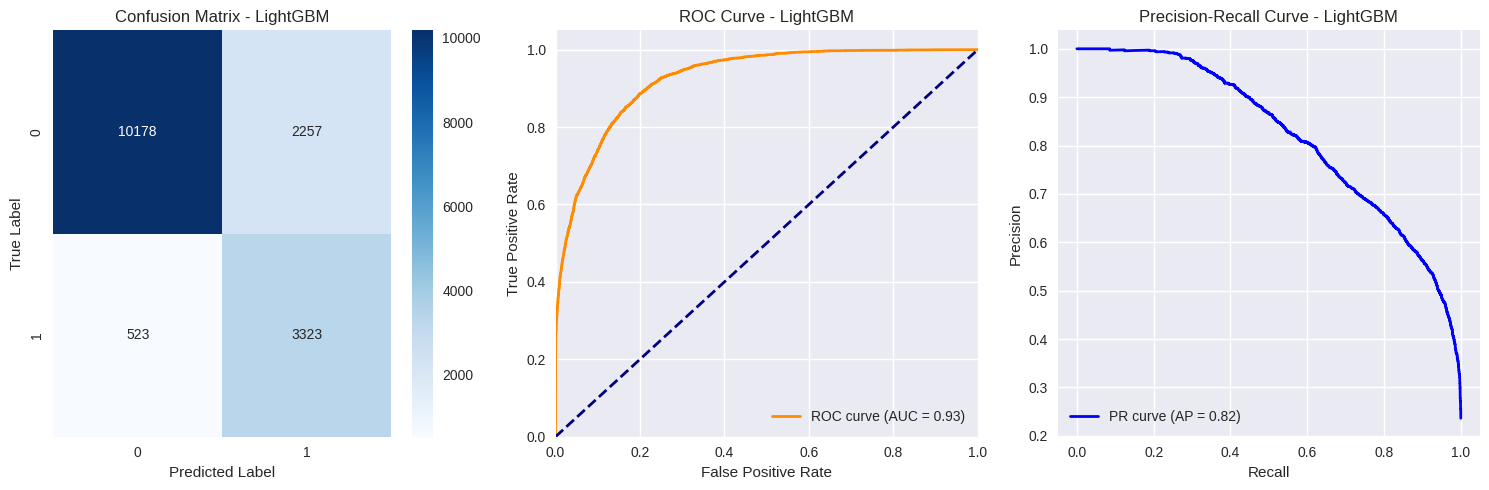

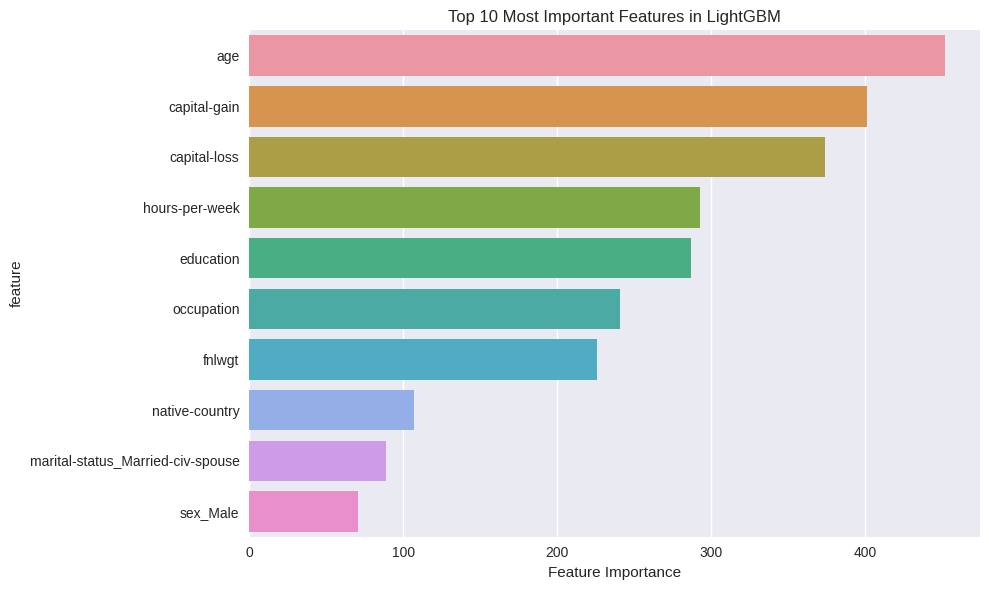


Top 5 Most Important Features:
          feature  importance
0             age         452
5    capital-gain         401
6    capital-loss         374
7  hours-per-week         293
2       education         287


In [ ]:
import lightgbm as lgb
from sklearn.metrics import classification_report
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


lgb_train = lgb.Dataset(X_train, y_train)
lgb_eval = lgb.Dataset(X_test, y_test, reference=lgb_train)

params = {
    'boosting_type': 'gbdt',
    'objective': 'binary',
    'metric': ['binary_logloss', 'auc'],
    'num_leaves': 31,
    'learning_rate': 0.05,
    'feature_fraction': 0.9,
    'bagging_fraction': 0.8,
    'bagging_freq': 5,
    'verbose': 0,
    'num_threads': -1,
    'scale_pos_weight': 3.25 
}


num_round = 100
lgb_model = lgb.train(
    params,
    lgb_train,
    num_round,
    valid_sets=[lgb_train, lgb_eval]
)

y_pred = (lgb_model.predict(X_test) > 0.5).astype(int)
y_pred_proba = lgb_model.predict(X_test)


print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred))


evaluate_model(y_test, y_pred, y_pred_proba, "LightGBM")

feature_importance = pd.DataFrame({
    'feature': X_train.columns,
    'importance': lgb_model.feature_importance()
})
feature_importance = feature_importance.sort_values('importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='importance', y='feature', data=feature_importance.head(10))
plt.title('Top 10 Most Important Features in LightGBM')
plt.xlabel('Feature Importance')
plt.tight_layout()

print("\nTop 5 Most Important Features:")
print(feature_importance.head().to_string())

2. Answer this question:How does LightGBM grow trees differently?

<b> <font color='red'>Your Answer:</font></b><br>

LightGBM grows trees leaf-wise, unlike traditional methods (like XGBoost) that grow level-wise. In leaf-wise growth, at each step, LightGBM finds the leaf with the highest loss reduction and splits it, leading to deeper trees and faster convergence. 

###5)Logistic Regression

Logistic Regression is a model that calculates the probability of a data point belonging to a class. It uses a linear combination of input features and passes the result through a function that outputs values between 0 and 1 (called the sigmoid function).

 **Your Task**:
1. Implement and train the Logistic Regression classifier on the training dataset.(and then evaluate it on the test dataset)

/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.79      0.86     12435
           1       0.55      0.84      0.67      3846

    accuracy                           0.80     16281
   macro avg       0.75      0.82      0.76     16281
weighted avg       0.85      0.80      0.81     16281


Logistic Regression Performance Metrics:
----------------------------------------
Accuracy:  0.8019
Precision: 0.5528
Recall:    0.8437
F1 Score:  0.6680


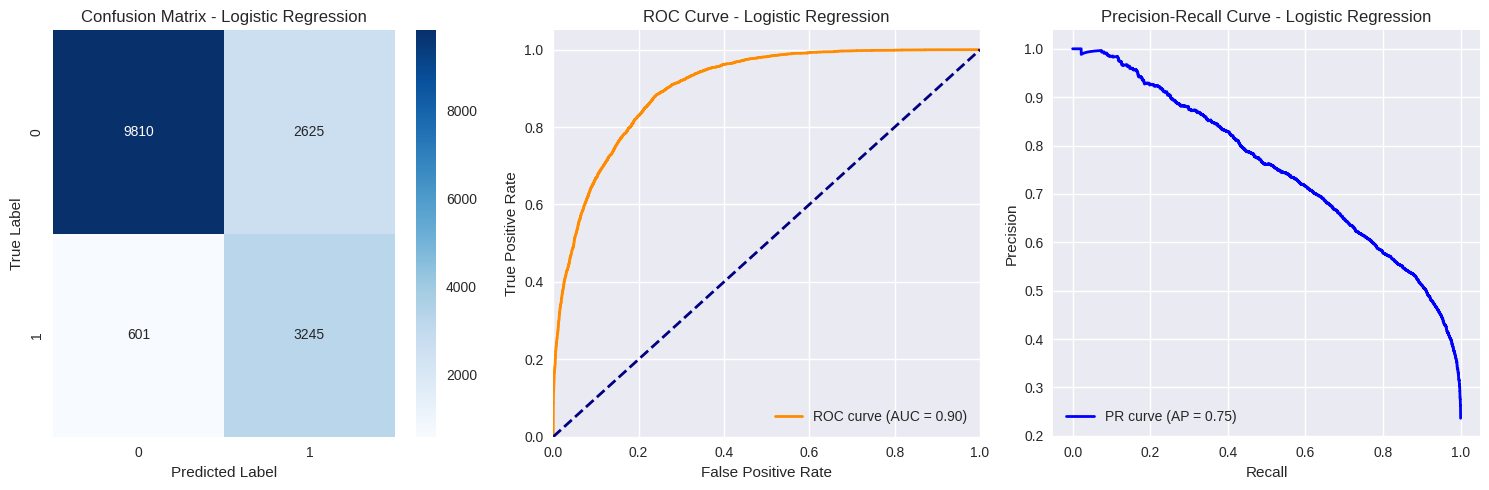

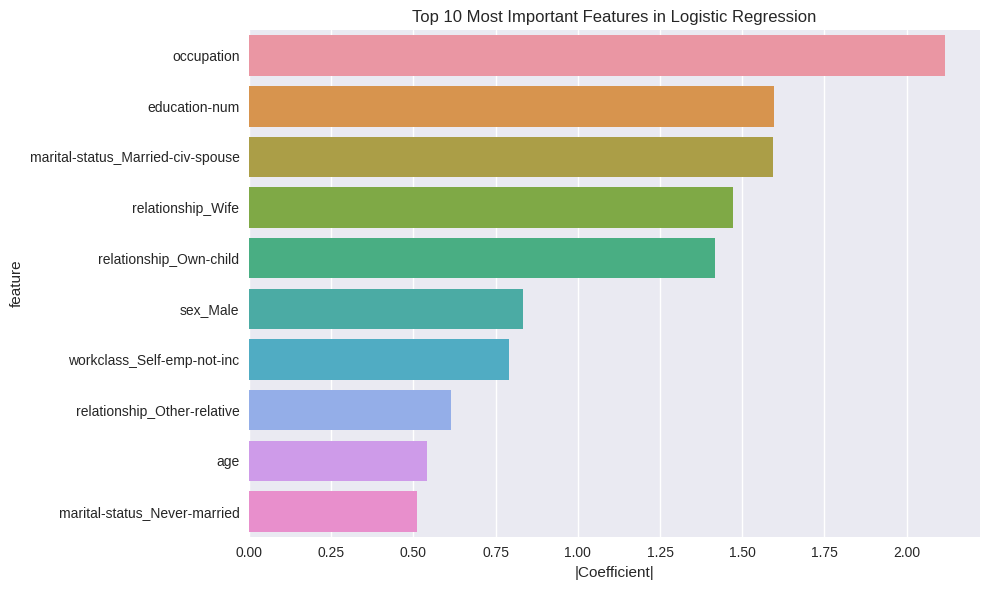


Top 5 Most Important Features:
                              feature  importance
4                          occupation    2.117705
3                       education-num    1.595470
17  marital-status_Married-civ-spouse    1.595062
26                  relationship_Wife    1.470787
24             relationship_Own-child    1.416243


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

lr = LogisticRegression(
    max_iter=1000,        
    class_weight='balanced', 
    random_state=42,      
    n_jobs=-1           
)


lr.fit(X_train, y_train)


y_pred = lr.predict(X_test)
y_pred_proba = lr.predict_proba(X_test)[:, 1]  

print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred))


evaluate_model(y_test, y_pred, y_pred_proba, "Logistic Regression")


feature_importance = pd.DataFrame({
    'feature': X_train.columns,
    'importance': np.abs(lr.coef_[0])  
})
feature_importance = feature_importance.sort_values('importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='importance', y='feature', data=feature_importance.head(10))
plt.title('Top 10 Most Important Features in Logistic Regression')
plt.xlabel('|Coefficient|')
plt.tight_layout()
plt.show()

print("\nTop 5 Most Important Features:")
print(feature_importance.head().to_string())

2. Answer this question:How is the linear formula used in this logistic regression?

<b> <font color='red'>Your Answer:</font></b><br>

In logistic regression, the linear formula is used to compute a weighted sum of input features, which is then transformed using the sigmoid function to produce a probability.

###6)SVM with different kernels (e.g., linear, RBF)

SVM finds a line (or a plane in higher dimensions) that best separates the classes in the data. It tries to place this line as far as possible from the nearest points of each class. With different kernels (like linear or RBF), it can also handle non-linear data.

 **Your Task**:
1. Implement and train the SVM classifier on the training dataset.(and then evaluate it on the test dataset)

X_train_gpu dtypes:
 age                                     float64
fnlwgt                                  float64
education                                 int64
education-num                           float64
occupation                              float64
capital-gain                            float64
capital-loss                            float64
hours-per-week                          float64
native-country                          float64
workclass_Local-gov                        bool
workclass_Never-worked                     bool
workclass_Private                          bool
workclass_Self-emp-inc                     bool
workclass_Self-emp-not-inc                 bool
workclass_State-gov                        bool
workclass_Without-pay                      bool
marital-status_Married-AF-spouse           bool
marital-status_Married-civ-spouse          bool
marital-status_Married-spouse-absent       bool
marital-status_Never-married               bool
marital-status_Sepa

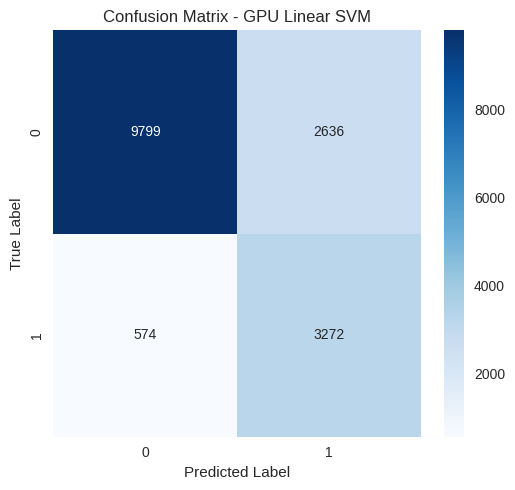


Training GPU RBF SVM…

RBF SVM - Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.95      0.91     12435
           1       0.76      0.55      0.64      3846

    accuracy                           0.85     16281
   macro avg       0.82      0.75      0.77     16281
weighted avg       0.85      0.85      0.85     16281


GPU RBF SVM Performance Metrics:
----------------------------------------
Accuracy:  0.8539
Precision: 0.7650
Recall:    0.5510
F1 Score:  0.6406


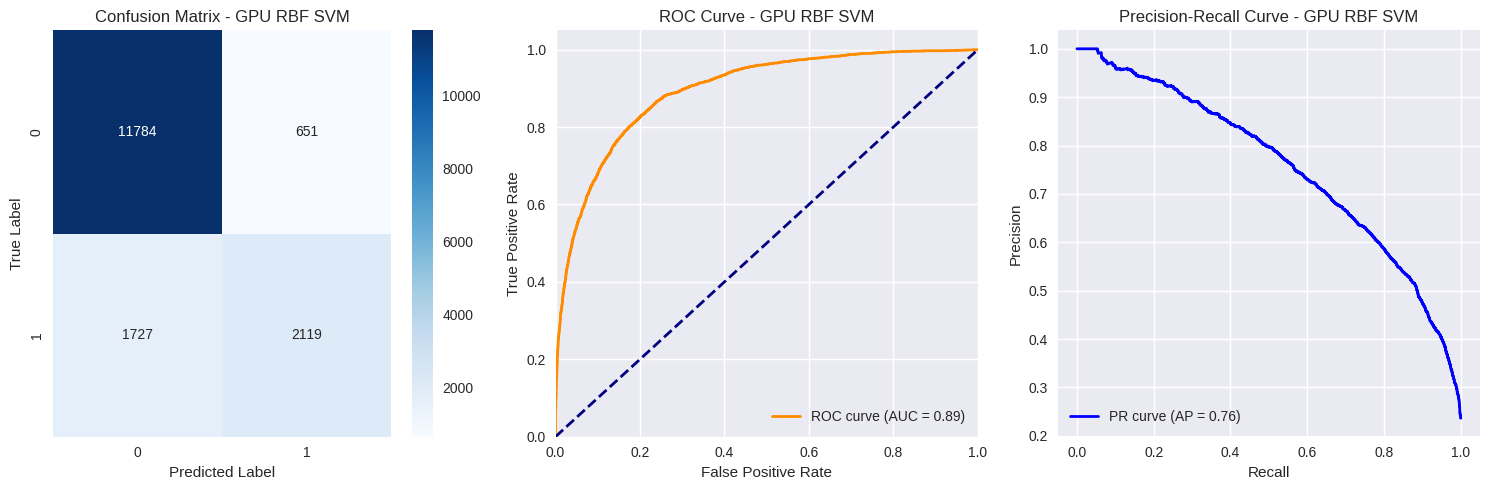

Number of features: 32
Number of coefficients: 32


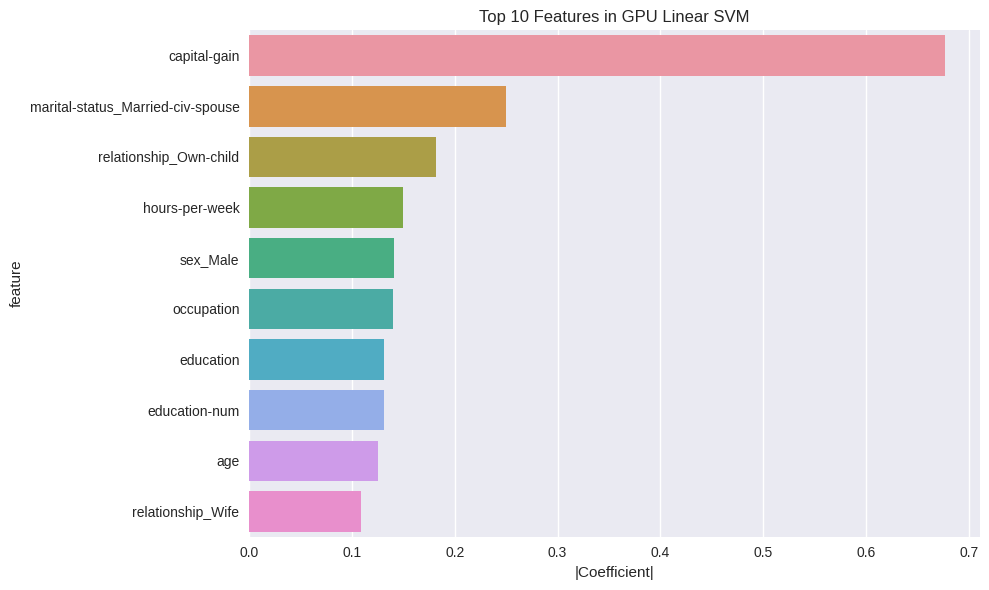


Top 5 Most Important Features (GPU Linear SVM):
                              feature  importance
5                        capital-gain    0.676971
17  marital-status_Married-civ-spouse    0.249591
24             relationship_Own-child    0.181782
7                      hours-per-week    0.149178
31                           sex_Male    0.141290


In [ ]:
import cudf
import cupy as cp
from cuml.svm import LinearSVC, SVC as cuSVC
from cuml.preprocessing import StandardScaler
from sklearn.metrics import classification_report
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

X_train_gpu = cudf.DataFrame.from_pandas(X_train)
y_train_gpu = cudf.Series(y_train)
X_test_gpu = cudf.DataFrame.from_pandas(X_test)
y_test_gpu = cudf.Series(y_test)

print("X_train_gpu dtypes:\n", X_train_gpu.dtypes)
print("y_train_gpu dtype:", y_train_gpu.dtype)
print("Number of unique classes in y_train_gpu:", y_train_gpu.nunique())
print("Class distribution:\n", y_train_gpu.value_counts())


X_train_gpu = X_train_gpu.astype('float32')
X_test_gpu = X_test_gpu.astype('float32')
y_train_gpu = y_train_gpu.astype('int32')
y_test_gpu = y_test_gpu.astype('int32')

X_train_gpu = X_train_gpu.reset_index(drop=True)
X_test_gpu = X_test_gpu.reset_index(drop=True)
y_train_gpu = y_train_gpu.reset_index(drop=True)
y_test_gpu = y_test_gpu.reset_index(drop=True)


scaler = StandardScaler()
X_train_gpu = scaler.fit_transform(X_train_gpu)
X_test_gpu = scaler.transform(X_test_gpu)


X_train_cupy = X_train_gpu.to_cupy()
X_test_cupy = X_test_gpu.to_cupy()
y_train_cupy = y_train_gpu.to_cupy()
y_test_cupy = y_test_gpu.to_cupy()

cu_svm_linear = LinearSVC(
    class_weight='balanced'
)

cu_svm_rbf = cuSVC(
    kernel='rbf',
    probability=True,
    class_weight=None, 
    random_state=42     
)

print("Training GPU Linear SVM…")
cu_svm_linear.fit(X_train_cupy, y_train_cupy)


y_pred_lin_cupy = cu_svm_linear.predict(X_test_cupy)
y_pred_linear = cp.asnumpy(y_pred_lin_cupy)
y_test_host = cp.asnumpy(y_test_cupy)

print("\nLinear SVM - Detailed Classification Report:")
print(classification_report(y_test_host, y_pred_linear))


evaluate_model(y_test_host, y_pred_linear, None, "GPU Linear SVM")

print("\nTraining GPU RBF SVM…")
cu_svm_rbf.fit(X_train_cupy, y_train_cupy)

y_pred_rbf_cupy = cu_svm_rbf.predict(X_test_cupy)
y_pred_proba_rbf_cupy = cu_svm_rbf.predict_proba(X_test_cupy)[:, 1]

y_pred_rbf = cp.asnumpy(y_pred_rbf_cupy)
y_pred_proba_rbf = cp.asnumpy(y_pred_proba_rbf_cupy)

print("\nRBF SVM - Detailed Classification Report:")
print(classification_report(y_test_host, y_pred_rbf))

evaluate_model(y_test_host, y_pred_rbf, y_pred_proba_rbf, "GPU RBF SVM")


if hasattr(cu_svm_linear, 'coef_'):
 
    coefs = cp.abs(cu_svm_linear.coef_).flatten().get()  
    print("Number of features:", len(X_train.columns))
    print("Number of coefficients:", len(coefs))


    if len(coefs) != len(X_train.columns):
        raise ValueError(f"Mismatch: {len(coefs)} coefficients vs {len(X_train.columns)} features")

    feature_importance = pd.DataFrame({
        'feature': X_train.columns,
        'importance': coefs
    }).sort_values('importance', ascending=False)

    plt.figure(figsize=(10, 6))
    sns.barplot(x='importance', y='feature', data=feature_importance.head(10))
    plt.title('Top 10 Features in GPU Linear SVM')
    plt.xlabel('|Coefficient|')
    plt.tight_layout()
    plt.show()

    print("\nTop 5 Most Important Features (GPU Linear SVM):")
    print(feature_importance.head().to_string())

2. Answer this question:How does SVM handle data that can’t be separated by a straight line?

<b> <font color='red'>Your Answer:</font></b><br>

Instead of working in the original feature space, SVM uses a kernel function to implicitly map the data into a higher-dimensional space where a linear separator (hyperplane) can exist. 

###7)Neural Networks (simple MLP for classification)

A Multi-Layer Perceptron (MLP) is a neural network made of layers of connected nodes (neurons). Each neuron takes inputs, applies weights and an activation function, and passes the result to the next layer. It learns by adjusting the weights to reduce prediction error.

 **Your Task**:
1. Implement and train the Neural Networks classifier (simple MLP for classification) on the training dataset.(and then evaluate it on the test dataset)

Training Neural Network...
Iteration 1, loss = 0.39968479
Validation score: 0.806263
Iteration 2, loss = 0.36748106
Validation score: 0.808413
Iteration 3, loss = 0.36471225
Validation score: 0.806263
Iteration 4, loss = 0.35993319
Validation score: 0.810255
Iteration 5, loss = 0.35941637
Validation score: 0.805956
Iteration 6, loss = 0.35649680
Validation score: 0.811176
Iteration 7, loss = 0.35596078
Validation score: 0.809027
Iteration 8, loss = 0.35618696
Validation score: 0.809027
Iteration 9, loss = 0.35443798
Validation score: 0.805956
Iteration 10, loss = 0.35354790
Validation score: 0.806263
Iteration 11, loss = 0.35309750
Validation score: 0.810869
Iteration 12, loss = 0.35273409
Validation score: 0.817931
Iteration 13, loss = 0.35309366
Validation score: 0.814246
Iteration 14, loss = 0.35209513
Validation score: 0.812404
Iteration 15, loss = 0.35242387
Validation score: 0.816395
Iteration 16, loss = 0.35182415
Validation score: 0.811790
Iteration 17, loss = 0.35257272
Valida

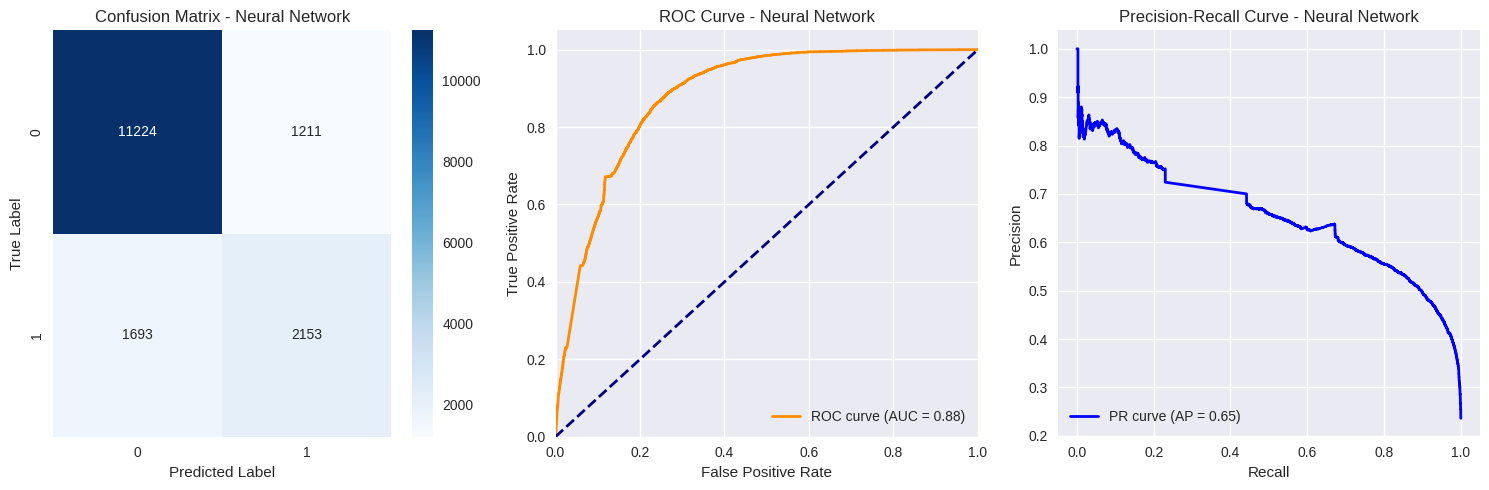

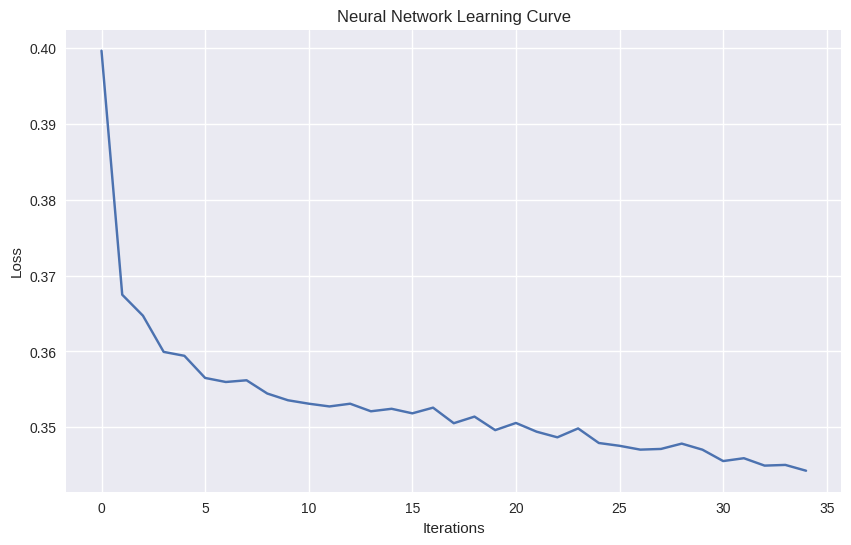

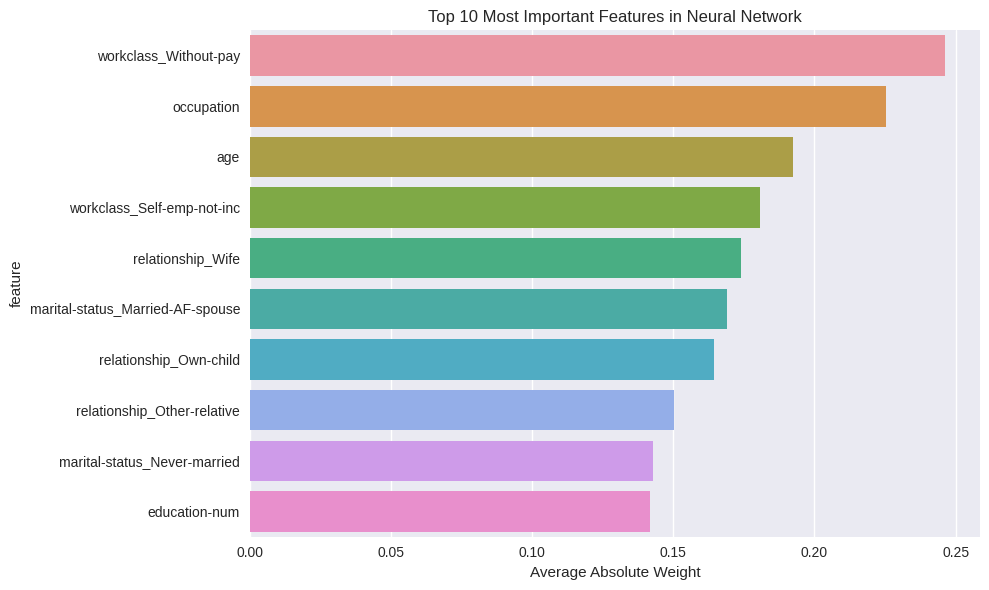


Top 5 Most Important Features:
                       feature  importance
15       workclass_Without-pay    0.246336
4                   occupation    0.225191
0                          age    0.192531
13  workclass_Self-emp-not-inc    0.180744
26           relationship_Wife    0.174016


In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

mlp = MLPClassifier(
    hidden_layer_sizes=(128,64,64,32),  
    activation='tanh',            
    solver='adam',               
    batch_size='auto',           
    learning_rate='adaptive',    
    max_iter=5000,             
    random_state=42,           
    verbose=True,             
    early_stopping=True,      
    validation_fraction=0.1     
)

print("Training Neural Network...")
mlp.fit(X_train, y_train)

y_pred = mlp.predict(X_test)
y_pred_proba = mlp.predict_proba(X_test)[:, 1]

print("\nNeural Network - Detailed Classification Report:")
print(classification_report(y_test, y_pred))

evaluate_model(y_test, y_pred, y_pred_proba, "Neural Network")

plt.figure(figsize=(10, 6))
plt.plot(mlp.loss_curve_)
plt.title('Neural Network Learning Curve')
plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.grid(True)
plt.show()


feature_importance = np.abs(mlp.coefs_[0]).mean(axis=1)
feature_importance_df = pd.DataFrame({
    'feature': X_train.columns,
    'importance': feature_importance
})
feature_importance_df = feature_importance_df.sort_values('importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='importance', y='feature', data=feature_importance_df.head(10))
plt.title('Top 10 Most Important Features in Neural Network')
plt.xlabel('Average Absolute Weight')
plt.tight_layout()
plt.show()

print("\nTop 5 Most Important Features:")
print(feature_importance_df.head().to_string())

2. Answer this question:What happens during the learning process in a neural network?

<b> <font color='red'>Your Answer:</font></b><br>

During the learning process in a neural network, input data is passed through the network to generate predictions in a forward pass. The difference between these predictions and the actual target values is measured using a loss function. This loss is then propagated backward through the network using backpropagation to compute gradients of the loss with respect to the weights. Finally, the weights are updated using an optimization algorithm such as gradient descent to minimize the loss. This process is repeated over many iterations, allowing the network to gradually learn patterns in the data and improve its performance.



# Step 12: Hyperparameter Tuning
Once you have selected the models, you will perform **hyperparameter tuning** to optimize their performance. Hyperparameters are settings that are not learned directly from the data and must be set before training. Examples include the number of neighbors in KNN or the depth of trees in decision tree models.

**Overview:**

You are required to implement the following methods for tuning:

- **Grid Search:** Use Grid Search to search for the best combination of hyperparameters by exhaustively trying all possible combinations in the predefined grid.
- **Randomized Search:** This method performs a randomized search over hyperparameters, sampling from specified distributions. It is more efficient than Grid Search when the search space is large.
- **Bayesian Optimization (optional):** Implement Bayesian optimization using libraries like **Optuna** or **Hyperopt**. This method optimizes hyperparameters by considering prior knowledge of the search space and efficiently explores the most promising configurations.


###1)Grid Search

Grid Search is a method used to find the best combination of hyperparameters by trying out every possible combination from a predefined set of values. For each combination, the model is trained and evaluated, and the one that gives the best result on a validation set is chosen. It helps you systematically explore which settings work best for your model.

**Your Task**:

1.Perform Grid Search on the models.

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np


import cudf
from cuml.preprocessing import StandardScaler
from cuml.svm import SVC as cuSVC
from cuml.linear_model import LogisticRegression as cuLogistic

from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, f1_score


from xgboost import XGBClassifier
import lightgbm as lgb

from category_encoders import OrdinalEncoder

import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.base import BaseEstimator, ClassifierMixin

categorical_cols = []  
if categorical_cols:
    oe = OrdinalEncoder(cols=categorical_cols)
    X_train = oe.fit_transform(X_train)
    X_test  = oe.transform(X_test)


X_train_gpu = cudf.DataFrame.from_pandas(X_train).astype('float32')
y_train_gpu = cudf.Series(y_train).astype('int32')
X_test_gpu  = cudf.DataFrame.from_pandas(X_test).astype('float32')
y_test_gpu  = cudf.Series(y_test).astype('int32')

scaler = StandardScaler()
X_train_gpu = scaler.fit_transform(X_train_gpu)
X_test_gpu  = scaler.transform(X_test_gpu)

X_train_np = X_train_gpu.to_numpy()
y_train_np = y_train_gpu.to_numpy()
X_test_np  = X_test_gpu.to_numpy()
y_test_np  = y_test_gpu.to_numpy()

def run_xgb_grid(random_state=42):
    est = XGBClassifier(
        tree_method='gpu_hist',
        predictor='gpu_predictor',
        gpu_id=0,
        use_label_encoder=False,
        eval_metric='logloss',
        random_state=random_state
    )
    param_grid = {
        'max_depth':        [3, 5, 7, 9],
        'learning_rate':    [0.01, 0.05, 0.1, 0.2],
        'n_estimators':     [100, 200, 300],
        'subsample':        [0.6, 0.8, 1.0],
        'colsample_bytree': [0.6, 0.8, 1.0],
    }
    grid = GridSearchCV(
        estimator=est,
        param_grid=param_grid,
        scoring='f1',
        cv=5,
        verbose=2,
        n_jobs=1
    )
    grid.fit(X_train_np, y_train_np)
    return grid

def run_lgb_grid(random_state=42):
    est = lgb.LGBMClassifier(
        device='gpu',
        gpu_device_id=0,
        random_state=random_state
    )
    param_grid = {
        'num_leaves':       [31, 50, 70],
        'learning_rate':    [0.01, 0.05, 0.1],
        'n_estimators':     [100, 200, 300],
        'subsample':        [0.6, 0.8, 1.0],
        'colsample_bytree': [0.6, 0.8, 1.0],
    }
    grid = GridSearchCV(
        estimator=est,
        param_grid=param_grid,
        scoring='f1',
        cv=5,
        verbose=2,
        n_jobs=1
    )
    grid.fit(X_train_np, y_train_np)
    return grid

def run_logistic_grid():
    est = cuLogistic(max_iter=1000)
    param_grid = {
        'C':       [0.001, 0.01, 0.1, 1, 10, 100],
        'penalty': ['l1', 'l2'],
        'solver':  ['qn', 'irls']
    }
    grid = GridSearchCV(
        estimator=est,
        param_grid=param_grid,
        scoring='f1',
        cv=5,
        verbose=2,
        n_jobs=1
    )
    grid.fit(X_train_np, y_train_np)
    return grid

def run_svm_grid():
    est = cuSVC(kernel='rbf', probability=True)
    param_grid = {
        'C':     [0.1, 1, 10, 100],
        'gamma': ['scale', 'auto']
    }
    grid = GridSearchCV(
        estimator=est,
        param_grid=param_grid,
        scoring='f1',
        cv=5,
        verbose=2,
        n_jobs=1
    )
    grid.fit(X_train_np, y_train_np)
    return grid

class SimpleNN(BaseEstimator, ClassifierMixin):
    def __init__(self, input_dim=None, hidden_dim=64, lr=1e-3, epochs=10):
        self.input_dim, self.hidden_dim, self.lr, self.epochs = input_dim, hidden_dim, lr, epochs
        if input_dim:
            self._build_model()

    def _build_model(self):
        self.model = nn.Sequential(
            nn.Linear(self.input_dim, self.hidden_dim),
            nn.ReLU(),
            nn.Linear(self.hidden_dim, 2)
        ).cuda()
        self.opt = optim.Adam(self.model.parameters(), lr=self.lr)
        self.loss_fn = nn.CrossEntropyLoss()

    def fit(self, X, y):
        X = torch.tensor(X, dtype=torch.float32).cuda()
        y = torch.tensor(y, dtype=torch.long).cuda()
        self.model.train()
        for _ in range(self.epochs):
            self.opt.zero_grad()
            out = self.model(X)
            loss = self.loss_fn(out, y)
            loss.backward()
            self.opt.step()
        return self

    def predict(self, X):
        X = torch.tensor(X, dtype=torch.float32).cuda()
        self.model.eval()
        with torch.no_grad():
            out = self.model(X)
        return out.argmax(dim=1).cpu().numpy()

    def get_params(self, deep=True):
        return {'input_dim': self.input_dim,
                'hidden_dim': self.hidden_dim,
                'lr': self.lr,
                'epochs': self.epochs}

    def set_params(self, **params):
        for k, v in params.items(): setattr(self, k, v)
        if 'input_dim' in params or 'hidden_dim' in params: self._build_model()
        return self


def run_nn_grid():
    input_dim = X_train_np.shape[1]
    param_grid = {
        'hidden_dim': [50, 100],
        'lr':         [1e-2, 1e-3],
        'epochs':     [10, 20]
    }
    grid = GridSearchCV(
        estimator=SimpleNN(input_dim=input_dim),
        param_grid=param_grid,
        scoring='f1',
        cv=5,
        verbose=2,
        n_jobs=1
    )
    grid.fit(X_train_np, y_train_np)
    return grid


svm_grid = run_svm_grid()
xgb_grid = run_xgb_grid()
lgb_grid = run_lgb_grid()
lr_grid  = run_logistic_grid()
nn_grid  = run_nn_grid()

best_models = {
    'XGBoost': xgb_grid.best_estimator_,
    'LightGBM': lgb_grid.best_estimator_,
    'Logistic Regression': lr_grid.best_estimator_,
    'SVM': svm_grid.best_estimator_,
    'Neural Network': nn_grid.best_estimator_
}

print("\n=== XGBoost GPU GridSearch ===")
print(xgb_grid.best_params_)
print(classification_report(y_test_np, xgb_grid.predict(X_test_np)))

print("\n=== LightGBM GPU GridSearch ===")
print(lgb_grid.best_params_)
print(classification_report(y_test_np, lgb_grid.predict(X_test_np)))

print("\n=== cuML Logistic GPU GridSearch ===")
print(lr_grid.best_params_)
print(classification_report(y_test_np, lr_grid.predict(X_test_np)))

print("\n=== cuML SVC GPU GridSearch ===")
preds_svm = svm_grid.predict(X_test_np)
print(svm_grid.best_params_)
print(classification_report(y_test_np, preds_svm))

print("\n=== PyTorch NN GPU GridSearch ===")
print(nn_grid.best_params_)
print(classification_report(y_test_np, nn_grid.predict(X_test_np)))



Fitting 5 folds for each of 8 candidates, totalling 40 fits
[CV] END .................................C=0.1, gamma=scale; total time=   1.0s
[CV] END .................................C=0.1, gamma=scale; total time=   0.8s
[CV] END .................................C=0.1, gamma=scale; total time=   0.9s
[CV] END .................................C=0.1, gamma=scale; total time=   0.9s
[CV] END .................................C=0.1, gamma=scale; total time=   0.8s
[CV] END ..................................C=0.1, gamma=auto; total time=   0.8s
[CV] END ..................................C=0.1, gamma=auto; total time=   0.8s
[CV] END ..................................C=0.1, gamma=auto; total time=   0.9s
[CV] END ..................................C=0.1, gamma=auto; total time=   0.8s
[CV] END ..................................C=0.1, gamma=auto; total time=   0.8s
[CV] END ...................................C=1, gamma=scale; total time=   1.0s
[CV] END ...................................C=1, 

2. Answer this question:Is Grid Search efficient for large search spaces?

<b> <font color='red'>Your Answer:</font></b><br>

No, Grid Search is not efficient for large search spaces. It exhaustively evaluates all possible combinations of hyperparameters, which becomes computationally expensive and time-consuming as the number of parameters and their possible values increase. 

###2)Randomized Search

Randomized Search selects random combinations of hyperparameters from specified distributions instead of testing every single one. You choose how many random combinations to try, and the best one is picked based on performance. It's useful when you want to sample from a wide space without checking everything.

**Your Task**:

1.Perform Randomized Search on the models.

In [ ]:
import pandas as pd
import numpy as np

import cudf
from cuml.preprocessing import StandardScaler

from cuml.svm import SVC as cuSVC


from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import classification_report, f1_score
from sklearn.linear_model import LogisticRegression

from xgboost import XGBClassifier
import lightgbm as lgb


from category_encoders import OrdinalEncoder


import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.base import BaseEstimator, ClassifierMixin

categorical_cols = []  # e.g. ['color', 'brand']
if categorical_cols:
    oe = OrdinalEncoder(cols=categorical_cols)
    X_train = oe.fit_transform(X_train)
    X_test  = oe.transform(X_test)

X_train_gpu = cudf.DataFrame.from_pandas(X_train).astype('float32')
y_train_gpu = cudf.Series(y_train).astype('int32')
X_test_gpu  = cudf.DataFrame.from_pandas(X_test).astype('float32')
y_test_gpu  = cudf.Series(y_test).astype('int32')

scaler = StandardScaler()
X_train_gpu = scaler.fit_transform(X_train_gpu)
X_test_gpu  = scaler.transform(X_test_gpu)

X_train_np = X_train_gpu.to_numpy()
y_train_np = y_train_gpu.to_numpy()
X_test_np  = X_test_gpu.to_numpy()
y_test_np  = y_test_gpu.to_numpy()


def run_xgb_gpu(n_iter=20, random_state=42):
    est = XGBClassifier(
        tree_method='gpu_hist',
        predictor='gpu_predictor',
        gpu_id=0,
        use_label_encoder=False,
        eval_metric='logloss',
        random_state=random_state
    )
    param_dist = {
        'max_depth':        [3, 5, 7, 9],
        'learning_rate':    [0.01, 0.05, 0.1, 0.2],
        'n_estimators':     [100, 200, 300],
        'subsample':        [0.6, 0.8, 1.0],
        'colsample_bytree': [0.6, 0.8, 1.0],
    }
    rnd = RandomizedSearchCV(
        est, param_dist,
        n_iter=n_iter,
        scoring='f1',
        cv=5,
        n_jobs=1,
        verbose=2,
        random_state=random_state
    )
    rnd.fit(X_train_np, y_train_np)
    return rnd

def run_lgb_gpu(n_iter=20, random_state=42):
    est = lgb.LGBMClassifier(
        device='gpu',
        gpu_device_id=0,
        random_state=random_state
    )
    param_dist = {
        'num_leaves':       [31, 50, 70],
        'learning_rate':    [0.01, 0.05, 0.1],
        'n_estimators':     [100, 200, 300],
        'subsample':        [0.6, 0.8, 1.0],
        'colsample_bytree': [0.6, 0.8, 1.0],
    }
    rnd = RandomizedSearchCV(
        est, param_dist,
        n_iter=n_iter,
        scoring='f1',
        cv=5,
        n_jobs=1,
        verbose=2,
        random_state=random_state
    )
    rnd.fit(X_train_np, y_train_np)
    return rnd

def run_logistic(n_iter=20, random_state=42):
    dist = {
        'C':       [0.001, 0.01, 0.1, 1, 10, 100],
        'penalty': ['l1', 'l2'],
        'solver':  ['liblinear', 'saga']
    }
    rnd = RandomizedSearchCV(
        LogisticRegression(max_iter=1000, random_state=random_state),
        dist,
        n_iter=n_iter,
        scoring='f1',
        cv=5,
        n_jobs=-1,
        verbose=2,
        random_state=random_state
    )
    rnd.fit(X_train_np, y_train_np)
    return rnd


def run_svm(n_iter=20, random_state=42):
    dist = {'C': [0.1, 1, 10, 100], 'gamma': ['scale', 'auto']}
    rnd = RandomizedSearchCV(
        cuSVC(kernel='rbf', probability=True),
        dist,
        n_iter=n_iter,
        scoring='f1',
        cv=5,
        n_jobs=1,
        verbose=2,
        random_state=random_state
    )
    rnd.fit(X_train_np, y_train_np)
    return rnd

class SimpleNN(BaseEstimator, ClassifierMixin):
    def __init__(self, input_dim=None, hidden_dim=64, lr=1e-3, epochs=10):
        self.input_dim, self.hidden_dim, self.lr, self.epochs = input_dim, hidden_dim, lr, epochs
        if input_dim:
            self._build_model()

    def _build_model(self):
        self.model = nn.Sequential(
            nn.Linear(self.input_dim, self.hidden_dim),
            nn.ReLU(),
            nn.Linear(self.hidden_dim, 2)
        ).cuda()
        self.opt = optim.Adam(self.model.parameters(), lr=self.lr)
        self.lossf = nn.CrossEntropyLoss()

    def fit(self, X, y):
        X = torch.tensor(X, dtype=torch.float32).cuda()
        y = torch.tensor(y, dtype=torch.long).cuda()
        self.model.train()
        for _ in range(self.epochs):
            self.opt.zero_grad()
            out = self.model(X)
            loss = self.lossf(out, y)
            loss.backward()
            self.opt.step()
        return self

    def predict(self, X):
        X = torch.tensor(X, dtype=torch.float32).cuda()
        self.model.eval()
        with torch.no_grad():
            out = self.model(X)
        return out.argmax(dim=1).cpu().numpy()

    def get_params(self, deep=True):
        return {'input_dim': self.input_dim, 'hidden_dim': self.hidden_dim, 'lr': self.lr, 'epochs': self.epochs}

    def set_params(self, **params):
        for k, v in params.items(): setattr(self, k, v)
        if 'input_dim' in params or 'hidden_dim' in params: self._build_model()
        return self


def run_nn(n_iter=10, random_state=42):
    ip = X_train_np.shape[1]
    dist = {'hidden_dim': [50, 100], 'lr': [1e-2, 1e-3], 'epochs': [10, 20]}
    rnd = RandomizedSearchCV(
        SimpleNN(input_dim=ip),
        dist,
        n_iter=n_iter,
        scoring='f1',
        cv=5,
        n_jobs=1,
        verbose=2,
        random_state=random_state
    )
    rnd.fit(X_train_np, y_train_np)
    return rnd


if __name__ == '__main__':
    svm_res = run_svm()
    xgb_res = run_xgb_gpu()
    lgb_res = run_lgb_gpu()
    lr_res  = run_logistic()
    nn_res  = run_nn()

    print('\n=== XGBoost GPU ===')
    print('Best params:', xgb_res.best_params_)
    print(classification_report(y_test_np, xgb_res.predict(X_test_np)))

    print('\n=== LightGBM GPU ===')
    print('Best params:', lgb_res.best_params_)
    print(classification_report(y_test_np, lgb_res.predict(X_test_np)))

    print('\n=== Logistic Regression ===')
    print('Best params:', lr_res.best_params_)
    print(classification_report(y_test_np, lr_res.predict(X_test_np)))

    print('\n=== cuML SVC (sklearn HPO) ===')
    print('Best params:', svm_res.best_params_)
    print(classification_report(y_test_np, svm_res.predict(X_test_np)))

    print('\n=== PyTorch NN ===')
    print('Best params:', nn_res.best_params_)
    print(classification_report(y_test_np, nn_res.predict(X_test_np)))


/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_search.py:320: UserWarning: The total space of parameters 8 is smaller than n_iter=20. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Fitting 5 folds for each of 8 candidates, totalling 40 fits
[CV] END .................................C=0.1, gamma=scale; total time=   0.9s
[CV] END .................................C=0.1, gamma=scale; total time=   0.9s
[CV] END .................................C=0.1, gamma=scale; total time=   0.9s
[CV] END .................................C=0.1, gamma=scale; total time=   0.9s
[CV] END .................................C=0.1, gamma=scale; total time=   0.8s
[CV] END ..................................C=0.1, gamma=auto; total time=   0.8s
[CV] END ..................................C=0.1, gamma=auto; total time=   0.9s
[CV] END ..................................C=0.1, gamma=auto; total time=   0.9s
[CV] END ..................................C=0.1, gamma=auto; total time=   0.9s
[CV] END ..................................C=0.1, gamma=auto; total time=   0.9s
[CV] END ...................................C=1, gamma=scale; total time=   1.0s
[CV] END ...................................C=1, 

/usr/local/lib/python3.11/dist-packages/xgboost/training.py:183: UserWarning: [19:39:51] WARNING: /workspace/src/common/error_msg.cc:27: The tree method `gpu_hist` is deprecated since 2.0.0. To use GPU training, set the `device` parameter to CUDA instead.

    E.g. tree_method = "hist", device = "cuda"

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.11/dist-packages/xgboost/training.py:183: UserWarning: [19:39:51] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "predictor", "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:2676: UserWarning: [19:39:51] WARNING: /workspace/src/common/error_msg.cc:27: The tree method `gpu_hist` is deprecated since 2.0.0. To use GPU training, set the `device` parameter to CUDA instead.

    E.g. tree_method = "hist", device = "cuda"

  if len(data.shape) != 1 and self.num_features() != data.shape[1]:
/usr/local/lib/python3.11/dist-packages/xgb

[CV] END colsample_bytree=1.0, learning_rate=0.2, max_depth=9, n_estimators=100, subsample=0.8; total time=   0.5s


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:2676: UserWarning: [19:39:52] WARNING: /workspace/src/common/error_msg.cc:27: The tree method `gpu_hist` is deprecated since 2.0.0. To use GPU training, set the `device` parameter to CUDA instead.

    E.g. tree_method = "hist", device = "cuda"

  if len(data.shape) != 1 and self.num_features() != data.shape[1]:
/usr/local/lib/python3.11/dist-packages/xgboost/training.py:183: UserWarning: [19:39:52] WARNING: /workspace/src/common/error_msg.cc:27: The tree method `gpu_hist` is deprecated since 2.0.0. To use GPU training, set the `device` parameter to CUDA instead.

    E.g. tree_method = "hist", device = "cuda"

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.11/dist-packages/xgboost/training.py:183: UserWarning: [19:39:52] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "predictor", "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


[CV] END colsample_bytree=1.0, learning_rate=0.2, max_depth=9, n_estimators=100, subsample=0.8; total time=   0.4s


... (166 outputs left out)

/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_validation.py:982: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_validation.py", line 971, in _score
    scores = scorer(estimator, X_test, y_test, **score_params)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_scorer.py", line 279, in __call__
    return self._score(partial(_cached_call, None), estimator, X, y_true, **_kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_scorer.py", line 371, in _score
    y_pred = method_caller(
             ^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_scorer.py", line 89, in _cached_call
   

[CV] END ..................epochs=10, hidden_dim=50, lr=0.01; total time=   0.5s
[CV] END ..................epochs=10, hidden_dim=50, lr=0.01; total time=   0.0s
[CV] END ..................epochs=10, hidden_dim=50, lr=0.01; total time=   0.0s
[CV] END ..................epochs=10, hidden_dim=50, lr=0.01; total time=   0.0s
[CV] END ..................epochs=10, hidden_dim=50, lr=0.01; total time=   0.0s
[CV] END .................epochs=10, hidden_dim=50, lr=0.001; total time=   0.0s
[CV] END .................epochs=10, hidden_dim=50, lr=0.001; total time=   0.0s
[CV] END .................epochs=10, hidden_dim=50, lr=0.001; total time=   0.0s
[CV] END .................epochs=10, hidden_dim=50, lr=0.001; total time=   0.0s
[CV] END .................epochs=10, hidden_dim=50, lr=0.001; total time=   0.0s
[CV] END .................epochs=10, hidden_dim=100, lr=0.01; total time=   0.0s
[CV] END .................epochs=10, hidden_dim=100, lr=0.01; total time=   0.0s
[CV] END .................ep

/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_search.py:1103: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan]
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:2676: UserWarning: [19:44:30] WARNING: /workspace/src/common/error_msg.cc:27: The tree method `gpu_hist` is deprecated since 2.0.0. To use GPU training, set the `device` parameter to CUDA instead.

    E.g. tree_method = "hist", device = "cuda"

  if len(data.shape) != 1 and self.num_features() != data.shape[1]:


              precision    recall  f1-score   support

           0       0.90      0.94      0.92     12435
           1       0.77      0.65      0.70      3846

    accuracy                           0.87     16281
   macro avg       0.83      0.79      0.81     16281
weighted avg       0.87      0.87      0.87     16281


=== LightGBM GPU ===
Best params: {'subsample': 0.6, 'num_leaves': 31, 'n_estimators': 300, 'learning_rate': 0.05, 'colsample_bytree': 0.6}
              precision    recall  f1-score   support

           0       0.90      0.94      0.92     12435
           1       0.78      0.65      0.71      3846

    accuracy                           0.87     16281
   macro avg       0.84      0.80      0.81     16281
weighted avg       0.87      0.87      0.87     16281


=== Logistic Regression ===
Best params: {'solver': 'liblinear', 'penalty': 'l1', 'C': 0.1}
              precision    recall  f1-score   support

           0       0.88      0.93      0.91     12435
   

2. Answer this question:What’s the main difference from Grid Search?

<b> <font color='red'>Your Answer:</font></b><br>


The main difference between Grid Search and Random Search lies in how they explore the hyperparameter space. Grid Search tests all possible combinations of specified hyperparameter values in a structured, exhaustive way, while Random Search selects random combinations from defined distributions for a fixed number of iterations. This makes Grid Search systematic but slow for large search spaces, whereas Random Search is faster and more efficient, especially when only a few hyperparameters significantly impact model performance.


###3)Bayesian Optimization (optional, e.g., with libraries like Optuna or Hyperopt)

Bayesian Optimization is a smarter way of tuning hyperparameters. It builds a model of the performance (objective function) based on past results and decides which hyperparameters to try next by predicting which ones might work better. Libraries like Optuna or Hyperopt help automate this process.

[I 2025-05-08 20:09:39,499] A new study created in memory with name: no-name-bd36f44c-5ea8-4ccd-8af3-b636d3786864


Optimizing XGBoost...


  0%|          | 0/50 [00:00<?, ?it/s]

/tmp/ipykernel_31/1839846249.py:13: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  'learning_rate': trial.suggest_loguniform('learning_rate', 0.01, 0.3),
/tmp/ipykernel_31/1839846249.py:16: FutureWarning: suggest_uniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float instead.
  'subsample': trial.suggest_uniform('subsample', 0.6, 1.0),
/tmp/ipykernel_31/1839846249.py:17: FutureWarning: suggest_uniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float instead.
  'colsample_bytree': trial.suggest_uniform('colsample_bytree', 0.6, 1.0),
/tmp/ipykernel_31/1839846249.py:18: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. Thi

[I 2025-05-08 20:09:44,636] Trial 0 finished with value: 0.7130180564593933 and parameters: {'max_depth': 6, 'learning_rate': 0.043794913579155034, 'n_estimators': 469, 'min_child_weight': 3, 'subsample': 0.7390376131733482, 'colsample_bytree': 0.794736238079311, 'gamma': 3.5577506849672145e-06}. Best is trial 0 with value: 0.7130180564593933.


/tmp/ipykernel_31/1839846249.py:13: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  'learning_rate': trial.suggest_loguniform('learning_rate', 0.01, 0.3),
/tmp/ipykernel_31/1839846249.py:16: FutureWarning: suggest_uniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float instead.
  'subsample': trial.suggest_uniform('subsample', 0.6, 1.0),
/tmp/ipykernel_31/1839846249.py:17: FutureWarning: suggest_uniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float instead.
  'colsample_bytree': trial.suggest_uniform('colsample_bytree', 0.6, 1.0),
/tmp/ipykernel_31/1839846249.py:18: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. Thi

... (297 outputs left out)

/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


[I 2025-05-08 21:29:20,024] Trial 49 finished with value: 0.4073649256727239 and parameters: {'C': 2.0392565319590115, 'penalty': 'l1'}. Best is trial 0 with value: 0.4073649256727239.

Best Logistic Regression parameters: {'C': 1.010589142389571, 'penalty': 'l2'}
Best Logistic Regression F1 score: 0.4073649256727239

Final Model Evaluation:
-----------------------

XGBoost Test F1 Score: 0.7077

LightGBM Test F1 Score: 0.7097


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



Logistic Regression Test F1 Score: 0.5868


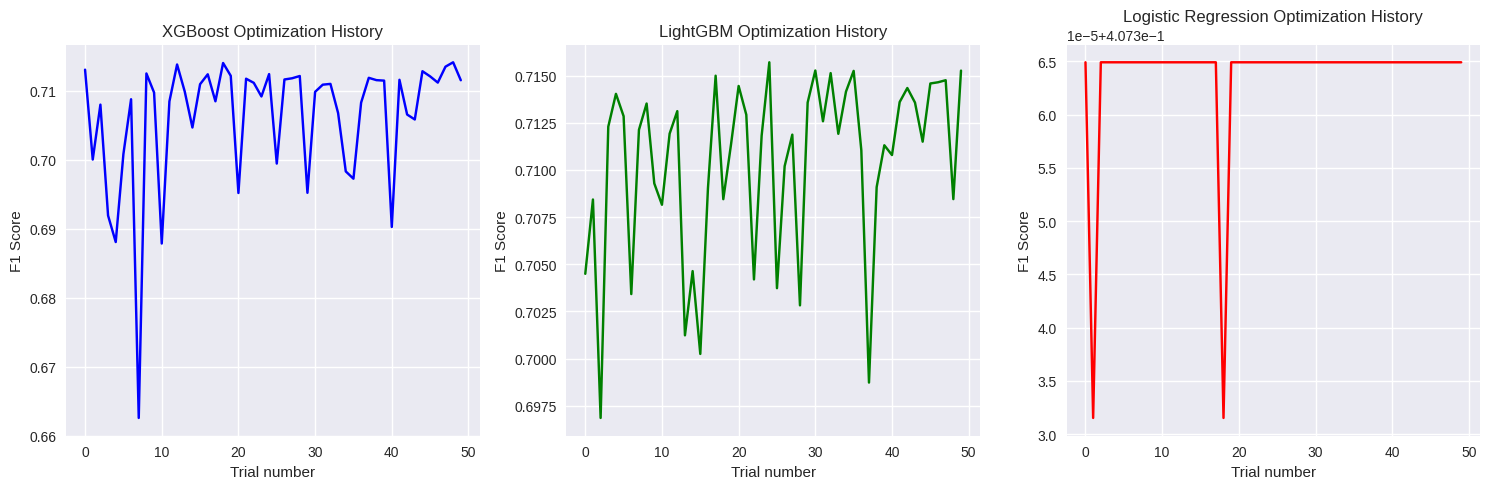


Optimization Summary:
--------------------
Number of trials completed:
XGBoost: 50
LightGBM: 50
Logistic Regression: 50

Best scores achieved:
XGBoost: 0.7141
LightGBM: 0.7157
Logistic Regression: 0.4074


In [ ]:
import optuna
from sklearn.metrics import f1_score
import xgboost as xgb
import lightgbm as lgb
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
import numpy as np


def objective_xgb(trial):
    param = {
        'max_depth': trial.suggest_int('max_depth', 3, 9),
        'learning_rate': trial.suggest_loguniform('learning_rate', 0.01, 0.3),
        'n_estimators': trial.suggest_int('n_estimators', 100, 500),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 7),
        'subsample': trial.suggest_uniform('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_uniform('colsample_bytree', 0.6, 1.0),
        'gamma': trial.suggest_loguniform('gamma', 1e-8, 1.0)
    }

    model = xgb.XGBClassifier(**param, random_state=42)
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='f1')
    return scores.mean()

print("Optimizing XGBoost...")
study_xgb = optuna.create_study(direction='maximize')
study_xgb.optimize(objective_xgb, n_trials=50, show_progress_bar=True)

print("\nBest XGBoost parameters:", study_xgb.best_params)
print("Best XGBoost F1 score:", study_xgb.best_value)


def objective_lgb(trial):
    param = {
        'num_leaves': trial.suggest_int('num_leaves', 20, 100),
        'learning_rate': trial.suggest_loguniform('learning_rate', 0.01, 0.3),
        'n_estimators': trial.suggest_int('n_estimators', 100, 500),
        'min_child_samples': trial.suggest_int('min_child_samples', 1, 50),
        'subsample': trial.suggest_uniform('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_uniform('colsample_bytree', 0.6, 1.0)
    }

    model = lgb.LGBMClassifier(**param, random_state=42)
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='f1')
    return scores.mean()
print("\nOptimizing LightGBM...")
study_lgb = optuna.create_study(direction='maximize')
study_lgb.optimize(objective_lgb, n_trials=50, show_progress_bar=True)

print("\nBest LightGBM parameters:", study_lgb.best_params)
print("Best LightGBM F1 score:", study_lgb.best_value)

def objective_lr(trial):
    param = {
        'C': trial.suggest_loguniform('C', 0.001, 100),
        'penalty': trial.suggest_categorical('penalty', ['l1', 'l2']),
        'solver': 'saga',  
        'max_iter': 1000
    }

    model = LogisticRegression(**param, random_state=42)
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='f1')
    return scores.mean()

print("\nOptimizing Logistic Regression...")
study_lr = optuna.create_study(direction='maximize')
study_lr.optimize(objective_lr, n_trials=50, show_progress_bar=True)

print("\nBest Logistic Regression parameters:", study_lr.best_params)
print("Best Logistic Regression F1 score:", study_lr.best_value)


best_xgb = xgb.XGBClassifier(**study_xgb.best_params, random_state=42)
best_lgb = lgb.LGBMClassifier(**study_lgb.best_params, random_state=42)
best_lr = LogisticRegression(**study_lr.best_params, random_state=42)


models = {
    'XGBoost': best_xgb,
    'LightGBM': best_lgb,
    'Logistic Regression': best_lr
}

print("\nFinal Model Evaluation:")
print("-----------------------")
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    f1 = f1_score(y_test, y_pred)
    print(f"\n{name} Test F1 Score: {f1:.4f}")


import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))


plt.subplot(131)
trials_xgb = study_xgb.trials_dataframe()
plt.plot(trials_xgb['number'], trials_xgb['value'], 'b-')
plt.title('XGBoost Optimization History')
plt.xlabel('Trial number')
plt.ylabel('F1 Score')

plt.subplot(132)
trials_lgb = study_lgb.trials_dataframe()
plt.plot(trials_lgb['number'], trials_lgb['value'], 'g-')
plt.title('LightGBM Optimization History')
plt.xlabel('Trial number')
plt.ylabel('F1 Score')

plt.subplot(133)
trials_lr = study_lr.trials_dataframe()
plt.plot(trials_lr['number'], trials_lr['value'], 'r-')
plt.title('Logistic Regression Optimization History')
plt.xlabel('Trial number')
plt.ylabel('F1 Score')

plt.tight_layout()
plt.show()


print("\nOptimization Summary:")
print("--------------------")
print(f"Number of trials completed:")
print(f"XGBoost: {len(study_xgb.trials)}")
print(f"LightGBM: {len(study_lgb.trials)}")
print(f"Logistic Regression: {len(study_lr.trials)}")

print("\nBest scores achieved:")
print(f"XGBoost: {study_xgb.best_value:.4f}")
print(f"LightGBM: {study_lgb.best_value:.4f}")
print(f"Logistic Regression: {study_lr.best_value:.4f}")

2. Answer this question:What makes Bayesian Optimization smart?

<b> <font color='red'>Your Answer:</font></b><br>

Bayesian Optimization is considered smart because it builds a probabilistic model (usually a Gaussian Process) of the objective function and uses this model to select the most promising hyperparameters to try next. Instead of blindly searching or exhaustively testing combinations like Grid or Random Search, it balances exploration (trying uncertain regions) and exploitation (focusing on areas likely to perform well).

# Step 13:Evaluation
This part of the project focuses on assessing the performance of the trained models. It involves comparing the model's predictions with the actual outcomes from the test dataset. This step helps determine how well each model generalizes to unseen data.

**Your Task**:

1.Answer this question: What are the formulas for Accuracy, Precision, Recall, F1-score?

<b> <font color='red'>Your Answer:</font></b><br>



* **Accuracy**:

$$
\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}
$$

* **Precision**:

$$
\text{Precision} = \frac{TP}{TP + FP}
$$

* **Recall (Sensitivity)**:

$$
\text{Recall} = \frac{TP}{TP + FN}
$$

* **F1-Score**:

$$
\text{F1-score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}
$$



2.Answer this question: What are the ROC Curve & AUC curve?

<b> <font color='red'>Your Answer:</font></b><br>

The ROC Curve (Receiver Operating Characteristic Curve) is a graphical plot that shows the performance of a binary classifier as its discrimination threshold varies. It plots the True Positive Rate (TPR or Recall) on the y-axis against the False Positive Rate (FPR) on the x-axis. The curve illustrates the trade-off between sensitivity and specificity.

The AUC (Area Under the Curve) represents the area under the ROC Curve. It summarizes the model’s ability to distinguish between classes:

AUC = 1.0 means perfect classification

AUC = 0.5 means no better than random guessing

Higher AUC indicates a better-performing model

3.Answer this question: What is a Confusion Matrix?

<b> <font color='red'>Your Answer:</font></b><br>

A confusion matrix is a table used to evaluate the performance of a classification model by showing the actual versus predicted classifications.

True Positives (TP): Correctly predicted positive cases

True Negatives (TN): Correctly predicted negative cases

False Positives (FP): Incorrectly predicted as positive (type I error)

False Negatives (FN): Incorrectly predicted as negative (type II error)

# Step 14: Cross-Validation (Optional)
To ensure the models generalize well to unseen data, you will use **cross-validation**. This technique splits the dataset into multiple subsets (folds), and each model is trained on different combinations of training and validation sets. This will give you a more robust estimate of the model's performance.

**"Note: You should implement cross-validation for only one model."**

Performing 5-fold cross-validation...
--------------------------------------------------
Fold 1 Results:
  Accuracy : 0.8781
  Precision: 0.7855
  Recall   : 0.6805
  F1-score : 0.7292
--------------------------------------------------
Fold 2 Results:
  Accuracy : 0.8649
  Precision: 0.7520
  Recall   : 0.6498
  F1-score : 0.6972
--------------------------------------------------
Fold 3 Results:
  Accuracy : 0.8698
  Precision: 0.7769
  Recall   : 0.6441
  F1-score : 0.7043
--------------------------------------------------
Fold 4 Results:
  Accuracy : 0.8750
  Precision: 0.7980
  Recall   : 0.6470
  F1-score : 0.7146
--------------------------------------------------
Fold 5 Results:
  Accuracy : 0.8722
  Precision: 0.7813
  Recall   : 0.6518
  F1-score : 0.7107
--------------------------------------------------

Average Metrics across all folds:
  Accuracy : 0.8720 (+/- 0.0045)
  Precision: 0.7787 (+/- 0.0151)
  Recall   : 0.6546 (+/- 0.0132)
  F1-score : 0.7112 (+/- 0.0108)


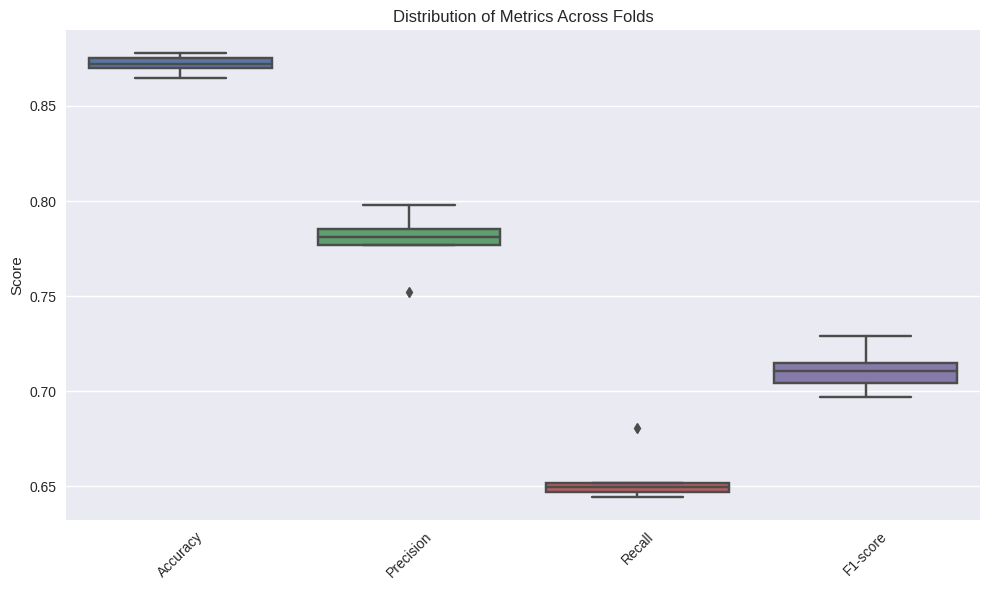

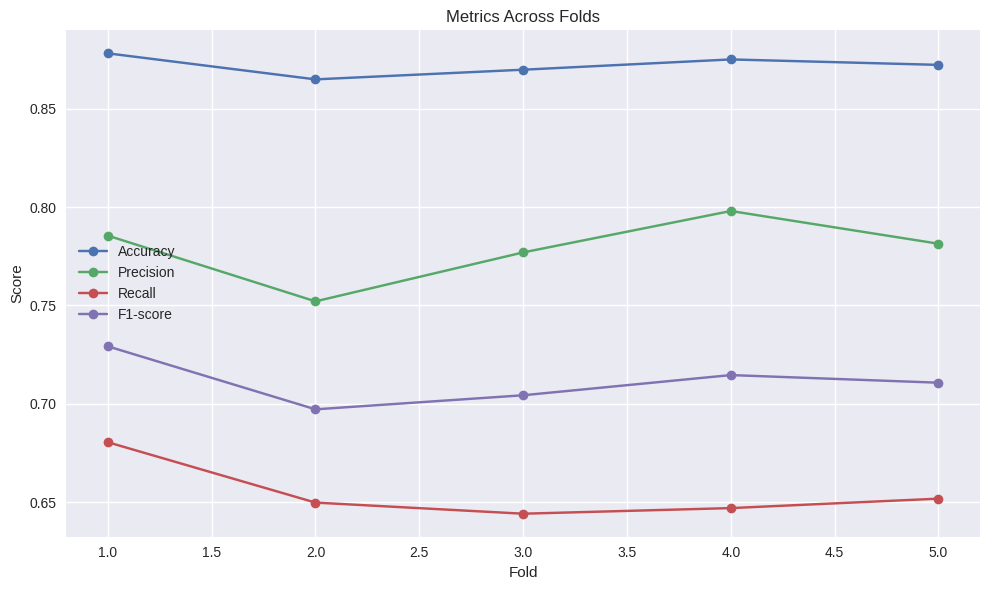

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from xgboost import XGBClassifier


xgb_clf = XGBClassifier(
    max_depth=6,
    learning_rate=0.1,
    n_estimators=200,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

n_folds = 5
kf = KFold(n_splits=n_folds, shuffle=True, random_state=42)


accuracies = []
precisions = []
recalls = []
f1_scores = []

print(f"Performing {n_folds}-fold cross-validation...")
print("-" * 50)

for fold, (train_idx, val_idx) in enumerate(kf.split(X_train), 1):
    X_fold_train = X_train.iloc[train_idx]
    y_fold_train = y_train.iloc[train_idx]
    X_fold_val   = X_train.iloc[val_idx]
    y_fold_val   = y_train.iloc[val_idx]

    xgb_clf.fit(X_fold_train, y_fold_train)
    y_pred = xgb_clf.predict(X_fold_val)

    accuracies.append( accuracy_score(y_fold_val, y_pred) )
    precisions.append( precision_score(y_fold_val, y_pred) )
    recalls.append(    recall_score(y_fold_val, y_pred) )
    f1_scores.append(  f1_score(y_fold_val, y_pred) )

    print(f"Fold {fold} Results:")
    print(f"  Accuracy : {accuracies[-1]:.4f}")
    print(f"  Precision: {precisions[-1]:.4f}")
    print(f"  Recall   : {recalls[-1]:.4f}")
    print(f"  F1-score : {f1_scores[-1]:.4f}")
    print("-" * 50)

print("\nAverage Metrics across all folds:")
print(f"  Accuracy : {np.mean(accuracies):.4f} (+/- {np.std(accuracies):.4f})")
print(f"  Precision: {np.mean(precisions):.4f} (+/- {np.std(precisions):.4f})")
print(f"  Recall   : {np.mean(recalls):.4f} (+/- {np.std(recalls):.4f})")
print(f"  F1-score : {np.mean(f1_scores):.4f} (+/- {np.std(f1_scores):.4f})")

metrics_df = pd.DataFrame({
    'Accuracy':  accuracies,
    'Precision': precisions,
    'Recall':    recalls,
    'F1-score':  f1_scores
})


plt.figure(figsize=(10, 6))
sns.boxplot(data=metrics_df)
plt.title('Distribution of Metrics Across Folds')
plt.ylabel('Score')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
for col in metrics_df.columns:
    plt.plot(
        range(1, n_folds+1),
        metrics_df[col],
        marker='o',
        label=col
    )
plt.title('Metrics Across Folds')
plt.xlabel('Fold')
plt.ylabel('Score')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# Step 15: Model Comparison
After evaluating all the models, you will compare them based on their performance metrics. The goal is to select the best model that performs well across multiple metrics and generalizes effectively to unseen data.

(Optional) you should apply **statistical tests** (such as **McNemar’s test**) to assess whether differences between model performances are statistically significant. This will help ensure the selection of the optimal model is based on solid evidence.

=== Model Performance Metrics ===
   Accuracy  Precision    Recall  F1-score
0  0.878090   0.785452  0.680458  0.729195
1  0.864865   0.752042  0.649775  0.697178
2  0.869779   0.776923  0.644133  0.704324
3  0.875000   0.797964  0.646984  0.714586
4  0.872236   0.781346  0.651786  0.710709

Statistically Significant Differences (α=0.05):
  XGBoost vs LightGBM: p = 0.0182
  XGBoost vs Logistic Regression: p = 0.0000
  XGBoost vs SVM: p = 0.0000
  XGBoost vs Neural Network: p = 0.0000
  LightGBM vs Logistic Regression: p = 0.0000
  LightGBM vs SVM: p = 0.0000
  LightGBM vs Neural Network: p = 0.0000
  Logistic Regression vs Neural Network: p = 0.0000
  SVM vs Neural Network: p = 0.0000

=== Model Rankings (1=best) ===
   Accuracy  Precision  Recall  F1-score  Average Rank
0       1.0        2.0     1.0       1.0          1.25
3       2.0        1.0     4.0       2.0          2.25
4       3.0        3.0     2.0       3.0          2.75
2       4.0        4.0     5.0       4.0          4.2

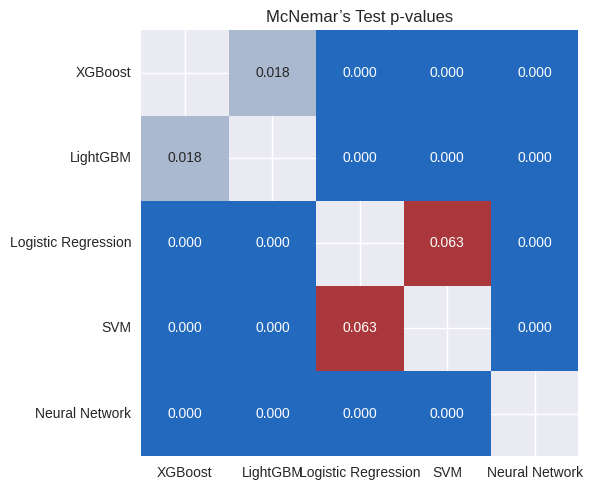

In [ ]:


import pandas as pd
import numpy as np
from statsmodels.stats.contingency_tables import mcnemar

print("=== Model Performance Metrics ===")
print(metrics_df)

alpha = 0.05
significant = []
model_names = list(best_models.keys())

for i in range(len(model_names)):
    for j in range(i+1, len(model_names)):
        m1, m2 = model_names[i], model_names[j]
        p = mcnemar_results.loc[m1, m2]
        if p < alpha:
            significant.append((m1, m2, p))

if significant:
    print("\nStatistically Significant Differences (α=0.05):")
    for m1, m2, p in significant:
        print(f"  {m1} vs {m2}: p = {p:.4f}")
else:
    print("\nNo statistically significant differences detected.")

rankings = {
    metric: metrics_df[metric].rank(ascending=False)
    for metric in metrics_df.columns if metric!='ROC-AUC'
}
rank_df = pd.DataFrame(rankings)
rank_df['Average Rank'] = rank_df.mean(axis=1)
rank_df = rank_df.sort_values('Average Rank')

print("\n=== Model Rankings (1=best) ===")
print(rank_df)


best = rank_df.index[0]
print(f"\nBest Overall Model: {best}")
print(metrics_df.loc[best])
import torch
import numpy as np
import pandas as pd
from statsmodels.stats.contingency_tables import mcnemar
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve
)

def _nn_predict_proba(self, X):

    X_tensor = torch.tensor(X, dtype=torch.float32).cuda()
    self.model.eval()
    with torch.no_grad():
        logits = self.model(X_tensor)
    probs = torch.softmax(logits, dim=1).cpu().numpy()
    return probs

SimpleNN.predict_proba = _nn_predict_proba

predictions   = {}
probabilities = {}

for name, model in best_models.items():
    y_pred     = model.predict(X_test_np)
    y_proba_all = model.predict_proba(X_test_np)  
  
    if hasattr(y_proba_all, "to_numpy"):
        y_proba_all = y_proba_all.to_numpy()
    y_proba = y_proba_all[:, 1]

    predictions[name]   = y_pred
    probabilities[name] = y_proba

metrics = {}
for name in best_models:
    y_pred = predictions[name]
    y_proba = probabilities[name]
    metrics[name] = {
        'Accuracy':  accuracy_score(y_test_np, y_pred),
        'Precision': precision_score(y_test_np, y_pred),
        'Recall':    recall_score(y_test_np, y_pred),
        'F1-score':  f1_score(y_test_np, y_pred),
        'ROC-AUC':   roc_auc_score(y_test_np, y_proba)
    }

metrics_df = pd.DataFrame(metrics).T
print("=== Test‐Set Performance ===")
print(metrics_df)


model_names = list(best_models.keys())
mcnemar_p = pd.DataFrame(index=model_names, columns=model_names, dtype=float)

for i in range(len(model_names)):
    for j in range(i+1, len(model_names)):
        m1, m2 = model_names[i], model_names[j]
        tbl = pd.crosstab(
            predictions[m1] == y_test_np,
            predictions[m2] == y_test_np
        )
        pval = mcnemar(tbl, exact=True).pvalue
        mcnemar_p.loc[m1, m2] = pval
        mcnemar_p.loc[m2, m1] = pval

print("\n=== McNemar’s Test p-values ===")
print(mcnemar_p)


alpha = 0.05
print("\nSignificant differences (p < 0.05):")
for i in range(len(model_names)):
    for j in range(i+1, len(model_names)):
        p = mcnemar_p.iloc[i, j]
        tag = "SIGNIFICANT" if p < alpha else "n.s."
        print(f"{model_names[i]} vs {model_names[j]}: p={p:.4f} → {tag}")

plt.figure(figsize=(6, 5))
sns.heatmap(mcnemar_p.astype(float), annot=True, fmt=".3f", cmap="vlag", cbar=False)
plt.title("McNemar’s Test p-values")
plt.tight_layout()
plt.show()


## Step 17: Conclusion
At the end of this step, you will identify the best-performing model based on the evaluation metrics. You should then decide if further improvements (e.g., feature engineering, model ensembling) are necessary to achieve better results.

A confusion matrix is a table used to evaluate the performance of a classification model by showing the actual versus predicted classifications. It summarizes the results into four categories:

True Positives (TP): Correctly predicted positive cases

True Negatives (TN): Correctly predicted negative cases

False Positives (FP): Incorrectly predicted as positive (type I error)

False Negatives (FN): Incorrectly predicted as negative (type II error)